In [2]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(reshape2)
library(RColorBrewer)
library(readr)
library(Matrix)
library(dplyr)
library(tidyr)
library(tibble)
library(ggplot2)
library(ggpubr)
library(rstatix)
library(ggrepel)
library(grid)
library(future)
library(furrr)
library(purrr)


ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Warning message:
“package ‘Matrix’ was built under R version 4.6.1”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘tidyr’


The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack


The following object is masked from ‘package:reshape2’:

    smiths



Attaching package: ‘rstatix’


The following object is masked from ‘package:stat

# Load datasets

In [5]:
gut_allt_5p <- readRDS("../241201_VN_PREDICT2/data/cdn/gut_allt_5p_integrated.rds")

In [6]:
gut_allt_5p  <- FindClusters(gut_allt_5p, res = c(0.2))

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 588063
Number of edges: 13479680

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9525
Number of communities: 10
Elapsed time: 702 seconds


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



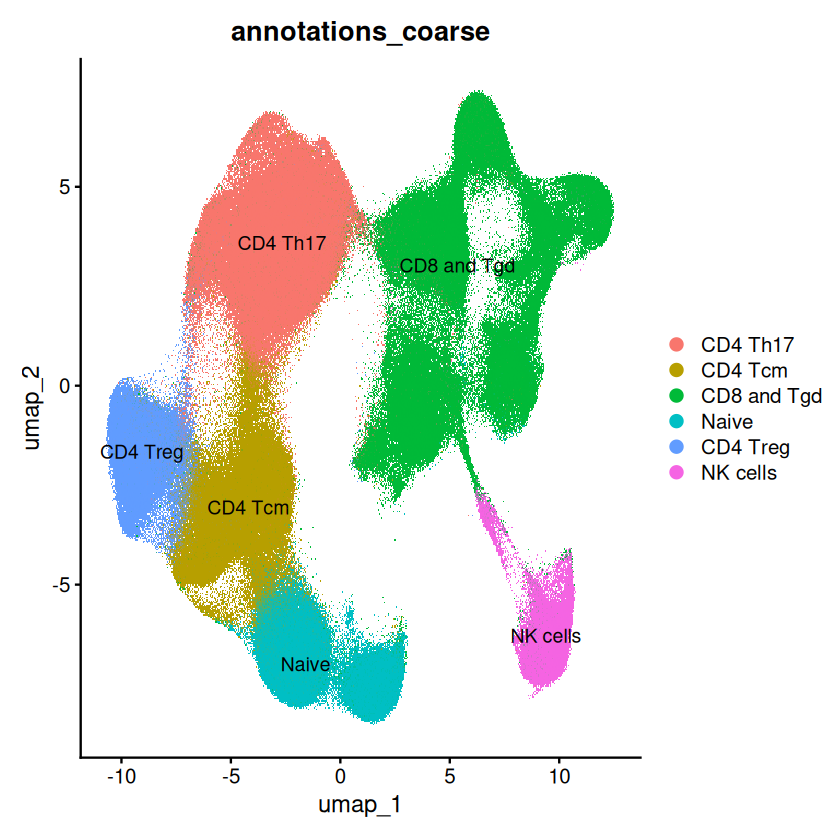

In [7]:
gut_allt_5p@meta.data <- gut_allt_5p@meta.data  %>% mutate(annotations_coarse = recode_factor(integrated_snn_res.0.2, 
"0" = "CD4 Th17",                                                                         
"1" = "CD4 Tcm",
"2" = "CD8 and Tgd",
"3" = "Naive",
"4" = "CD4 Treg",
"5" = "CD8 and Tgd",
"6" = "CD8 and Tgd",
"7" = "CD8 and Tgd",
"8" = "NK cells",
"9" = "Naive"))

DimPlot(gut_allt_5p, group.by = "annotations_coarse", label = T)

In [39]:
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,4370236,233.4,13895381,742.1,13895381,742.1
Vcells,14229271,108.6,11530724426,87972.5,11083158721,84557.8


In [40]:
gut_allt_3p <- readRDS("../241201_VN_PREDICT2/gut_3p_integrated_with_healthy_filt_without_ilc_v2.rds")

In [41]:
gut_allt_3p@reductions$umap@cell.embeddings[,1]  <- -1*gut_allt_3p@reductions$umap@cell.embeddings[,1]

In [42]:
gut_allt_3p@reductions$umap@cell.embeddings[,2]  <- -1*gut_allt_3p@reductions$umap@cell.embeddings[,2]

In [43]:
gut_allt_3p@meta.data <- gut_allt_3p@meta.data  %>% mutate(annotations_coarse = 
                                                                       recode_factor(integrated_snn_res.0.3, 
"0" = "CD4 Th17",                                                                         
"1" = "Naive",
"2" = "CD8 and Tgd",
"3" = "CD4 Tcm",
"4" = "CD4 Treg",
"5" = "CD8 and Tgd",
"6" = "CD8 and Tgd",
"7" = "NK cells",
"8" = "CD4 Tcm",
"9" = "CD4 Th17",
"10" = "CD8 and Tgd"))

In [44]:
gut_allt_3p@meta.data  %>% group_by(annotations_coarse, patient, disease)  %>% tally()  %>% dplyr::filter(disease == "HEA")

annotations_coarse,patient,disease,n
<fct>,<chr>,<chr>,<int>
CD4 Th17,HE-001-014,HEA,124
CD4 Th17,HE-001-023,HEA,108
CD4 Th17,HE-001-024,HEA,58
CD4 Th17,HE-001-025,HEA,41
CD4 Th17,HE-001-026,HEA,163
Naive,HE-001-014,HEA,709
Naive,HE-001-023,HEA,385
Naive,HE-001-024,HEA,15
Naive,HE-001-025,HEA,23


# Patient-level 3p

## Filtering pseudobulk samples 3p

In [45]:
gut_allt_3p$data_folder  <- gut_allt_3p$smp_id2

In [46]:
gut_allt_3p$cluster_sample  <- paste(gut_allt_3p$annotations_coarse, gut_allt_3p$data_folder, sep = "__")

In [47]:
gut_allt_3p@meta.data  %>% group_by(cluster_sample)  %>% tally()  %>% 
arrange(n)  %>% mutate(keep = n>19)  %>% group_by(keep)  %>% tally 

keep,n
<lgl>,<int>
FALSE,233
TRUE,738


In [48]:
keep_samples  <- gut_allt_3p@meta.data  %>% group_by(cluster_sample)  %>% tally()  %>% 
arrange(n)  %>% dplyr::filter(n>19)  %>% pull(cluster_sample)

In [49]:
length(keep_samples)

[1] 738

In [50]:
genes  <- rownames(gut_allt_3p@assays$RNA)

In [51]:
genes_filt_3p  <- genes[!(grepl(genes, pattern = "^MT")|
                            grepl(genes, pattern = "\\.")|
                            grepl(genes, pattern = "LINC")|
                            grepl(genes, pattern = "^MIR")|
                            grepl(genes, pattern = "^MT")|
                            grepl(genes, pattern = "HNRNP")|
                            grepl(genes, pattern = "^RP[LS]")|
                            grepl(genes, pattern = "\\-")|
                            grepl(genes, pattern = "TTTY")|
                            grepl(genes, pattern = "ORF")|
                            grepl(genes, pattern = "orf"))
                            ]


In [52]:
gut_allt_3p$keep_pseudobulk <- gut_allt_3p$cluster_sample %in% keep_samples & gut_allt_3p$time %in% c("T0","T0D")

In [53]:
gut_allt_3p$keep_pseudobulk   %>% table

.
 FALSE   TRUE 
 12280 270997 

In [54]:
gut_allt_3p@meta.data  %>% colnames

[1] "SingleR_HPCA"           "nCount_RNA"             "nFeature_RNA"          
 [4] "RNA_snn_res.0.3"        "seurat_clusters"        "orig.ident"            
 [7] "smp_id"                 "percent.mt"             "patient"               
[10] "time"                   "tissue"                 "layer"                 
[13] "prime"                  "RNA_snn_res.0.2"        "RNA_snn_res.0.6"       
[16] "RNA_snn_res.0.7"        "RNA_snn_res.0.8"        "manual_annotation"     
[19] "smp_id2"                "disease"                "antiTNF_response"      
[22] "barcode"                "integrated_snn_res.0.3" "integrated_snn_res.0.5"
[25] "integrated_snn_res.0.7" "integrated_snn_res.0.9" "annotations_coarse"    
[28] "data_folder"            "cluster_sample"         "keep_pseudobulk"

In [55]:
aggexp_3p  <- AggregateExpression(subset(gut_allt_3p, keep_pseudobulk == TRUE), 
                                  group.by = c("cluster_sample"), 
                                  features = genes_filt_3p, return.seurat = T)

Warning message:
“The counts layer for the integrated assay is empty. Skipping assay.”


In [56]:
md_to_join  <- gut_allt_3p@meta.data  %>% 
group_by(cluster_sample, annotations_coarse, timepoint = time, tissue, layer, participant_id = patient,
                                                  diagnosis = disease, antitnf_response = antiTNF_response)  %>% 
tally()  %>% 
dplyr::select(-n)  %>% 
ungroup  %>% 
mutate(cluster_sample = gsub(cluster_sample, pattern = "_", replacement = "-"))

In [57]:
md  <- aggexp_3p@meta.data  %>% left_join(md_to_join)

Joining with `by = join_by(cluster_sample)`


In [58]:
rownames(md)  <- colnames(aggexp_3p)

In [59]:
aggexp_3p@meta.data  <- md

In [60]:
aggexp_3p$tissue_layer  <- ifelse(aggexp_3p$layer == 'EPI','EPI',paste(aggexp_3p$tissue, aggexp_3p$layer))

In [61]:
ls()

[1] "aggexp_3p"             "aggexp_5p"             "annots"               
 [4] "colour_max"            "comparisons"           "deg_all_tissues_deseq"
 [7] "deg_counts"            "ds_sub"                "files"                
[10] "genes"                 "genes_filt_3p"         "genes_filt_5p"        
[13] "ggtheme"               "gut_allt_3p"           "jobs"                 
[16] "keep_samples"          "loaded"                "md"                   
[19] "md_to_join"            "out_dir"               "p"                    
[22] "plot_df"               "pt_3p"                 "result_dirs"          
[25] "test_name"             "tissue_layers"         "tl"

## Finding DEG on pseudobulk object

In [62]:
# Use the full pseudobulk object
ds_sub <- aggexp_3p

ds_sub$diagnosis2 <- ifelse(
  ds_sub$diagnosis %in% c("UC", "CD"),
  "IBD",
  "NonIBD"
)

annots <- levels(factor(ds_sub$annotations_coarse))
tissue_layers <- c("COL LP", "ILE LP", "DUO LP", "EPI")

# EPI includes all tissues with layer == "EPI"
ds_sub$tissue_layer <- ifelse(
  ds_sub$layer == "EPI",
  "EPI",
  paste(ds_sub$tissue, ds_sub$layer)
)

In [63]:
comparisons <- data.frame(
  test = c(
    "IBD_vs_NonIBD",
    "UC_vs_FGID",
    "CD_vs_FGID",
    "UC_vs_HEA",
    "CD_vs_HEA"
  ),
  identity_column = c(
    "diagnosis2",
    rep("diagnosis", 4)
  ),
  ident1 = c("IBD", "UC", "CD", "UC", "CD"),
  ident2 = c("NonIBD", "FGID", "FGID", "HEA", "HEA"),
  stringsAsFactors = FALSE
)

In [64]:
jobs <- expand.grid(
  annotation = annots,
  tissue_layer = tissue_layers,
  stringsAsFactors = FALSE
)

out_dir <- file.path(
  "tables",
  paste0("deg_patient_level_3p_", format(Sys.time(), "%Y%m%d_%H%M%S"))
)

In [317]:
# Create separate folders for every tissue/layer and comparison
for (tl in tissue_layers) {
  for (test_name in comparisons$test) {
    dir.create(
      file.path(out_dir, tl, test_name),
      recursive = TRUE,
      showWarnings = FALSE
    )
  }
}

stopifnot(is.character(genes))

In [318]:

plan(sequential)

# Extract counts once, avoiding subset() on the full Seurat object
counts_all <- GetAssayData(
  ds_sub,
  assay = "RNA",
  layer = "counts"
)

metadata_all <- ds_sub[[]]

stopifnot(
  length(dim(counts_all)) == 2L,
  !is.null(rownames(counts_all)),
  !is.null(colnames(counts_all)),
  !anyNA(rownames(counts_all)),
  !anyNA(colnames(counts_all)),
  all(nzchar(rownames(counts_all))),
  all(nzchar(colnames(counts_all))),
  anyDuplicated(rownames(counts_all)) == 0L,
  anyDuplicated(colnames(counts_all)) == 0L,
  all(colnames(counts_all) %in% rownames(metadata_all)),
  all(c("annotations_coarse", "tissue_layer") %in% names(metadata_all)),
  all(comparisons$identity_column %in% names(metadata_all)),
  is.character(genes)
)

# Align metadata with the count matrix
metadata_all <- metadata_all[colnames(counts_all), , drop = FALSE]

# Create output directories
for (tl in unique(jobs$tissue_layer)) {
  for (test_name in comparisons$test) {
    dir.create(
      file.path(out_dir, tl, test_name),
      recursive = TRUE,
      showWarnings = FALSE
    )
  }
}

options(future.globals.maxSize = 16 * 1024^3)
plan(multisession, workers = 12)

# Reset the parallel plan even if a job fails
tryCatch(
  {
    future_walk(
      seq_len(nrow(jobs)),
      function(job_id) {
        future::plan(future::sequential)

        annot_use <- jobs$annotation[job_id]
        tl_use <- jobs$tissue_layer[job_id]

        label <- paste0(
          "[Job ", job_id, ": ", annot_use, " / ", tl_use, "]"
        )

        stage <- "starting"

        log_stage <- function(text) {
          message(label, " ", text)
        }

        tryCatch({

          stage <- "selecting sample names"
          log_stage(paste("START:", stage))

          cells_use <- rownames(metadata_all)[
            which(
              metadata_all$annotations_coarse == annot_use &
              metadata_all$tissue_layer == tl_use
            )
          ]

          log_stage(paste("Selected samples:", length(cells_use)))

          # At least 3 samples per group requires at least 6 total
          if (length(cells_use) < 6L) {
            log_stage("SKIPPED: fewer than 6 samples in total")
            return(invisible(NULL))
          }

          stage <- "extracting and rounding counts"
          log_stage(paste("START:", stage))

          counts <- round(counts_all[, cells_use, drop = FALSE])
          metadata <- metadata_all[colnames(counts), , drop = FALSE]

          stopifnot(
            length(dim(counts)) == 2L,
            !is.null(rownames(counts)),
            !is.null(colnames(counts)),
            identical(colnames(counts), rownames(metadata))
          )

          log_stage(paste(
            "Counts:", nrow(counts), "genes x",
            ncol(counts), "samples"
          ))

          stage <- "filtering genes detected in at least 3 samples"
          log_stage(paste("START:", stage))

          keep_genes <- Matrix::rowSums(counts > 0) >= 3L

          log_stage(paste(
            "Genes passing the 3-sample filter:",
            sum(keep_genes)
          ))

          if (!any(keep_genes)) {
            log_stage("SKIPPED: no genes pass the 3-sample filter")
            return(invisible(NULL))
          }

          counts <- counts[keep_genes, , drop = FALSE]

          stage <- "CreateSeuratObject"
          log_stage(paste("START:", stage))

          # Filtering was already applied explicitly above
          sub <- CreateSeuratObject(
            counts = counts,
            meta.data = metadata,
            assay = "RNA",
            min.cells = 0,
            min.features = 0
          )

          log_stage(paste(
            "Object created:",
            nrow(sub), "features;",
            ncol(sub), "samples"
          ))

          stage <- "NormalizeData"
          log_stage(paste("START:", stage))

          sub <- NormalizeData(sub, verbose = FALSE)

          log_stage("Normalization completed")

          stage <- "selecting genes_use"
          log_stage(paste("START:", stage))

          genes_use <- intersect(genes, rownames(counts))

          log_stage(paste(
            "Requested genes available:", length(genes_use)
          ))

          if (length(genes_use) == 0L) {
            log_stage("SKIPPED: no requested genes available")
            return(invisible(NULL))
          }

          for (test_id in seq_len(nrow(comparisons))) {
            cmp <- comparisons[test_id, ]

            stage <- paste("setting identities for", cmp$test)
            log_stage(paste("START:", stage))

            Idents(sub) <- sub[[cmp$identity_column, drop = TRUE]]

            n1 <- sum(Idents(sub) == cmp$ident1, na.rm = TRUE)
            n2 <- sum(Idents(sub) == cmp$ident2, na.rm = TRUE)

            log_stage(paste(
              cmp$test, ":",
              cmp$ident1, "=", n1, ";",
              cmp$ident2, "=", n2
            ))

            if (n1 < 3L || n2 < 3L) {
              log_stage(paste(
                "SKIPPED:", cmp$test,
                "— fewer than 3 samples in one group"
              ))
              next
            }

            stage <- paste("FindMarkers:", cmp$test)
            log_stage(paste("START:", stage))

            deg <- Seurat::FindMarkers(
              sub,
              assay = "RNA",
              ident.1 = cmp$ident1,
              ident.2 = cmp$ident2,
              features = genes_use,
              slot = "counts",
              test.use = "DESeq2",
              min.pct = 0.2,
              min.cells.feature = 5
            )
              
            log_stage(paste(
              "FindMarkers completed:", nrow(deg), "rows"
            ))

            stage <- paste("adding result metadata:", cmp$test)

            nr <- nrow(deg)
            deg$gene <- rownames(deg)
            deg$test <- rep(cmp$test, nr)
            deg$annotation <- rep(annot_use, nr)
            deg$tissue_layer <- rep(tl_use, nr)
            deg$tissue <- rep(
              if (tl_use == "EPI") {
                NA_character_
              } else {
                base::sub(" LP$", "", tl_use)
              },
              nr
            )
            deg$layer <- rep(
              if (tl_use == "EPI") "EPI" else "LP",
              nr
            )

            stage <- paste("writing CSV:", cmp$test)
            log_stage(paste("START:", stage))

            write.csv(
              deg,
              file = file.path(
                out_dir,
                tl_use,
                cmp$test,
                paste0(annot_use, ".csv")
              ),
              row.names = FALSE
            )

            log_stage(paste("Saved:", cmp$test))
          }

          log_stage("JOB COMPLETED")

        }, error = function(e) {
          stop(
            label,
            "\nFAILED AT: ", stage,
            "\nORIGINAL ERROR: ", conditionMessage(e),
            call. = FALSE
          )
        })
      },
      .options = furrr_options(
        packages = c("Seurat", "DESeq2"),
        seed = 123
      )
    )
  },
  finally = {
    plan(sequential)
  }
)

[Job 1: CD4 Th17 / COL LP] START: selecting sample names

[Job 1: CD4 Th17 / COL LP] Selected samples: 40

[Job 1: CD4 Th17 / COL LP] START: extracting and rounding counts

[Job 1: CD4 Th17 / COL LP] Counts: 17455 genes x 40 samples

[Job 1: CD4 Th17 / COL LP] START: filtering genes detected in at least 3 samples

[Job 1: CD4 Th17 / COL LP] Genes passing the 3-sample filter: 13947

[Job 1: CD4 Th17 / COL LP] START: CreateSeuratObject

[Job 1: CD4 Th17 / COL LP] Object created: 13947 features; 40 samples

[Job 1: CD4 Th17 / COL LP] START: NormalizeData

[Job 1: CD4 Th17 / COL LP] Normalization completed

[Job 1: CD4 Th17 / COL LP] START: selecting genes_use

[Job 1: CD4 Th17 / COL LP] Requested genes available: 13947

[Job 1: CD4 Th17 / COL LP] START: setting identities for IBD_vs_NonIBD

[Job 1: CD4 Th17 / COL LP] IBD_vs_NonIBD : IBD = 19 ; NonIBD = 21

[Job 1: CD4 Th17 / COL LP] START: FindMarkers: IBD_vs_NonIBD

converting counts to integer mode

gene-wise dispersion estimates

mean-

mean-dispersion relationship

final dispersion estimates

[Job 3: CD8 and Tgd / COL LP] FindMarkers completed: 12986 rows

[Job 3: CD8 and Tgd / COL LP] START: writing CSV: CD_vs_HEA

[Job 3: CD8 and Tgd / COL LP] Saved: CD_vs_HEA

[Job 3: CD8 and Tgd / COL LP] JOB COMPLETED

[Job 4: CD4 Tcm / COL LP] START: selecting sample names

[Job 4: CD4 Tcm / COL LP] Selected samples: 40

[Job 4: CD4 Tcm / COL LP] START: extracting and rounding counts

[Job 4: CD4 Tcm / COL LP] Counts: 17455 genes x 40 samples

[Job 4: CD4 Tcm / COL LP] START: filtering genes detected in at least 3 samples

[Job 4: CD4 Tcm / COL LP] Genes passing the 3-sample filter: 13533

[Job 4: CD4 Tcm / COL LP] START: CreateSeuratObject

[Job 4: CD4 Tcm / COL LP] Object created: 13533 features; 40 samples

[Job 4: CD4 Tcm / COL LP] START: NormalizeData

[Job 4: CD4 Tcm / COL LP] Normalization completed

[Job 4: CD4 Tcm / COL LP] START: selecting genes_use

[Job 4: CD4 Tcm / COL LP] Requested genes available: 13533

[Job 4: 

[Job 6: NK cells / COL LP] Saved: CD_vs_FGID

[Job 6: NK cells / COL LP] START: setting identities for UC_vs_HEA

[Job 6: NK cells / COL LP] UC_vs_HEA : UC = 3 ; HEA = 4

[Job 6: NK cells / COL LP] START: FindMarkers: UC_vs_HEA

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 6: NK cells / COL LP] FindMarkers completed: 11097 rows

[Job 6: NK cells / COL LP] START: writing CSV: UC_vs_HEA

[Job 6: NK cells / COL LP] Saved: UC_vs_HEA

[Job 6: NK cells / COL LP] START: setting identities for CD_vs_HEA

[Job 6: NK cells / COL LP] CD_vs_HEA : CD = 15 ; HEA = 4

[Job 6: NK cells / COL LP] START: FindMarkers: CD_vs_HEA

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 6: NK cells / COL LP] FindMarkers completed: 11695 rows

[Job 6: NK cells / COL LP] START: writing CSV: CD_vs_HEA

[Job 6: NK cells / COL LP] Saved: CD_vs_HEA

[Job 6:

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 9: CD8 and Tgd / ILE LP] FindMarkers completed: 13357 rows

[Job 9: CD8 and Tgd / ILE LP] START: writing CSV: IBD_vs_NonIBD

[Job 9: CD8 and Tgd / ILE LP] Saved: IBD_vs_NonIBD

[Job 9: CD8 and Tgd / ILE LP] START: setting identities for UC_vs_FGID

[Job 9: CD8 and Tgd / ILE LP] UC_vs_FGID : UC = 4 ; FGID = 14

[Job 9: CD8 and Tgd / ILE LP] START: FindMarkers: UC_vs_FGID

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 9: CD8 and Tgd / ILE LP] FindMarkers completed: 13514 rows

[Job 9: CD8 and Tgd / ILE LP] START: writing CSV: UC_vs_FGID

[Job 9: CD8 and Tgd / ILE LP] Saved: UC_vs_FGID

[Job 9: CD8 and Tgd / ILE LP] START: setting identities for CD_vs_FGID

[Job 9: CD8 and Tgd / ILE LP] CD_vs_FGID : CD = 14 ; FGID = 14

[Job 9: CD8 and Tgd / ILE LP] START: FindMarkers: CD_vs_FGI

[Job 11: CD4 Treg / ILE LP] START: setting identities for CD_vs_HEA

[Job 11: CD4 Treg / ILE LP] CD_vs_HEA : CD = 14 ; HEA = 4

[Job 11: CD4 Treg / ILE LP] START: FindMarkers: CD_vs_HEA

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 11: CD4 Treg / ILE LP] FindMarkers completed: 12889 rows

[Job 11: CD4 Treg / ILE LP] START: writing CSV: CD_vs_HEA

[Job 11: CD4 Treg / ILE LP] Saved: CD_vs_HEA

[Job 11: CD4 Treg / ILE LP] JOB COMPLETED

[Job 12: NK cells / ILE LP] START: selecting sample names

[Job 12: NK cells / ILE LP] Selected samples: 38

[Job 12: NK cells / ILE LP] START: extracting and rounding counts

[Job 12: NK cells / ILE LP] Counts: 17455 genes x 38 samples

[Job 12: NK cells / ILE LP] START: filtering genes detected in at least 3 samples

[Job 12: NK cells / ILE LP] Genes passing the 3-sample filter: 12638

[Job 12: NK cells / ILE LP] START: CreateSeuratObject

[Job 12: NK cells / ILE LP] Obj

[Job 15: CD8 and Tgd / DUO LP] FindMarkers completed: 13172 rows

[Job 15: CD8 and Tgd / DUO LP] START: writing CSV: UC_vs_FGID

[Job 15: CD8 and Tgd / DUO LP] Saved: UC_vs_FGID

[Job 15: CD8 and Tgd / DUO LP] START: setting identities for CD_vs_FGID

[Job 15: CD8 and Tgd / DUO LP] CD_vs_FGID : CD = 14 ; FGID = 16

[Job 15: CD8 and Tgd / DUO LP] START: FindMarkers: CD_vs_FGID

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 15: CD8 and Tgd / DUO LP] FindMarkers completed: 13302 rows

[Job 15: CD8 and Tgd / DUO LP] START: writing CSV: CD_vs_FGID

[Job 15: CD8 and Tgd / DUO LP] Saved: CD_vs_FGID

[Job 15: CD8 and Tgd / DUO LP] START: setting identities for UC_vs_HEA

[Job 15: CD8 and Tgd / DUO LP] UC_vs_HEA : UC = 4 ; HEA = 4

[Job 15: CD8 and Tgd / DUO LP] START: FindMarkers: UC_vs_HEA

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimat

[Job 18: NK cells / DUO LP] START: selecting genes_use

[Job 18: NK cells / DUO LP] Requested genes available: 11534

[Job 18: NK cells / DUO LP] START: setting identities for IBD_vs_NonIBD

[Job 18: NK cells / DUO LP] IBD_vs_NonIBD : IBD = 17 ; NonIBD = 15

[Job 18: NK cells / DUO LP] START: FindMarkers: IBD_vs_NonIBD

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 18: NK cells / DUO LP] FindMarkers completed: 10676 rows

[Job 18: NK cells / DUO LP] START: writing CSV: IBD_vs_NonIBD

[Job 18: NK cells / DUO LP] Saved: IBD_vs_NonIBD

[Job 18: NK cells / DUO LP] START: setting identities for UC_vs_FGID

[Job 18: NK cells / DUO LP] UC_vs_FGID : UC = 4 ; FGID = 9

[Job 18: NK cells / DUO LP] START: FindMarkers: UC_vs_FGID

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 18: NK cells / DUO LP] FindMarkers completed: 10527 rows


[Job 22: CD4 Tcm / EPI] Normalization completed

[Job 22: CD4 Tcm / EPI] START: selecting genes_use

[Job 22: CD4 Tcm / EPI] Requested genes available: 10235

[Job 22: CD4 Tcm / EPI] START: setting identities for IBD_vs_NonIBD

[Job 22: CD4 Tcm / EPI] IBD_vs_NonIBD : IBD = 8 ; NonIBD = 1

[Job 22: CD4 Tcm / EPI] SKIPPED: IBD_vs_NonIBD — fewer than 3 samples in one group

[Job 22: CD4 Tcm / EPI] START: setting identities for UC_vs_FGID

[Job 22: CD4 Tcm / EPI] UC_vs_FGID : UC = 4 ; FGID = 1

[Job 22: CD4 Tcm / EPI] SKIPPED: UC_vs_FGID — fewer than 3 samples in one group

[Job 22: CD4 Tcm / EPI] START: setting identities for CD_vs_FGID

[Job 22: CD4 Tcm / EPI] CD_vs_FGID : CD = 4 ; FGID = 1

[Job 22: CD4 Tcm / EPI] SKIPPED: CD_vs_FGID — fewer than 3 samples in one group

[Job 22: CD4 Tcm / EPI] START: setting identities for UC_vs_HEA

[Job 22: CD4 Tcm / EPI] UC_vs_HEA : UC = 4 ; HEA = 0

[Job 22: CD4 Tcm / EPI] SKIPPED: UC_vs_HEA — fewer than 3 samples in one group

[Job 22: CD4 Tcm / EP

## Testing summary

In [65]:
out_dir  <- "tables/deg_patient_level_3p_20261019_090412/"

In [66]:
test_status <- expand.grid(
  job_id = seq_len(nrow(jobs)),
  test_id = seq_len(nrow(comparisons))
) %>%
  mutate(
    annotation = jobs$annotation[job_id],
    tissue_layer = jobs$tissue_layer[job_id],
    test = comparisons$test[test_id],
    file = file.path(
      out_dir,
      tissue_layer,
      test,
      paste0(annotation, ".csv")
    ),
    carried_out = file.exists(file),
    status = if_else(
      carried_out,
      "Carried out",
      "Not carried out"
    )
  ) %>%
  select(annotation, tissue_layer, test, carried_out, status, file)

# One row per annotation × tissue, one column per test
test_status_wide <- test_status %>%
  select(annotation, tissue_layer, test, status) %>%
  pivot_wider(
    names_from = test,
    values_from = status
  ) %>%
  arrange(tissue_layer, annotation)

test_status_wide

annotation,tissue_layer,IBD_vs_NonIBD,UC_vs_FGID,CD_vs_FGID,UC_vs_HEA,CD_vs_HEA
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CD4 Tcm,COL LP,Carried out,Carried out,Carried out,Not carried out,Not carried out
CD4 Th17,COL LP,Carried out,Carried out,Carried out,Not carried out,Not carried out
CD4 Treg,COL LP,Carried out,Carried out,Carried out,Carried out,Carried out
CD8 and Tgd,COL LP,Carried out,Carried out,Carried out,Carried out,Carried out
NK cells,COL LP,Carried out,Carried out,Carried out,Carried out,Carried out
Naive,COL LP,Carried out,Carried out,Carried out,Not carried out,Not carried out
CD4 Tcm,DUO LP,Carried out,Carried out,Carried out,Not carried out,Not carried out
CD4 Th17,DUO LP,Carried out,Carried out,Carried out,Not carried out,Not carried out
CD4 Treg,DUO LP,Carried out,Carried out,Carried out,Carried out,Carried out


In [67]:
# Overall summary
test_status %>%
  count(test, status)

test,status,n
<chr>,<chr>,<int>
CD_vs_FGID,Carried out,18
CD_vs_FGID,Not carried out,6
CD_vs_HEA,Carried out,13
CD_vs_HEA,Not carried out,11
IBD_vs_NonIBD,Carried out,18
IBD_vs_NonIBD,Not carried out,6
UC_vs_FGID,Carried out,18
UC_vs_FGID,Not carried out,6
UC_vs_HEA,Carried out,13


In [321]:
sample_counts <- expand.grid(
  job_id = seq_len(nrow(jobs)),
  test_id = seq_len(nrow(comparisons))
) %>%
  pmap_dfr(function(job_id, test_id) {
    annot_use <- jobs$annotation[job_id]
    tl_use <- jobs$tissue_layer[job_id]
    cmp <- comparisons[test_id, ]

    meta <- metadata_all[
      which(
        metadata_all$annotations_coarse == annot_use &
        metadata_all$tissue_layer == tl_use
      ),
      ,
      drop = FALSE
    ]

    groups <- meta[[cmp$identity_column]]

    tibble(
      annotation = annot_use,
      tissue_layer = tl_use,
      test = cmp$test,
      group1 = cmp$ident1,
      group2 = cmp$ident2,
      n1 = sum(groups == cmp$ident1, na.rm = TRUE),
      n2 = sum(groups == cmp$ident2, na.rm = TRUE)
    )
  })

sample_counts_wide <- sample_counts %>%
  mutate(
    samples = paste0(group1, ": ", n1, "; ", group2, ": ", n2)
  ) %>%
  select(annotation, tissue_layer, test, samples) %>%
  pivot_wider(
    names_from = test,
    values_from = samples
  ) %>%
  arrange(tissue_layer, annotation)

sample_counts_wide

write.csv(
  sample_counts_wide,
  file.path(out_dir, "sample_counts_wide.csv"),
  row.names = FALSE
)

annotation,tissue_layer,IBD_vs_NonIBD,UC_vs_FGID,CD_vs_FGID,UC_vs_HEA,CD_vs_HEA
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CD4 Tcm,COL LP,IBD: 19; NonIBD: 21,UC: 4; FGID: 16,CD: 15; FGID: 16,UC: 4; HEA: 2,CD: 15; HEA: 2
CD4 Th17,COL LP,IBD: 19; NonIBD: 21,UC: 4; FGID: 16,CD: 15; FGID: 16,UC: 4; HEA: 2,CD: 15; HEA: 2
CD4 Treg,COL LP,IBD: 19; NonIBD: 22,UC: 4; FGID: 15,CD: 15; FGID: 15,UC: 4; HEA: 4,CD: 15; HEA: 4
CD8 and Tgd,COL LP,IBD: 19; NonIBD: 23,UC: 4; FGID: 16,CD: 15; FGID: 16,UC: 4; HEA: 4,CD: 15; HEA: 4
NK cells,COL LP,IBD: 18; NonIBD: 23,UC: 3; FGID: 16,CD: 15; FGID: 16,UC: 3; HEA: 4,CD: 15; HEA: 4
Naive,COL LP,IBD: 16; NonIBD: 16,UC: 3; FGID: 12,CD: 13; FGID: 12,UC: 3; HEA: 1,CD: 13; HEA: 1
CD4 Tcm,DUO LP,IBD: 16; NonIBD: 8,UC: 4; FGID: 6,CD: 12; FGID: 6,UC: 4; HEA: 1,CD: 12; HEA: 1
CD4 Th17,DUO LP,IBD: 18; NonIBD: 21,UC: 4; FGID: 16,CD: 14; FGID: 16,UC: 4; HEA: 2,CD: 14; HEA: 2
CD4 Treg,DUO LP,IBD: 17; NonIBD: 19,UC: 4; FGID: 12,CD: 13; FGID: 12,UC: 4; HEA: 4,CD: 13; HEA: 4


## Plotting results

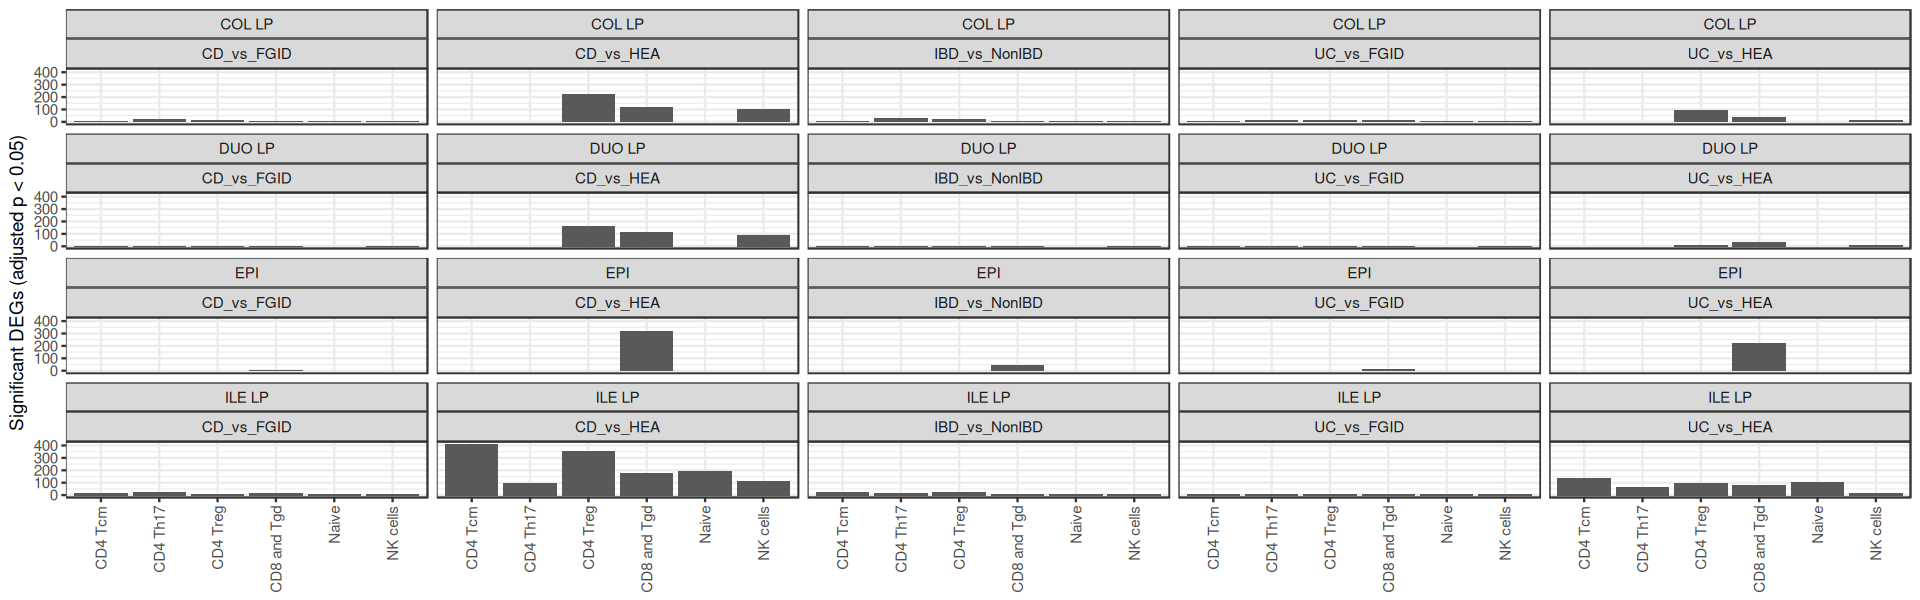

In [322]:
# Use the out_dir from your completed analysis
result_dirs <- expand_grid(
  tissue_layer = unique(jobs$tissue_layer),
  test = comparisons$test
)

files <- map2(
  result_dirs$tissue_layer,
  result_dirs$test,
  ~ list.files(
    file.path(out_dir, .x, .y),
    pattern = "\\.csv$",
    full.names = TRUE
  )
) %>%
  unlist(use.names = FALSE)

if (length(files) == 0L) {
  stop("No marker result files found.")
}

# Read results and count significant genes per file
loaded <- map(files, function(file) {
  dat <- read.csv(
    file,
    check.names = FALSE,
    stringsAsFactors = FALSE
  )

  tl <- basename(dirname(dirname(file)))
  test_name <- basename(dirname(file))
  annot <- tools::file_path_sans_ext(basename(file))

  list(
    results = dat,
    counts = tibble(
      tissue_layer = tl,
      test = test_name,
      annotation = annot,
      n = sum(dat$p_val_adj < 0.05, na.rm = TRUE)
    )
  )
})

deg_all_tissues_deseq <- bind_rows(map(loaded, "results"))
deg_counts <- bind_rows(map(loaded, "counts"))

ggplot(deg_counts, aes(x = annotation, y = n)) +
  geom_col() +
  facet_wrap(~ tissue_layer + test) +
  labs(
    x = NULL,
    y = "Significant DEGs (adjusted p < 0.05)"
  ) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5)
  )

In [323]:
# Include all expected combinations; missing results are labelled NT
plot_df <- expand_grid(
  annotation = unique(jobs$annotation),
  tissue_layer = c("DUO LP", "ILE LP", "COL LP", "EPI"),
  test = comparisons$test
) %>%
  left_join(
    deg_counts,
    by = c("annotation", "tissue_layer", "test")
  ) %>%
  mutate(
    label = if_else(is.na(n), "NT", as.character(n)),
    annotation = factor(
      annotation,
      levels = unique(jobs$annotation)
    ),
    tissue_layer = factor(
      tissue_layer,
      levels = c("EPI", "COL LP", "ILE LP", "DUO LP")
    ),
    test = factor(
      test,
      levels = c(
        "CD_vs_FGID",
        "CD_vs_HEA",
        "IBD_vs_NonIBD",
        "UC_vs_FGID",
        "UC_vs_HEA"
      )
    )
  )

# Recalculate scale limits from the current data
colour_max <- max(c(1, plot_df$n), na.rm = TRUE)

p <- ggplot(
  plot_df,
  aes(x = annotation, y = tissue_layer)
) +
  geom_point(
    data = filter(plot_df, !is.na(n), n > 0),
    aes(size = n, fill = n),
    shape = 21,
    colour = "grey60",
    stroke = 0.2
  ) +
  geom_text(
    aes(label = label),
    size = 4
  ) +
  facet_grid(
    cols = vars(test),
    labeller = labeller(
      test = function(x) gsub("_vs_", " vs. ", x, fixed = TRUE)
    )
  ) +
  scale_size_continuous(
    name = "Count of DEG",
    range=c(5,12)
  ) +
  scale_fill_gradientn(
    colours = c("#BDD3EF", "#CEBBD0", "#FA8078"),
    limits = c(0, colour_max),
    guide = "none"
  ) +
  scale_x_discrete(drop = FALSE) +
  scale_y_discrete(drop = FALSE) +
  labs(
    x = NULL,
    y = NULL,
    caption = "NT: Not tested; 0: tested with no significant DEGs"
  ) +
  theme_bw(base_size = 11) +
  theme(
    axis.text.x = element_text(
      angle = 90,
      hjust = 1,
      vjust = 0.5,
      colour = "black"
    ),
    axis.text.y = element_text(colour = "black"),
    axis.ticks = element_blank(),
    panel.grid.major = element_line(
      colour = "grey92",
      linewidth = 0.3
    ),
    panel.grid.minor = element_blank(),
    strip.background = element_rect(
      fill = "grey85",
      colour = NA
    ),
    strip.text = element_text(size = 20),
    panel.spacing.x = grid::unit(0.15, "cm"),
    plot.caption = element_text(hjust = 0)
  )


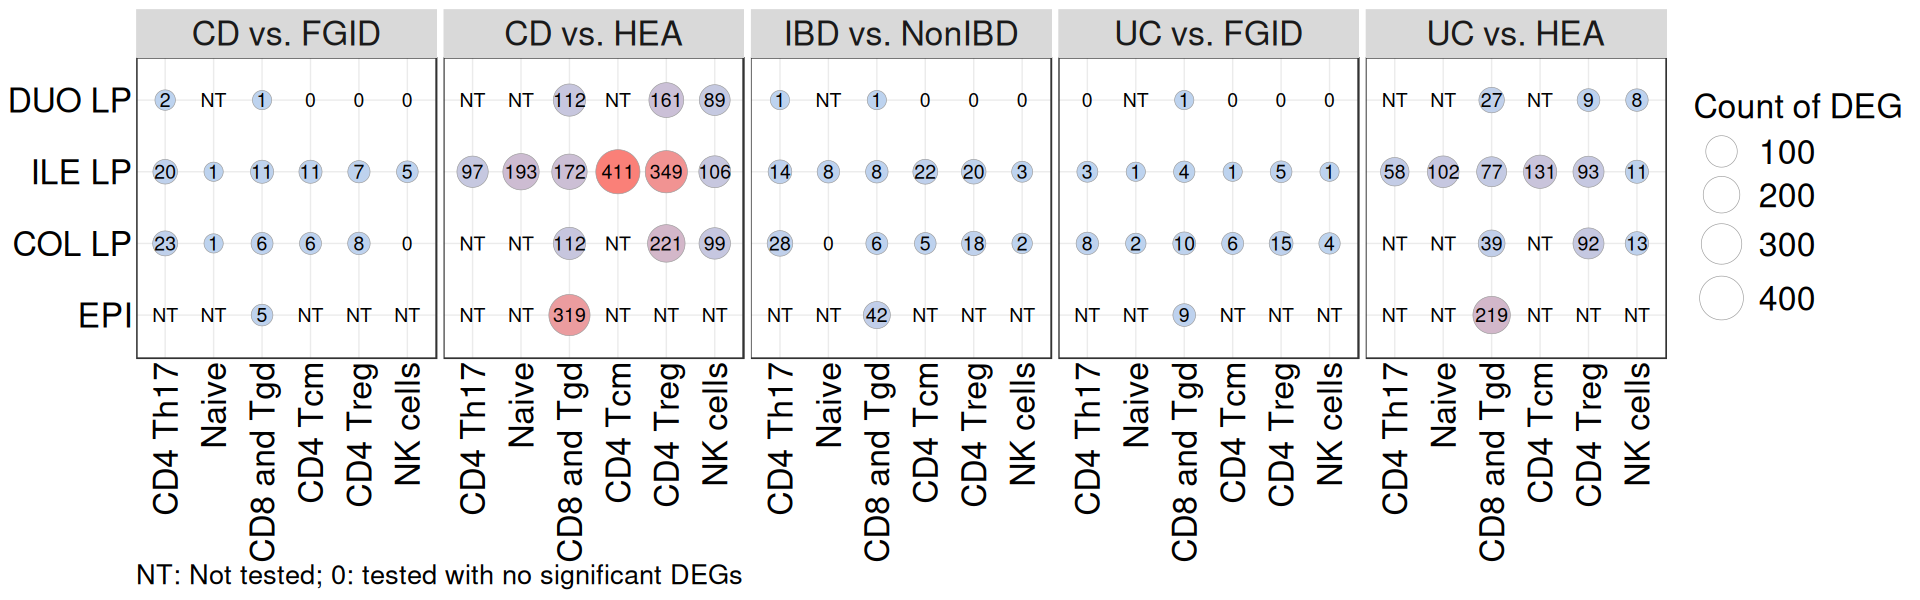

In [326]:
options(repr.plot.width = 16, repr.plot.height = 5)
p + ggtheme()

In [327]:
ggsave("figures/DEG_testing_count3p.svg", width = 40, height = 12, units = "cm")

In [325]:
plot_3p  <- p

# Patient-level 5p

## Filtering pseudobulk samples 5p

In [8]:
gut_allt_5p$cluster_sample  <- paste(gut_allt_5p$annotations_coarse, gut_allt_5p$data_folder, sep = "__")

gut_allt_5p@meta.data  %>% group_by(cluster_sample)  %>% tally()  %>% 
arrange(n)  %>% mutate(keep = n>19)  %>% group_by(keep)  %>% tally 

keep_samples  <- gut_allt_5p@meta.data  %>% group_by(cluster_sample)  %>% tally()  %>% 
arrange(n)  %>% dplyr::filter(n>19)  %>% pull(cluster_sample)

length(keep_samples)

keep,n
<lgl>,<int>
FALSE,782
TRUE,1964


[1] 1964

In [9]:
genes  <- rownames(gut_allt_5p@assays$RNA)

In [10]:
genes_filt_5p  <- genes[!(grepl(genes, pattern = "^MT")|
                            grepl(genes, pattern = "\\.")|
                            grepl(genes, pattern = "LINC")|
                            grepl(genes, pattern = "^MIR")|
                            grepl(genes, pattern = "^MT")|
                            grepl(genes, pattern = "HNRNP")|
                            grepl(genes, pattern = "^RP[LS]")|
                            grepl(genes, pattern = "\\-")|
                            grepl(genes, pattern = "TTTY")|
                            grepl(genes, pattern = "ORF")|
                            grepl(genes, pattern = "orf"))
                            ]

In [11]:
genes_filt_5p  %>% length()

[1] 19133

In [12]:
gut_allt_5p$timepoint  %>% table

.
     R     R2     T0 
 66727   2311 519025 

In [13]:
gut_allt_5p$keep_pseudobulk <- gut_allt_5p$cluster_sample %in% keep_samples & gut_allt_5p$timepoint %in% c("T0","T0D")

In [14]:
gut_allt_5p$keep_pseudobulk   %>% table

.
 FALSE   TRUE 
 73215 514848 

In [15]:
aggexp_5p  <- AggregateExpression(subset(gut_allt_5p, keep_pseudobulk == TRUE),
                                  group.by = c("cluster_sample"), 
                                  features = intersect(genes_filt_5p, rownames(gut_allt_5p)), 
                                  return.seurat = T)

Names of identity class contain underscores ('_'), replacing with dashes ('-')
This message is displayed once every 8 hours.
Warning message:
“The counts layer for the integrated assay is empty. Skipping assay.”


In [16]:
aggexp_5p[["RNA3"]]  <- NULL

In [17]:
aggexp_5p

An object of class Seurat 
821 features across 1685 samples within 1 assay 
Active assay: RNA (821 features, 0 variable features)
 2 layers present: counts, data

In [18]:
aggexp_5p@meta.data  %>% colnames

[1] "orig.ident"     "cluster_sample"

In [19]:
# Select only patients which were not included in 3p

In [20]:
pt_3p  <- gsub(c('p009',
'p011',
'p014',
'p016',
'p017',
'p018',
'p019',
'p022',
'p023',
'p024',
'p026',
'p027',
'p028',
'p030',
'p031',
'p032',
'p033',
'p034',
'p035',
'p037',
'p041',
'p042',
'p043',
'p044',
'p048',
'p049',
'p050'), pattern = "p", replacement = "001-")

In [21]:
md_to_join  <- gut_allt_5p@meta.data  %>% 
group_by(cluster_sample, annotations_coarse, timepoint, tissue, layer, participant_id,
                                                  diagnosis, antitnf_response)  %>% 
tally()  %>% 
dplyr::select(-n)  %>% 
ungroup  %>% 
mutate(cluster_sample = gsub(cluster_sample, pattern = "_", replacement = "-"))

md  <- aggexp_5p@meta.data  %>% left_join(md_to_join)

rownames(md)  <- colnames(aggexp_5p)

aggexp_5p@meta.data  <- md

aggexp_5p$tissue_layer  <- ifelse(aggexp_5p$layer == 'EPI','EPI',paste(aggexp_5p$tissue, aggexp_5p$layer))

Joining with `by = join_by(cluster_sample)`


In [22]:
table((aggexp_5p$participant_id   %>% unique) %in% pt_3p)


FALSE  TRUE 
   73    26 

In [23]:
aggexp_5p  <- subset(aggexp_5p, (participant_id %in% pt_3p)==F)

In [24]:
table((aggexp_5p$participant_id   %>% unique) %in% pt_3p)


FALSE 
   73 

## Finding DEG in pseudobulk

In [25]:
# Use the full pseudobulk object
ds_sub <- aggexp_5p

ds_sub$diagnosis2 <- ifelse(
  ds_sub$diagnosis %in% c("UC", "CD"),
  "IBD",
  "NonIBD"
)

annots <- levels(factor(ds_sub$annotations_coarse))
tissue_layers <- c("COL LP", "ILE LP", "DUO LP", "EPI")

# EPI includes all tissues with layer == "EPI"
ds_sub$tissue_layer <- ifelse(
  ds_sub$layer == "EPI",
  "EPI",
  paste(ds_sub$tissue, ds_sub$layer)
)

In [26]:
comparisons <- data.frame(
  test = c(
    "IBD_vs_NonIBD",
    "UC_vs_FGID",
    "CD_vs_FGID",
    "UC_vs_HEA",
    "CD_vs_HEA"
  ),
  identity_column = c(
    "diagnosis2",
    rep("diagnosis", 4)
  ),
  ident1 = c("IBD", "UC", "CD", "UC", "CD"),
  ident2 = c("NonIBD", "FGID", "FGID", "HEA", "HEA"),
  stringsAsFactors = FALSE
)

In [27]:
jobs <- expand.grid(
  annotation = annots,
  tissue_layer = tissue_layers,
  stringsAsFactors = FALSE
)

out_dir <- file.path(
  "tables",
  paste0("deg_patient_level_5p_", format(Sys.time(), "%Y%m%d_%H%M%S"))
)

In [28]:
# Create separate folders for every tissue/layer and comparison
for (tl in tissue_layers) {
  for (test_name in comparisons$test) {
    dir.create(
      file.path(out_dir, tl, test_name),
      recursive = TRUE,
      showWarnings = FALSE
    )
  }
}

stopifnot(is.character(genes))

In [29]:
# Use the full pseudobulk object
ds_sub <- aggexp_5p

ds_sub$diagnosis2 <- ifelse(
  ds_sub$diagnosis %in% c("UC", "CD"),
  "IBD",
  "NonIBD"
)

annots <- levels(factor(ds_sub$annotations_coarse))
tissue_layers <- c("COL LP", "ILE LP", "DUO LP", "EPI")

# EPI includes all tissues with layer == "EPI"
ds_sub$tissue_layer <- ifelse(
  ds_sub$layer == "EPI",
  "EPI",
  paste(ds_sub$tissue, ds_sub$layer)
)

In [30]:
comparisons <- data.frame(
  test = c(
    "IBD_vs_NonIBD",
    "UC_vs_FGID",
    "CD_vs_FGID",
    "UC_vs_HEA",
    "CD_vs_HEA"
  ),
  identity_column = c(
    "diagnosis2",
    rep("diagnosis", 4)
  ),
  ident1 = c("IBD", "UC", "CD", "UC", "CD"),
  ident2 = c("NonIBD", "FGID", "FGID", "HEA", "HEA"),
  stringsAsFactors = FALSE
)

In [31]:
# Create separate folders for every tissue/layer and comparison
for (tl in tissue_layers) {
  for (test_name in comparisons$test) {
    dir.create(
      file.path(out_dir, tl, test_name),
      recursive = TRUE,
      showWarnings = FALSE
    )
  }
}

stopifnot(is.character(genes))

In [51]:

plan(sequential)

# Extract counts once, avoiding subset() on the full Seurat object
counts_all <- GetAssayData(
  ds_sub,
  assay = "RNA",
  layer = "counts"
)

metadata_all <- ds_sub[[]]

stopifnot(
  length(dim(counts_all)) == 2L,
  !is.null(rownames(counts_all)),
  !is.null(colnames(counts_all)),
  !anyNA(rownames(counts_all)),
  !anyNA(colnames(counts_all)),
  all(nzchar(rownames(counts_all))),
  all(nzchar(colnames(counts_all))),
  anyDuplicated(rownames(counts_all)) == 0L,
  anyDuplicated(colnames(counts_all)) == 0L,
  all(colnames(counts_all) %in% rownames(metadata_all)),
  all(c("annotations_coarse", "tissue_layer") %in% names(metadata_all)),
  all(comparisons$identity_column %in% names(metadata_all)),
  is.character(genes)
)

# Align metadata with the count matrix
metadata_all <- metadata_all[colnames(counts_all), , drop = FALSE]

# Create output directories
for (tl in unique(jobs$tissue_layer)) {
  for (test_name in comparisons$test) {
    dir.create(
      file.path(out_dir, tl, test_name),
      recursive = TRUE,
      showWarnings = FALSE
    )
  }
}

options(future.globals.maxSize = 16 * 1024^3)
plan(multisession, workers = 12)

# Reset the parallel plan even if a job fails
tryCatch(
  {
    future_walk(
      seq_len(nrow(jobs)),
      function(job_id) {
        future::plan(future::sequential)

        annot_use <- jobs$annotation[job_id]
        tl_use <- jobs$tissue_layer[job_id]

        label <- paste0(
          "[Job ", job_id, ": ", annot_use, " / ", tl_use, "]"
        )

        stage <- "starting"

        log_stage <- function(text) {
          message(label, " ", text)
        }

        tryCatch({

          stage <- "selecting sample names"
          log_stage(paste("START:", stage))

          cells_use <- rownames(metadata_all)[
            which(
              metadata_all$annotations_coarse == annot_use &
              metadata_all$tissue_layer == tl_use
            )
          ]

          log_stage(paste("Selected samples:", length(cells_use)))

          # At least 3 samples per group requires at least 6 total
          if (length(cells_use) < 6L) {
            log_stage("SKIPPED: fewer than 6 samples in total")
            return(invisible(NULL))
          }

          stage <- "extracting and rounding counts"
          log_stage(paste("START:", stage))

          counts <- round(counts_all[, cells_use, drop = FALSE])
          metadata <- metadata_all[colnames(counts), , drop = FALSE]

          stopifnot(
            length(dim(counts)) == 2L,
            !is.null(rownames(counts)),
            !is.null(colnames(counts)),
            identical(colnames(counts), rownames(metadata))
          )

          log_stage(paste(
            "Counts:", nrow(counts), "genes x",
            ncol(counts), "samples"
          ))

          stage <- "filtering genes detected in at least 3 samples"
          log_stage(paste("START:", stage))

          keep_genes <- Matrix::rowSums(counts > 0) >= 3L

          log_stage(paste(
            "Genes passing the 3-sample filter:",
            sum(keep_genes)
          ))

          if (!any(keep_genes)) {
            log_stage("SKIPPED: no genes pass the 3-sample filter")
            return(invisible(NULL))
          }

          counts <- counts[keep_genes, , drop = FALSE]

          stage <- "CreateSeuratObject"
          log_stage(paste("START:", stage))

          # Filtering was already applied explicitly above
          sub <- CreateSeuratObject(
            counts = counts,
            meta.data = metadata,
            assay = "RNA",
            min.cells = 0,
            min.features = 0
          )

          log_stage(paste(
            "Object created:",
            nrow(sub), "features;",
            ncol(sub), "samples"
          ))

          stage <- "NormalizeData"
          log_stage(paste("START:", stage))

          sub <- NormalizeData(sub, verbose = FALSE)

          log_stage("Normalization completed")

          stage <- "selecting genes_use"
          log_stage(paste("START:", stage))

          genes_use <- intersect(genes, rownames(counts))

          log_stage(paste(
            "Requested genes available:", length(genes_use)
          ))

          if (length(genes_use) == 0L) {
            log_stage("SKIPPED: no requested genes available")
            return(invisible(NULL))
          }

          for (test_id in seq_len(nrow(comparisons))) {
            cmp <- comparisons[test_id, ]

            stage <- paste("setting identities for", cmp$test)
            log_stage(paste("START:", stage))

            Idents(sub) <- sub[[cmp$identity_column, drop = TRUE]]

            n1 <- sum(Idents(sub) == cmp$ident1, na.rm = TRUE)
            n2 <- sum(Idents(sub) == cmp$ident2, na.rm = TRUE)

            log_stage(paste(
              cmp$test, ":",
              cmp$ident1, "=", n1, ";",
              cmp$ident2, "=", n2
            ))

            if (n1 < 3L || n2 < 3L) {
              log_stage(paste(
                "SKIPPED:", cmp$test,
                "— fewer than 3 samples in one group"
              ))
              next
            }

            stage <- paste("FindMarkers:", cmp$test)
            log_stage(paste("START:", stage))

            deg <- Seurat::FindMarkers(
              sub,
              assay = "RNA",
              ident.1 = cmp$ident1,
              ident.2 = cmp$ident2,
              features = genes_use,
              slot = "counts",
              test.use = "DESeq2",
              min.pct = 0.2,
              min.cells.feature = 5
            )

            deg$p_val_fdr <- p.adjust(deg$p_val, method = "BH")
              
            log_stage(paste(
              "FindMarkers completed:", nrow(deg), "rows"
            ))

            stage <- paste("adding result metadata:", cmp$test)

            nr <- nrow(deg)
            deg$gene <- rownames(deg)
            deg$test <- rep(cmp$test, nr)
            deg$annotation <- rep(annot_use, nr)
            deg$tissue_layer <- rep(tl_use, nr)
            deg$tissue <- rep(
              if (tl_use == "EPI") {
                NA_character_
              } else {
                base::sub(" LP$", "", tl_use)
              },
              nr
            )
            deg$layer <- rep(
              if (tl_use == "EPI") "EPI" else "LP",
              nr
            )

            stage <- paste("writing CSV:", cmp$test)
            log_stage(paste("START:", stage))

            write.csv(
              deg,
              file = file.path(
                out_dir,
                tl_use,
                cmp$test,
                paste0(annot_use, ".csv")
              ),
              row.names = FALSE
            )

            log_stage(paste("Saved:", cmp$test))
          }

          log_stage("JOB COMPLETED")

        }, error = function(e) {
          stop(
            label,
            "\nFAILED AT: ", stage,
            "\nORIGINAL ERROR: ", conditionMessage(e),
            call. = FALSE
          )
        })
      },
      .options = furrr_options(
        packages = c("Seurat", "DESeq2"),
        seed = 123
      )
    )
  },
  finally = {
    plan(sequential)
  }
)

[Job 1: CD4 Th17 / COL LP] START: selecting sample names

[Job 1: CD4 Th17 / COL LP] Selected samples: 69

[Job 1: CD4 Th17 / COL LP] START: extracting and rounding counts

[Job 1: CD4 Th17 / COL LP] Counts: 821 genes x 69 samples

[Job 1: CD4 Th17 / COL LP] START: filtering genes detected in at least 3 samples

[Job 1: CD4 Th17 / COL LP] Genes passing the 3-sample filter: 817

[Job 1: CD4 Th17 / COL LP] START: CreateSeuratObject

[Job 1: CD4 Th17 / COL LP] Object created: 817 features; 69 samples

[Job 1: CD4 Th17 / COL LP] START: NormalizeData

[Job 1: CD4 Th17 / COL LP] Normalization completed

[Job 1: CD4 Th17 / COL LP] START: selecting genes_use

[Job 1: CD4 Th17 / COL LP] Requested genes available: 817

[Job 1: CD4 Th17 / COL LP] START: setting identities for IBD_vs_NonIBD

[Job 1: CD4 Th17 / COL LP] IBD_vs_NonIBD : IBD = 43 ; NonIBD = 26

[Job 1: CD4 Th17 / COL LP] START: FindMarkers: IBD_vs_NonIBD

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersi

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 3: CD8 and Tgd / COL LP] FindMarkers completed: 812 rows

[Job 3: CD8 and Tgd / COL LP] START: writing CSV: CD_vs_FGID

[Job 3: CD8 and Tgd / COL LP] Saved: CD_vs_FGID

[Job 3: CD8 and Tgd / COL LP] START: setting identities for UC_vs_HEA

[Job 3: CD8 and Tgd / COL LP] UC_vs_HEA : UC = 17 ; HEA = 9

[Job 3: CD8 and Tgd / COL LP] START: FindMarkers: UC_vs_HEA

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 3: CD8 and Tgd / COL LP] FindMarkers completed: 816 rows

[Job 3: CD8 and Tgd / COL LP] START: writing CSV: UC_vs_HEA

[Job 3: CD8 and Tgd / COL LP] Saved: UC_vs_HEA

[Job 3: CD8 and Tgd / COL LP] START: setting identities for CD_vs_HEA

[Job 3: CD8 and Tgd / COL LP] CD_vs_HEA : CD = 26 ; HEA = 9

[Job 3: CD8 and Tgd / COL LP] START: FindMarkers: CD_vs_HEA

converting counts 

[Job 6: NK cells / COL LP] START: setting identities for IBD_vs_NonIBD

[Job 6: NK cells / COL LP] IBD_vs_NonIBD : IBD = 38 ; NonIBD = 20

[Job 6: NK cells / COL LP] START: FindMarkers: IBD_vs_NonIBD

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 6: NK cells / COL LP] FindMarkers completed: 763 rows

[Job 6: NK cells / COL LP] START: writing CSV: IBD_vs_NonIBD

[Job 6: NK cells / COL LP] Saved: IBD_vs_NonIBD

[Job 6: NK cells / COL LP] START: setting identities for UC_vs_FGID

[Job 6: NK cells / COL LP] UC_vs_FGID : UC = 16 ; FGID = 8

[Job 6: NK cells / COL LP] START: FindMarkers: UC_vs_FGID

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 6: NK cells / COL LP] FindMarkers completed: 756 rows

[Job 6: NK cells / COL LP] START: writing CSV: UC_vs_FGID

[Job 6: NK cells / COL LP] Saved: UC_vs_FGID

[Job 6: NK cells / COL LP

[Job 8: CD4 Tcm / ILE LP] START: setting identities for CD_vs_HEA

[Job 8: CD4 Tcm / ILE LP] CD_vs_HEA : CD = 24 ; HEA = 9

[Job 8: CD4 Tcm / ILE LP] START: FindMarkers: CD_vs_HEA

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 8: CD4 Tcm / ILE LP] FindMarkers completed: 803 rows

[Job 8: CD4 Tcm / ILE LP] START: writing CSV: CD_vs_HEA

[Job 8: CD4 Tcm / ILE LP] Saved: CD_vs_HEA

[Job 8: CD4 Tcm / ILE LP] JOB COMPLETED

[Job 9: CD8 and Tgd / ILE LP] START: selecting sample names

[Job 9: CD8 and Tgd / ILE LP] Selected samples: 70

[Job 9: CD8 and Tgd / ILE LP] START: extracting and rounding counts

[Job 9: CD8 and Tgd / ILE LP] Counts: 821 genes x 70 samples

[Job 9: CD8 and Tgd / ILE LP] START: filtering genes detected in at least 3 samples

[Job 9: CD8 and Tgd / ILE LP] Genes passing the 3-sample filter: 819

[Job 9: CD8 and Tgd / ILE LP] START: CreateSeuratObject

[Job 9: CD8 and Tgd / ILE LP] Object 

[Job 11: CD4 Treg / ILE LP] START: FindMarkers: UC_vs_FGID

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 11: CD4 Treg / ILE LP] FindMarkers completed: 796 rows

[Job 11: CD4 Treg / ILE LP] START: writing CSV: UC_vs_FGID

[Job 11: CD4 Treg / ILE LP] Saved: UC_vs_FGID

[Job 11: CD4 Treg / ILE LP] START: setting identities for CD_vs_FGID

[Job 11: CD4 Treg / ILE LP] CD_vs_FGID : CD = 24 ; FGID = 11

[Job 11: CD4 Treg / ILE LP] START: FindMarkers: CD_vs_FGID

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 11: CD4 Treg / ILE LP] FindMarkers completed: 805 rows

[Job 11: CD4 Treg / ILE LP] START: writing CSV: CD_vs_FGID

[Job 11: CD4 Treg / ILE LP] Saved: CD_vs_FGID

[Job 11: CD4 Treg / ILE LP] START: setting identities for UC_vs_HEA

[Job 11: CD4 Treg / ILE LP] UC_vs_HEA : UC = 17 ; HEA = 9

[Job 11: CD4 Treg / ILE LP] START:

[Job 13: CD4 Th17 / DUO LP] JOB COMPLETED

[Job 14: CD4 Tcm / DUO LP] START: selecting sample names

[Job 14: CD4 Tcm / DUO LP] Selected samples: 14

[Job 14: CD4 Tcm / DUO LP] START: extracting and rounding counts

[Job 14: CD4 Tcm / DUO LP] Counts: 821 genes x 14 samples

[Job 14: CD4 Tcm / DUO LP] START: filtering genes detected in at least 3 samples

[Job 14: CD4 Tcm / DUO LP] Genes passing the 3-sample filter: 771

[Job 14: CD4 Tcm / DUO LP] START: CreateSeuratObject

[Job 14: CD4 Tcm / DUO LP] Object created: 771 features; 14 samples

[Job 14: CD4 Tcm / DUO LP] START: NormalizeData

[Job 14: CD4 Tcm / DUO LP] Normalization completed

[Job 14: CD4 Tcm / DUO LP] START: selecting genes_use

[Job 14: CD4 Tcm / DUO LP] Requested genes available: 771

[Job 14: CD4 Tcm / DUO LP] START: setting identities for IBD_vs_NonIBD

[Job 14: CD4 Tcm / DUO LP] IBD_vs_NonIBD : IBD = 8 ; NonIBD = 6

[Job 14: CD4 Tcm / DUO LP] START: FindMarkers: IBD_vs_NonIBD

converting counts to integer mode

gene

[Job 17: CD4 Treg / DUO LP] START: setting identities for IBD_vs_NonIBD

[Job 17: CD4 Treg / DUO LP] IBD_vs_NonIBD : IBD = 25 ; NonIBD = 13

[Job 17: CD4 Treg / DUO LP] START: FindMarkers: IBD_vs_NonIBD

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 17: CD4 Treg / DUO LP] FindMarkers completed: 771 rows

[Job 17: CD4 Treg / DUO LP] START: writing CSV: IBD_vs_NonIBD

[Job 17: CD4 Treg / DUO LP] Saved: IBD_vs_NonIBD

[Job 17: CD4 Treg / DUO LP] START: setting identities for UC_vs_FGID

[Job 17: CD4 Treg / DUO LP] UC_vs_FGID : UC = 4 ; FGID = 6

[Job 17: CD4 Treg / DUO LP] START: FindMarkers: UC_vs_FGID

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 17: CD4 Treg / DUO LP] FindMarkers completed: 771 rows

[Job 17: CD4 Treg / DUO LP] START: writing CSV: UC_vs_FGID

[Job 17: CD4 Treg / DUO LP] Saved: UC_vs_FGID

[Job 17: CD4 T

[Job 20: CD4 Tcm / EPI] START: selecting sample names

[Job 20: CD4 Tcm / EPI] Selected samples: 41

[Job 20: CD4 Tcm / EPI] START: extracting and rounding counts

[Job 20: CD4 Tcm / EPI] Counts: 821 genes x 41 samples

[Job 20: CD4 Tcm / EPI] START: filtering genes detected in at least 3 samples

[Job 20: CD4 Tcm / EPI] Genes passing the 3-sample filter: 791

[Job 20: CD4 Tcm / EPI] START: CreateSeuratObject

[Job 20: CD4 Tcm / EPI] Object created: 791 features; 41 samples

[Job 20: CD4 Tcm / EPI] START: NormalizeData

[Job 20: CD4 Tcm / EPI] Normalization completed

[Job 20: CD4 Tcm / EPI] START: selecting genes_use

[Job 20: CD4 Tcm / EPI] Requested genes available: 791

[Job 20: CD4 Tcm / EPI] START: setting identities for IBD_vs_NonIBD

[Job 20: CD4 Tcm / EPI] IBD_vs_NonIBD : IBD = 27 ; NonIBD = 14

[Job 20: CD4 Tcm / EPI] START: FindMarkers: IBD_vs_NonIBD

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



[Job 22: Naive / EPI] Saved: CD_vs_FGID

[Job 22: Naive / EPI] START: setting identities for UC_vs_HEA

[Job 22: Naive / EPI] UC_vs_HEA : UC = 12 ; HEA = 4

[Job 22: Naive / EPI] START: FindMarkers: UC_vs_HEA

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 22: Naive / EPI] FindMarkers completed: 754 rows

[Job 22: Naive / EPI] START: writing CSV: UC_vs_HEA

[Job 22: Naive / EPI] Saved: UC_vs_HEA

[Job 22: Naive / EPI] START: setting identities for CD_vs_HEA

[Job 22: Naive / EPI] CD_vs_HEA : CD = 10 ; HEA = 4

[Job 22: Naive / EPI] START: FindMarkers: CD_vs_HEA

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

[Job 22: Naive / EPI] FindMarkers completed: 744 rows

[Job 22: Naive / EPI] START: writing CSV: CD_vs_HEA

[Job 22: Naive / EPI] Saved: CD_vs_HEA

[Job 22: Naive / EPI] JOB COMPLETED

[Job 23: CD4 Treg / EPI] START: select

## Testing summary

In [52]:
test_status <- expand.grid(
  job_id = seq_len(nrow(jobs)),
  test_id = seq_len(nrow(comparisons))
) %>%
  mutate(
    annotation = jobs$annotation[job_id],
    tissue_layer = jobs$tissue_layer[job_id],
    test = comparisons$test[test_id],
    file = file.path(
      out_dir,
      tissue_layer,
      test,
      paste0(annotation, ".csv")
    ),
    carried_out = file.exists(file),
    status = if_else(
      carried_out,
      "Carried out",
      "Not carried out"
    )
  ) %>%
  select(annotation, tissue_layer, test, carried_out, status, file)

# One row per annotation × tissue, one column per test
test_status_wide <- test_status %>%
  select(annotation, tissue_layer, test, status) %>%
  pivot_wider(
    names_from = test,
    values_from = status
  ) %>%
  arrange(tissue_layer, annotation)

test_status_wide

annotation,tissue_layer,IBD_vs_NonIBD,UC_vs_FGID,CD_vs_FGID,UC_vs_HEA,CD_vs_HEA
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CD4 Tcm,COL LP,Carried out,Carried out,Carried out,Carried out,Carried out
CD4 Th17,COL LP,Carried out,Carried out,Carried out,Carried out,Carried out
CD4 Treg,COL LP,Carried out,Carried out,Carried out,Carried out,Carried out
CD8 and Tgd,COL LP,Carried out,Carried out,Carried out,Carried out,Carried out
NK cells,COL LP,Carried out,Carried out,Carried out,Carried out,Carried out
Naive,COL LP,Carried out,Carried out,Carried out,Carried out,Carried out
CD4 Tcm,DUO LP,Carried out,Not carried out,Carried out,Not carried out,Not carried out
CD4 Th17,DUO LP,Carried out,Carried out,Carried out,Carried out,Carried out
CD4 Treg,DUO LP,Carried out,Carried out,Carried out,Carried out,Carried out


In [53]:
# Overall summary
test_status %>%
  count(test, status)

test,status,n
<chr>,<chr>,<int>
CD_vs_FGID,Carried out,23
CD_vs_FGID,Not carried out,1
CD_vs_HEA,Carried out,21
CD_vs_HEA,Not carried out,3
IBD_vs_NonIBD,Carried out,23
IBD_vs_NonIBD,Not carried out,1
UC_vs_FGID,Carried out,21
UC_vs_FGID,Not carried out,3
UC_vs_HEA,Carried out,20


In [54]:
sample_counts <- expand.grid(
  job_id = seq_len(nrow(jobs)),
  test_id = seq_len(nrow(comparisons))
) %>%
  pmap_dfr(function(job_id, test_id) {
    annot_use <- jobs$annotation[job_id]
    tl_use <- jobs$tissue_layer[job_id]
    cmp <- comparisons[test_id, ]

    meta <- metadata_all[
      which(
        metadata_all$annotations_coarse == annot_use &
        metadata_all$tissue_layer == tl_use
      ),
      ,
      drop = FALSE
    ]

    groups <- meta[[cmp$identity_column]]

    tibble(
      annotation = annot_use,
      tissue_layer = tl_use,
      test = cmp$test,
      group1 = cmp$ident1,
      group2 = cmp$ident2,
      n1 = sum(groups == cmp$ident1, na.rm = TRUE),
      n2 = sum(groups == cmp$ident2, na.rm = TRUE)
    )
  })

sample_counts_wide <- sample_counts %>%
  mutate(
    samples = paste0(group1, ": ", n1, "; ", group2, ": ", n2)
  ) %>%
  select(annotation, tissue_layer, test, samples) %>%
  pivot_wider(
    names_from = test,
    values_from = samples
  ) %>%
  arrange(tissue_layer, annotation)

sample_counts_wide

write.csv(
  sample_counts_wide,
  file.path(out_dir, "sample_counts_wide.csv"),
  row.names = FALSE
)

annotation,tissue_layer,IBD_vs_NonIBD,UC_vs_FGID,CD_vs_FGID,UC_vs_HEA,CD_vs_HEA
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CD4 Tcm,COL LP,IBD: 41; NonIBD: 24,UC: 16; FGID: 11,CD: 25; FGID: 11,UC: 16; HEA: 9,CD: 25; HEA: 9
CD4 Th17,COL LP,IBD: 43; NonIBD: 26,UC: 17; FGID: 13,CD: 26; FGID: 13,UC: 17; HEA: 9,CD: 26; HEA: 9
CD4 Treg,COL LP,IBD: 42; NonIBD: 22,UC: 16; FGID: 10,CD: 26; FGID: 10,UC: 16; HEA: 9,CD: 26; HEA: 9
CD8 and Tgd,COL LP,IBD: 43; NonIBD: 25,UC: 17; FGID: 12,CD: 26; FGID: 12,UC: 17; HEA: 9,CD: 26; HEA: 9
NK cells,COL LP,IBD: 38; NonIBD: 20,UC: 16; FGID: 8,CD: 22; FGID: 8,UC: 16; HEA: 9,CD: 22; HEA: 9
Naive,COL LP,IBD: 32; NonIBD: 18,UC: 10; FGID: 8,CD: 22; FGID: 8,UC: 10; HEA: 7,CD: 22; HEA: 7
CD4 Tcm,DUO LP,IBD: 8; NonIBD: 6,UC: 0; FGID: 3,CD: 8; FGID: 3,UC: 0; HEA: 2,CD: 8; HEA: 2
CD4 Th17,DUO LP,IBD: 29; NonIBD: 23,UC: 5; FGID: 11,CD: 24; FGID: 11,UC: 5; HEA: 9,CD: 24; HEA: 9
CD4 Treg,DUO LP,IBD: 25; NonIBD: 13,UC: 4; FGID: 6,CD: 21; FGID: 6,UC: 4; HEA: 5,CD: 21; HEA: 5


## Plotting results

In [32]:
out_dir  <- "tables/deg_patient_level_5p_20261022_095445/"

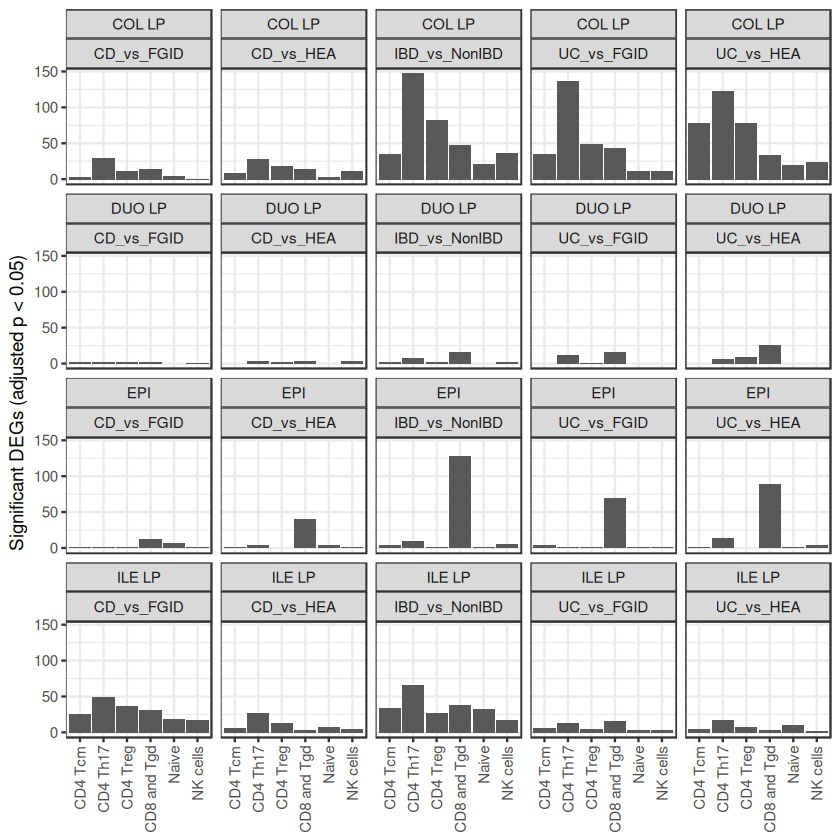

In [33]:
# Use the out_dir from your completed analysis
result_dirs <- expand_grid(
  tissue_layer = unique(jobs$tissue_layer),
  test = comparisons$test
)

files <- map2(
  result_dirs$tissue_layer,
  result_dirs$test,
  ~ list.files(
    file.path(out_dir, .x, .y),
    pattern = "\\.csv$",
    full.names = TRUE
  )
) %>%
  unlist(use.names = FALSE)

if (length(files) == 0L) {
  stop("No marker result files found.")
}

# Read results and count significant genes per file
loaded <- map(files, function(file) {
  dat <- read.csv(
    file,
    check.names = FALSE,
    stringsAsFactors = FALSE
  )

  tl <- basename(dirname(dirname(file)))
  test_name <- basename(dirname(file))
  annot <- tools::file_path_sans_ext(basename(file))

  list(
    results = dat,
    counts = tibble(
      tissue_layer = tl,
      test = test_name,
      annotation = annot,
      n = sum(dat$p_val_adj < 0.1, na.rm = TRUE)
    )
  )
})

deg_all_tissues_deseq <- bind_rows(map(loaded, "results"))
deg_counts <- bind_rows(map(loaded, "counts"))

ggplot(deg_counts, aes(x = annotation, y = n)) +
  geom_col() +
  facet_wrap(~ tissue_layer + test) +
  labs(
    x = NULL,
    y = "Significant DEGs (adjusted p < 0.05)"
  ) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5)
  )

In [34]:
deg_counts

tissue_layer,test,annotation,n
<chr>,<chr>,<chr>,<int>
COL LP,IBD_vs_NonIBD,CD4 Tcm,34
COL LP,IBD_vs_NonIBD,CD4 Th17,147
COL LP,IBD_vs_NonIBD,CD4 Treg,82
COL LP,IBD_vs_NonIBD,CD8 and Tgd,47
COL LP,IBD_vs_NonIBD,Naive,21
COL LP,IBD_vs_NonIBD,NK cells,36
COL LP,UC_vs_FGID,CD4 Tcm,34
COL LP,UC_vs_FGID,CD4 Th17,136
COL LP,UC_vs_FGID,CD4 Treg,48


In [35]:

# Include all expected combinations; missing results are labelled NT
plot_df <- expand_grid(
  annotation = unique(jobs$annotation),
  tissue_layer = c("DUO LP", "ILE LP", "COL LP", "EPI"),
  test = comparisons$test
) %>%
  left_join(
    deg_counts,
    by = c("annotation", "tissue_layer", "test")
  ) %>%
  mutate(
    label = if_else(is.na(n), "NT", as.character(n)),
    annotation = factor(
      annotation,
      levels = unique(jobs$annotation)
    ),
    tissue_layer = factor(
      tissue_layer,
      levels = c("EPI", "COL LP", "ILE LP", "DUO LP")
    ),
    test = factor(
      test,
      levels = c(
        "CD_vs_FGID",
        "CD_vs_HEA",
        "IBD_vs_NonIBD",
        "UC_vs_FGID",
        "UC_vs_HEA"
      )
    )
  )

# Recalculate scale limits from the current data
colour_max <- max(c(1, plot_df$n), na.rm = TRUE)

p <- ggplot(
  plot_df,
  aes(x = annotation, y = tissue_layer)
) +
  geom_point(
    data = filter(plot_df, !is.na(n), n > 0),
    aes(size = n, fill = n),
    shape = 21,
    colour = "grey60",
    stroke = 0.2
  ) +
  geom_text(
    aes(label = label),
    size = 4
  ) +
  facet_grid(
    cols = vars(test),
    labeller = labeller(
      test = function(x) gsub("_vs_", " vs. ", x, fixed = TRUE)
    )
  ) +
  scale_size_continuous(
    name = "Count of DEG",
    range=c(5,12)
  ) +
  scale_fill_gradientn(
    colours = c("#BDD3EF", "#CEBBD0", "#FA8078"),
    limits = c(0, colour_max),
    guide = "none"
  ) +
  scale_x_discrete(drop = FALSE) +
  scale_y_discrete(drop = FALSE) +
  labs(
    x = NULL,
    y = NULL,
    caption = "NT: Not tested; 0: tested with no significant DEGs"
  ) +
  theme_bw(base_size = 11) +
  theme(
    axis.text.x = element_text(
      angle = 90,
      hjust = 1,
      vjust = 0.5,
      colour = "black"
    ),
    axis.text.y = element_text(colour = "black"),
    axis.ticks = element_blank(),
    panel.grid.major = element_line(
      colour = "grey92",
      linewidth = 0.3
    ),
    panel.grid.minor = element_blank(),
    strip.background = element_rect(
      fill = "grey85",
      colour = NA
    ),
    strip.text = element_text(size = 20),
    panel.spacing.x = grid::unit(0.15, "cm"),
    plot.caption = element_text(hjust = 0)
  )


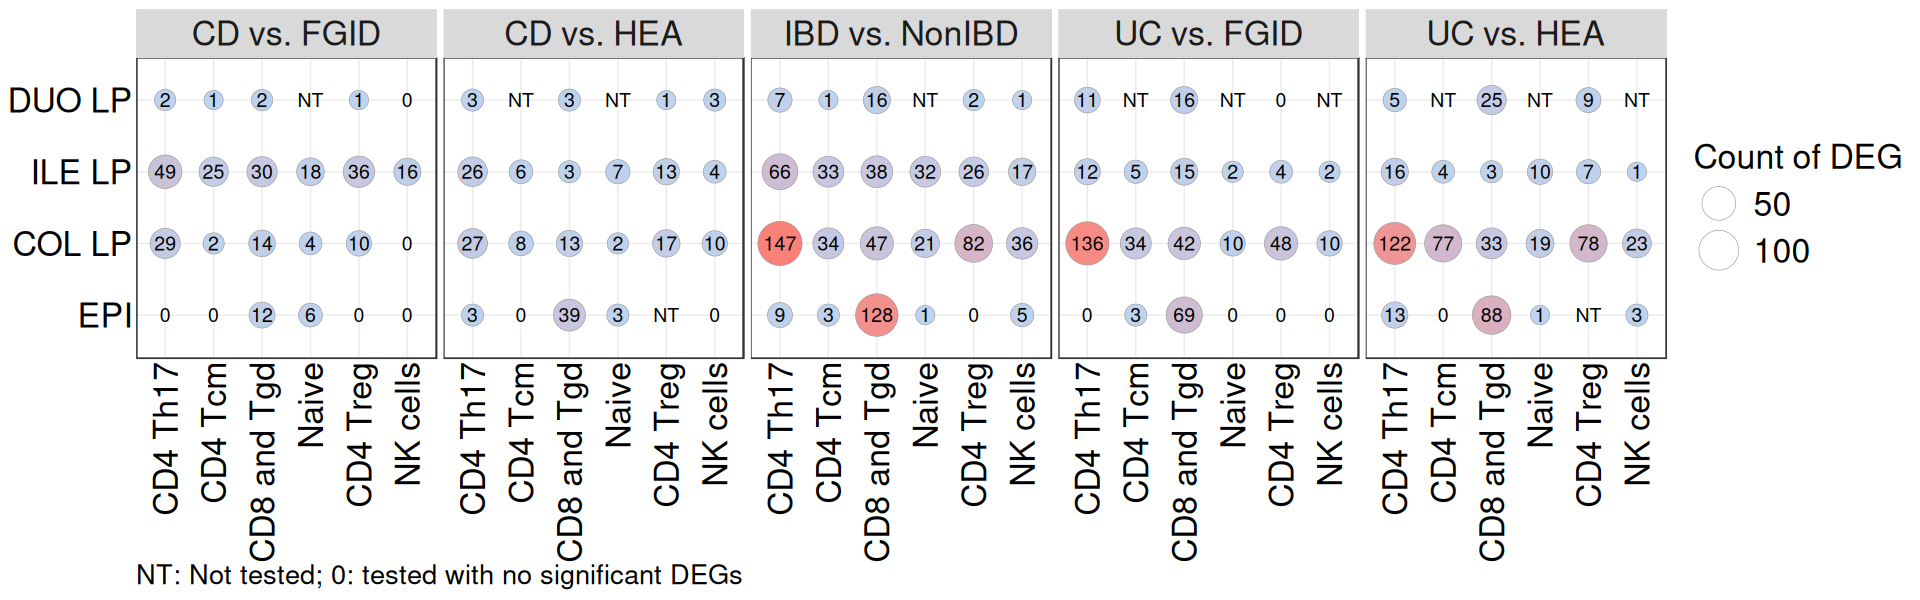

In [58]:
options(repr.plot.width = 16, repr.plot.height = 5)
p + ggtheme()

In [37]:
ggsave("figures/DEG_testing_count5p.svg", width = 40, height = 12, units = "cm")

In [18]:
plot_df

annotation,tissue_layer,test,n,label
<fct>,<fct>,<fct>,<int>,<chr>
CD4 Tcm,DUO LP,IBD_vs_NonIBD,1,1
CD4 Tcm,DUO LP,UC_vs_FGID,NA,NT
CD4 Tcm,DUO LP,CD_vs_FGID,1,1
CD4 Tcm,DUO LP,UC_vs_HEA,NA,NT
CD4 Tcm,DUO LP,CD_vs_HEA,NA,NT
CD4 Tcm,ILE LP,IBD_vs_NonIBD,33,33
CD4 Tcm,ILE LP,UC_vs_FGID,5,5
CD4 Tcm,ILE LP,CD_vs_FGID,25,25
CD4 Tcm,ILE LP,UC_vs_HEA,4,4


In [21]:
sample_counts_total <- sample_counts_wide %>%
  pivot_longer(
    cols = -c(annotation, tissue_layer),
    names_to = "test",
    values_to = "counts"
  ) %>%
  mutate(
    n_samples = map_int(
      stringr::str_extract_all(counts, "(?<=:)\\s*\\d+"),
      ~ if (length(.x) == 0L) NA_integer_ else sum(as.integer(.x))
    )
  ) %>%
  select(annotation, tissue_layer, test, n_samples) %>%
  as.data.frame()

In [23]:
plot_df2  <- left_join(plot_df, sample_counts_total)

Joining with `by = join_by(annotation, tissue_layer, test)`


`geom_smooth()` using formula = 'y ~ x'
Warning message:
“The following aesthetics were dropped during statistical transformation: shape.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”
Warning message:
“The following aesthetics were dropped during statistical transformation: shape.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”
Warning message:
“The following aesthetics were dropped during statistical transformation: shape.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”
Warning message:
“The following aesthetics were dropped during statistical transformation:

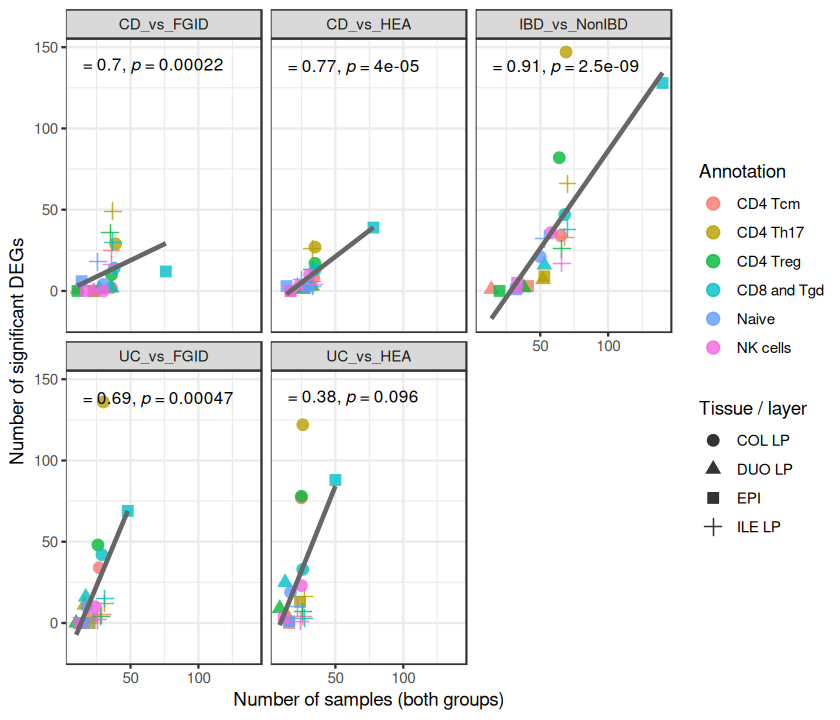

In [32]:
plot_df2 %>%
  filter(is.finite(n), is.finite(n_samples)) %>%
  ggplot(aes(
    x = n_samples,
    y = n,
    colour = annotation,
    shape = tissue_layer
  )) +
  geom_point(size = 3, alpha = 0.8) +
  geom_smooth(
    aes(group = 1),
    method = "lm",
    se = FALSE,
    colour = "grey40"
  ) +
  stat_cor(
    aes(group = 1),
    method = "spearman",
    cor.coef.name = "rho",
    colour = "black",
    label.x.npc = "left",
    label.y.npc = "top",
    size = 3.5
  ) +
  facet_wrap(~ test) +
  labs(
    x = "Number of samples (both groups)",
    y = "Number of significant DEGs",
    colour = "Annotation",
    shape = "Tissue / layer"
  ) +
  theme_bw()

`geom_smooth()` using formula = 'y ~ x'


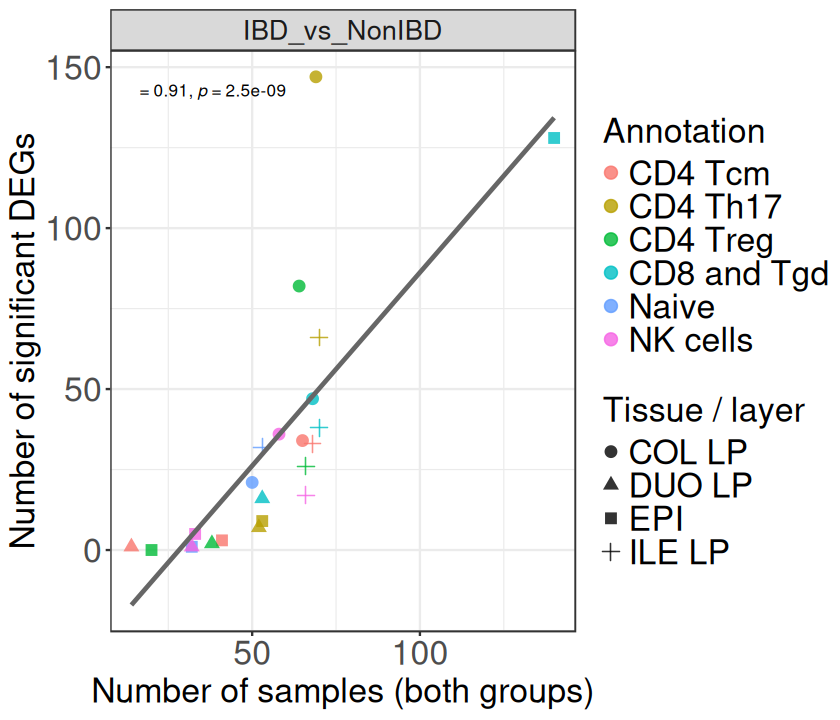

In [35]:
plot_df2 %>%
  filter(is.finite(n), is.finite(n_samples), test == "IBD_vs_NonIBD") %>%
  ggplot(aes(
    x = n_samples,
    y = n,
    colour = annotation
  )) +
  geom_point(size = 3, alpha = 0.8, aes(shape = tissue_layer)) +
  geom_smooth(
    aes(group = 1),
    method = "lm",
    se = FALSE,
    colour = "grey40"
  ) +
  stat_cor(
    aes(group = 1),
    method = "spearman",
    cor.coef.name = "rho",
    colour = "black",
    label.x.npc = "left",
    label.y.npc = "top",
    size = 3.5
  ) +
  facet_wrap(~ test) +
  labs(
    x = "Number of samples (both groups)",
    y = "Number of significant DEGs",
    colour = "Annotation",
    shape = "Tissue / layer"
  ) +
  theme_bw() + 
ggtheme()

In [36]:
ggsave("figures/DEG_testing/correlation_sample_vs_DEGcount.svg", width = 16, height = 12, units = "cm", create.dir = T)

`geom_smooth()` using formula = 'y ~ x'


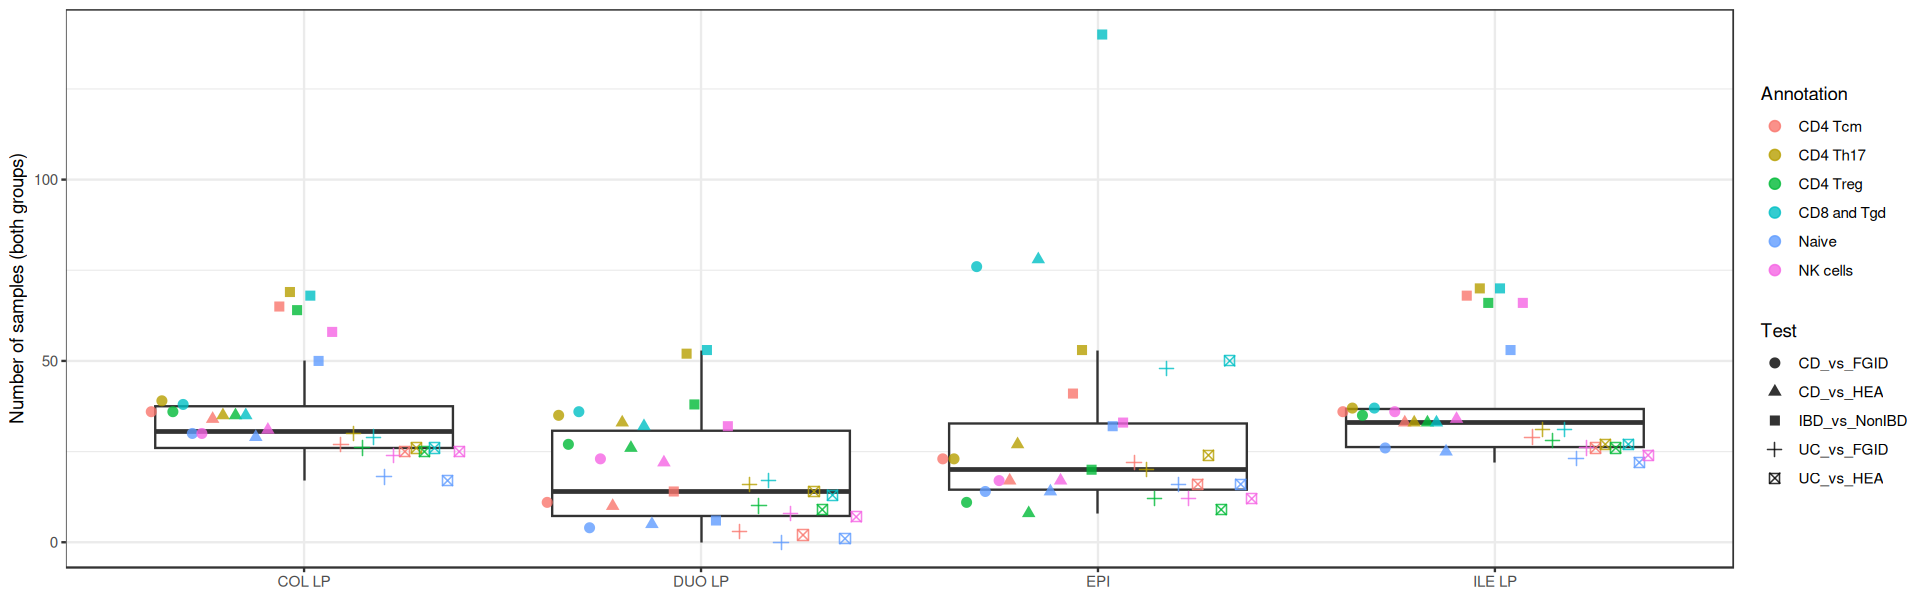

In [28]:
ggplot(
  plot_df2,
  aes(x = tissue_layer, y = n_samples)
) +
  geom_boxplot(
    outlier.shape = NA,
    position = position_dodge(width = 0.8)
  ) +
  geom_point(
    aes(shape = test, colour = annotation),
    position = position_jitterdodge(
      jitter.width = 0.15,
      dodge.width = 0.8,
      seed = 123
    ),
    size = 2.5,
    alpha = 0.8
  ) +
  labs(
    x = NULL,
    y = "Number of samples (both groups)",
    colour = "Annotation",
    shape = "Test"
  ) +
  theme_bw()

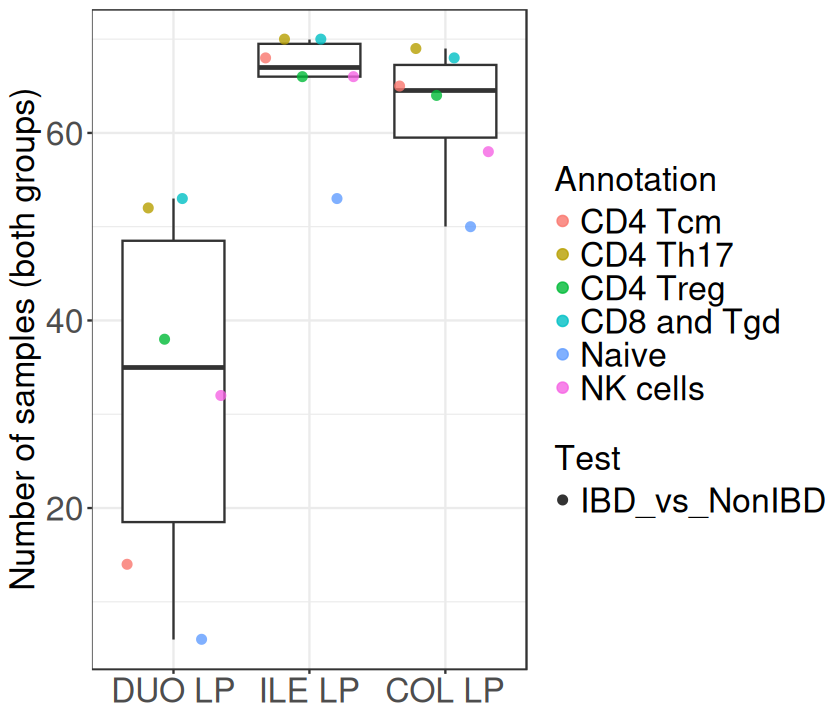

In [31]:
options(repr.plot.width = 7, repr.plot.height = 6)
plot_df2  %>% 
dplyr::filter(test == "IBD_vs_NonIBD" & tissue_layer != "EPI")  %>% 
  ggplot(
  aes(x = factor(tissue_layer, levels = c("DUO LP","ILE LP","COL LP")), y = n_samples)
) +
  geom_boxplot(
    outlier.shape = NA,
    position = position_dodge(width = 0.8)
  ) +
  geom_point(
    aes(shape = test, colour = annotation),
    position = position_jitterdodge(
      jitter.width = 0.15,
      dodge.width = 0.8,
      seed = 123
    ),
    size = 2.5,
    alpha = 0.8
  ) +
  labs(
    x = NULL,
    y = "Number of samples (both groups)",
    colour = "Annotation",
    shape = "Test"
  ) +
  theme_bw() +
ggtheme()

In [22]:
sample_counts_total

annotation,tissue_layer,test,n_samples
<chr>,<chr>,<chr>,<int>
CD4 Tcm,COL LP,IBD_vs_NonIBD,65
CD4 Tcm,COL LP,UC_vs_FGID,27
CD4 Tcm,COL LP,CD_vs_FGID,36
CD4 Tcm,COL LP,UC_vs_HEA,25
CD4 Tcm,COL LP,CD_vs_HEA,34
CD4 Th17,COL LP,IBD_vs_NonIBD,69
CD4 Th17,COL LP,UC_vs_FGID,30
CD4 Th17,COL LP,CD_vs_FGID,39
CD4 Th17,COL LP,UC_vs_HEA,26


# Counts of DEGs

In [ ]:
# Set your input folders
input_3p <- "tables/deg_patient_level_3p_20261019_090412/"
input_5p <- "tables/deg_patient_level_5p_20261022_095445/"

test_use <- "IBD_vs_NonIBD"
p_column <- "p_val_adj"
p_cutoff <- 0.05

annotations <- c(
  "Naive",
  "CD4 Tcm",
  "CD4 Th17",
  "CD4 Treg",
  "CD8 and Tgd",
  "NK cells"
)

annotation_labels <- c(
  "Naive" = "Naive T cells",
  "CD4 Tcm" = "CD4 Tcm+Tfh",
  "CD4 Th17" = "CD4 Th17",
  "CD4 Treg" = "CD4 Treg",
  "CD8 and Tgd" = "CD8 and Tgd",
  "NK cells" = "NK cells"
)

# ---- Locate expected result files ----
file_table <- expand_grid(
  prime = c("3p", "5p"),
  tissue_layer = c("ILE LP", "COL LP"),
  annotation = annotations
) %>%
  mutate(
    root = if_else(prime == "3p", input_3p, input_5p),
    file = file.path(
      root, tissue_layer, test_use,
      paste0(annotation, ".csv")
    ),
    available = file.exists(file)
  )

# Missing files represent unavailable tests, not zero DEGs
missing_results <- file_table %>%
  filter(!available) %>%
  select(prime, tissue_layer, annotation, file)

if (nrow(missing_results) > 0L) {
  message("Missing result files; these bars will be omitted:")
  print(missing_results)
}

# ---- Count significant genes ----
deg_counts <- file_table %>%
  filter(available) %>%
  select(prime, tissue_layer, annotation, file) %>%
  pmap_dfr(function(prime, tissue_layer, annotation, file) {

    dat <- read.csv(
      file,
      check.names = FALSE,
      stringsAsFactors = FALSE
    )

    if (!all(c("gene", p_column) %in% names(dat))) {
      stop("Missing gene or ", p_column, " column in: ", file)
    }

    sig <- !is.na(dat[[p_column]]) &
      dat[[p_column]] < p_cutoff &
      !is.na(dat$gene) &
      nzchar(dat$gene)

    tibble(
      prime = prime,
      tissue_layer = tissue_layer,
      annotation = annotation,
      n_deg = n_distinct(dat$gene[sig])
    )
  }) %>%
  mutate(
    prime = factor(prime, levels = c("3p", "5p")),
    tissue_layer = factor(
      tissue_layer,
      levels = c("ILE LP", "COL LP")
    ),
    annotation = factor(annotation, levels = annotations)
  )

prime,tissue_layer,annotation,n_deg
<fct>,<fct>,<fct>,<int>
3p,ILE LP,Naive,8
3p,ILE LP,CD4 Tcm,22
3p,ILE LP,CD4 Th17,14
3p,ILE LP,CD4 Treg,20
3p,ILE LP,CD8 and Tgd,8
3p,ILE LP,NK cells,3
3p,COL LP,Naive,0
3p,COL LP,CD4 Tcm,5
3p,COL LP,CD4 Th17,28


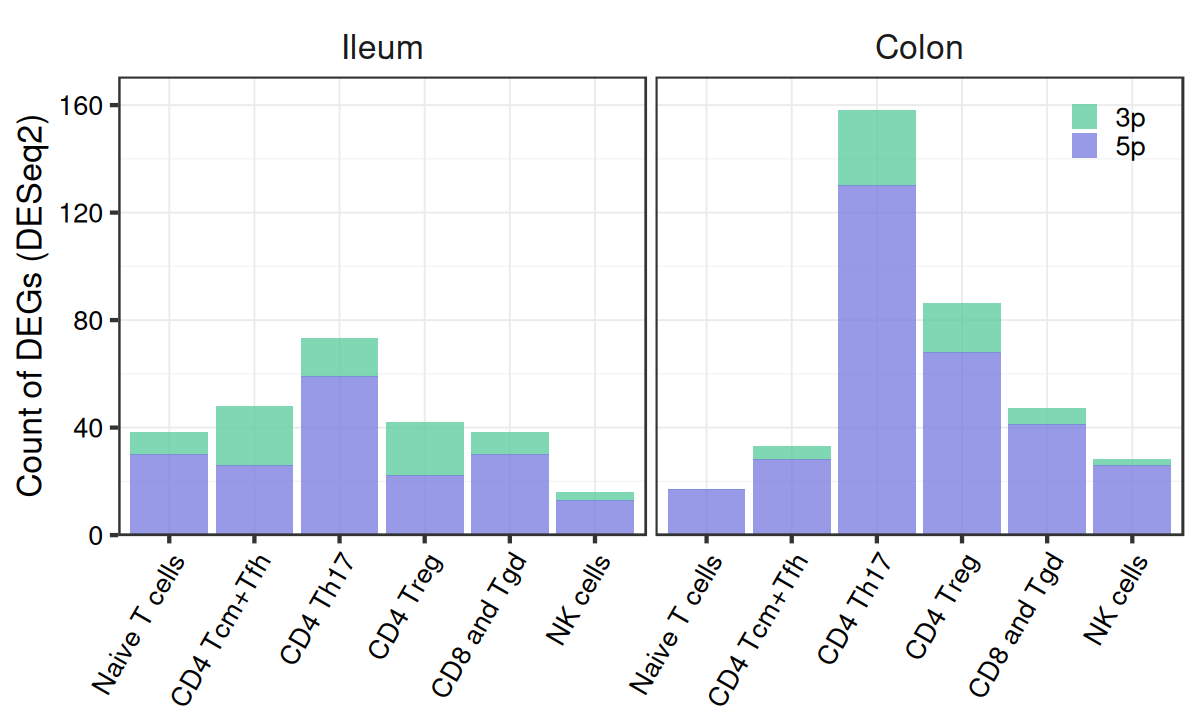

In [72]:
# ---- Plot overlapping bars ----
# Draw 3p first, then 5p, to match the reference
p <- ggplot(
  deg_counts,
  aes(x = annotation, y = n_deg, fill = prime)
) +
  geom_col(
    position = position_stack(),
    width = 0.9,
    alpha = 0.75
  ) +
  facet_grid(
    cols = vars(tissue_layer),
    labeller = labeller(
      tissue_layer = c(
        "ILE LP" = "Ileum",
        "COL LP" = "Colon"
      )
    )
  ) +
  scale_fill_manual(
    name = NULL,
    values = c(
      "3p" = "#55C99A",
      "5p" = "#7779DF"
    ),
    limits = c("3p", "5p"),
    drop = FALSE
  ) +
  scale_x_discrete(
    labels = annotation_labels,
    drop = FALSE
  ) +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.08))
  ) +
  labs(
    x = NULL,
    y = "Count of DEGs (DESeq2)"
  ) +
  theme_bw(base_size = 20) +
  theme(
    axis.text.x = element_text(
      angle = 60,
      hjust = 1,
      vjust = 1,
      colour = "black"
    ),
    axis.text.y = element_text(colour = "black"),
    strip.background = element_blank(),
    strip.text = element_text(size = 20),
    panel.grid.major = element_line(
      colour = "grey92",
      linewidth = 0.4
    ),
    panel.grid.minor = element_line(
      colour = "grey95",
      linewidth = 0.25
    ),
    panel.spacing.x = grid::unit(0.2, "cm"),
    legend.position = "inside",
    legend.position.inside = c(0.98, 0.98),
    legend.justification = c(1, 1),
    legend.background = element_blank(),
    legend.key = element_blank()
  )

options(repr.plot.width = 10, repr.plot.height = 6)

p

# Source data
deg_counts

In [73]:
ggsave(
  filename = "figures/DEG_counts_ILE_COL_stacked.svg",
  plot = p,
  device = svglite::svglite,
  width = 10,
  height = 7,
  units = "in",
  bg = "white"
)

In [95]:

readr::write_csv2(
  deg_counts,
  "DEG_counts_ILE_COL_stacked_source_data.csv"
)

# Influence of inflammation

In [76]:
aggexp_5p@meta.data  %>% colnames

[1] "orig.ident"         "cluster_sample"     "annotations_coarse"
 [4] "timepoint"          "tissue"             "layer"             
 [7] "participant_id"     "diagnosis"          "antitnf_response"  
[10] "tissue_layer"

In [78]:
md_5p_new  <- read_csv("data/predict_5p_metadata_20260819.csv")

Rows: 1382 Columns: 56
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (50): sample, data_folder, diagnosis, subgroup_primary, subgroup_second...
dbl   (4): days, severity_score, weighted_severity_score, age
date  (2): dob, collection_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [ ]:
md_5p_new$col_inflammation

In [83]:
inflammation_md  <- md_5p_new  %>% dplyr::filter(participant_id %in% aggexp_5p$participant_id, 
                             tissue %in% c("ILE","COL"), 
                            layer == "LP",
                            timepoint == "T0")  %>% 
group_by(tissue, participant_id, col_inflammation, ile_inflammation)  %>% 
tally()  %>% 
mutate(inflammation = if_else(tissue == "COL", col_inflammation, ile_inflammation))  %>% 
ungroup  %>% 
dplyr::select(tissue, participant_id, inflammation) 

In [84]:
md  <- aggexp_5p@meta.data  %>% left_join(inflammation_md)

Joining with `by = join_by(tissue, participant_id)`


In [85]:
rownames(md)  <- colnames(aggexp_5p)

In [86]:
aggexp_5p@meta.data  <- md

In [87]:
aggexp_5p$inflammation  %>% table

.
  N   Y 
463 526 

In [89]:
aggexp_5p$inflammation  <- if_else(aggexp_5p$inflammation == "N","no","yes" )

In [91]:
aggexp_5p$inflammation  %>% table 

.
 no yes 
463 526 

In [92]:
aggexp_5p_filt  <- subset(aggexp_5p, inflammation %in% c("no","yes"))

Warning message:
“Removing 292 cells missing data for vars requested”



 no yes 
463 526 


Starting: Naive / ILE LP / inflammation=no

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

Starting: Naive / ILE LP / inflammation=yes

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

Starting: Naive / COL LP / inflammation=no

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

Starting: Naive / COL LP / inflammation=yes

Skipping: Naive / COL LP / inflammation=yes; IBD=27, NonIBD=2

Starting: CD4 Tcm / ILE LP / inflammation=no

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

Starting: CD4 Tcm / ILE LP / inflammation=yes

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

Starting: CD4 Tcm / COL LP / inflammation

# A tibble: 24 × 9
   annotation  tissue_layer inflammation test      n_IBD n_NonIBD n_genes_tested
   <chr>       <chr>        <chr>        <chr>     <int>    <int>          <int>
 1 Naive       ILE LP       no           IBD_vs_N…    12       16            759
 2 Naive       ILE LP       yes          IBD_vs_N…    21        4            779
 3 Naive       COL LP       no           IBD_vs_N…     5       16            739
 4 Naive       COL LP       yes          IBD_vs_N…    27        2             NA
 5 CD4 Tcm     ILE LP       no           IBD_vs_N…    14       23            771
 6 CD4 Tcm     ILE LP       yes          IBD_vs_N…    27        4            780
 7 CD4 Tcm     COL LP       no           IBD_vs_N…     6       22            748
 8 CD4 Tcm     COL LP       yes          IBD_vs_N…    35        2             NA
 9 CD4 Th17    ILE LP       no           IBD_vs_N…    15       24            777
10 CD4 Th17    ILE LP       yes          IBD_vs_N…    27        4            776
11 CD4 Th

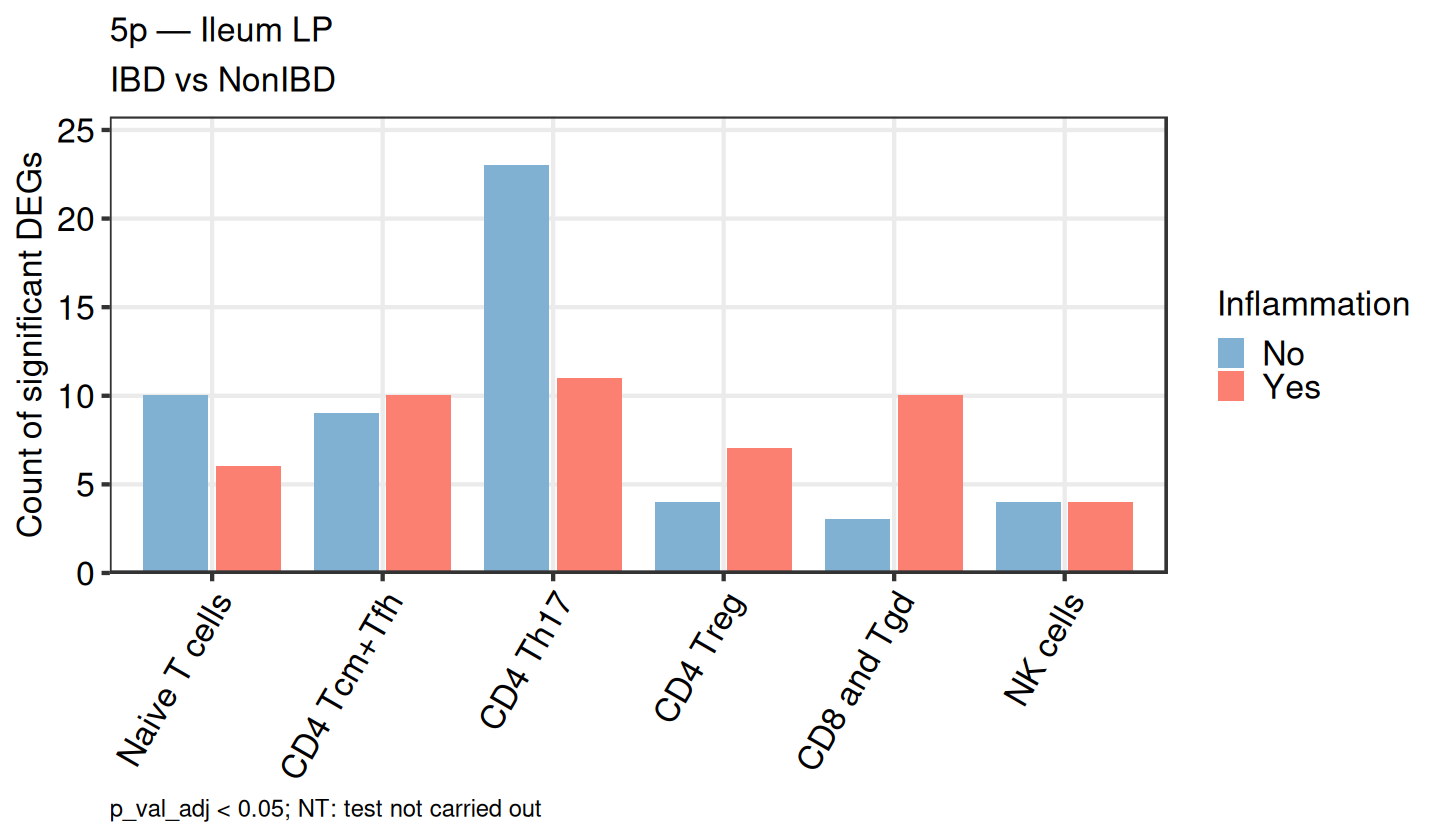

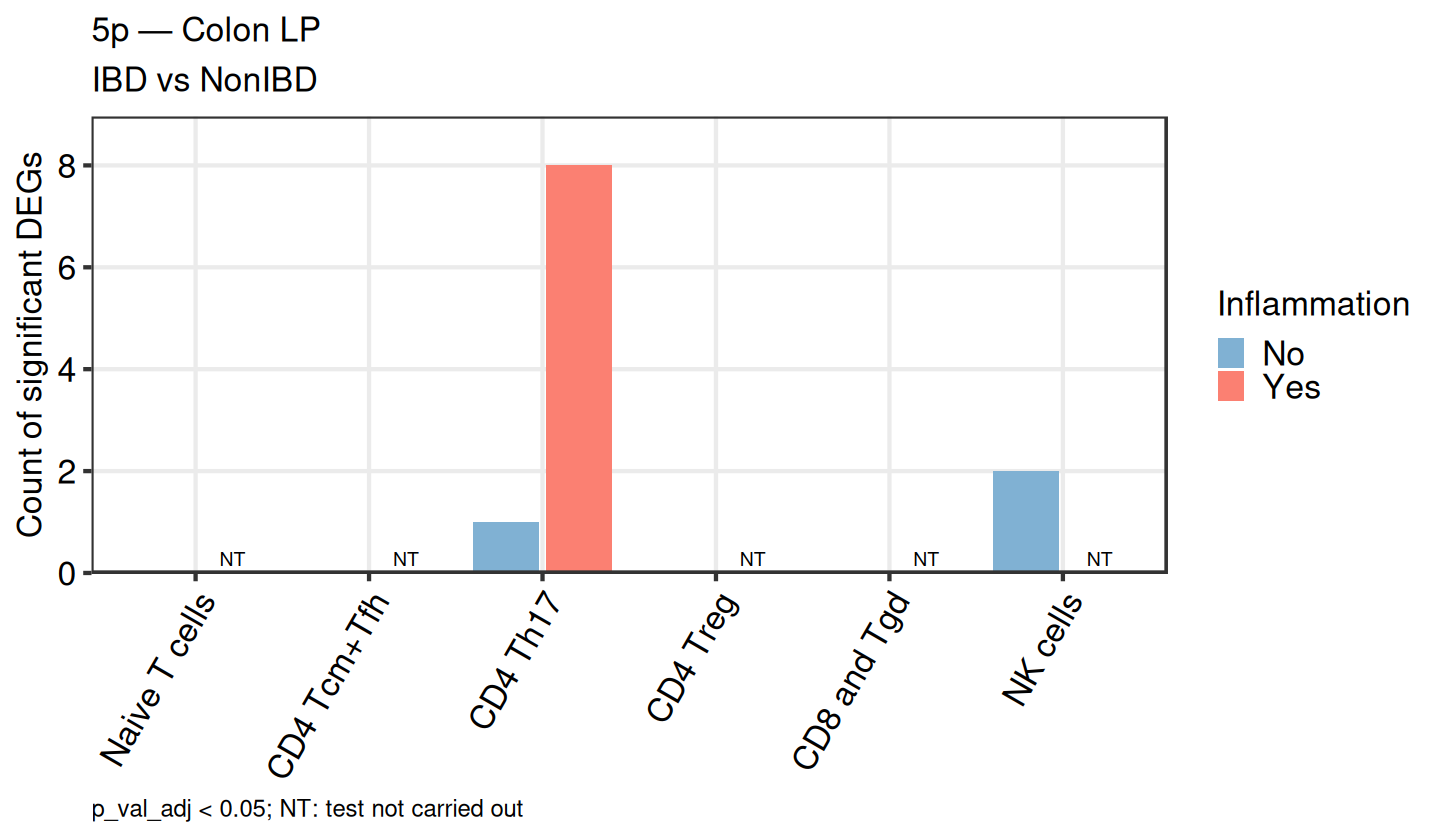

In [93]:
library(Seurat)
library(future)
library(furrr)
library(dplyr)
library(tidyr)
library(ggplot2)

# ---- Settings ----
# Use the same requested gene vector as your previous analysis
stopifnot(is.character(genes))

annotations <- c(
  "Naive",
  "CD4 Tcm",
  "CD4 Th17",
  "CD4 Treg",
  "CD8 and Tgd",
  "NK cells"
)

tissues <- c("ILE LP", "COL LP")

p_column <- "p_val_adj"  # Alternatively: "p_val_fdr"
p_cutoff <- 0.05
workers <- 2

out_dir <- file.path(
  "tables",
  paste0(
    "deg_5p_by_inflammation_",
    format(Sys.time(), "%Y%m%d_%H%M%S")
  )
)

dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

# ---- Extract counts and metadata once ----
plan(sequential)

counts_all <- GetAssayData(
  aggexp_5p_filt,
  assay = "RNA",
  layer = "counts"
)

metadata_all <- aggexp_5p_filt[[]]

stopifnot(
  length(dim(counts_all)) == 2L,
  !is.null(rownames(counts_all)),
  !is.null(colnames(counts_all)),
  all(colnames(counts_all) %in% rownames(metadata_all)),
  all(
    c(
      "diagnosis", "tissue", "layer",
      "annotations_coarse", "inflammation"
    ) %in% names(metadata_all)
  )
)

metadata_all <- metadata_all[
  colnames(counts_all), , drop = FALSE
]

metadata_all$tissue_layer <- paste(
  metadata_all$tissue,
  metadata_all$layer
)

# Preserve diagnosis2 if already defined
if (!"diagnosis2" %in% names(metadata_all)) {
  metadata_all$diagnosis2 <- ifelse(
    metadata_all$diagnosis %in% c("UC", "CD"),
    "IBD",
    "NonIBD"
  )
}

# Standardize capitalization and whitespace
metadata_all$inflammation_group <- tolower(
  trimws(as.character(metadata_all$inflammation))
)

# Inspect available inflammation labels
print(table(
  metadata_all$inflammation_group,
  useNA = "ifany"
))

if (!all(c("yes", "no") %in% metadata_all$inflammation_group)) {
  stop("The inflammation column must contain both 'yes' and 'no'.")
}

# ---- Jobs ----
jobs_inflammation <- expand_grid(
  annotation = annotations,
  tissue_layer = tissues,
  inflammation = c("no", "yes")
)

for (j in seq_len(nrow(jobs_inflammation))) {
  dir.create(
    file.path(
      out_dir,
      jobs_inflammation$tissue_layer[j],
      jobs_inflammation$inflammation[j]
    ),
    recursive = TRUE,
    showWarnings = FALSE
  )
}

# ---- Analyze one annotation × tissue × inflammation group ----
run_inflammation_job <- function(job_id) {

  future::plan(future::sequential)

  job <- jobs_inflammation[job_id, ]

  label <- paste(
    job$annotation,
    job$tissue_layer,
    paste0("inflammation=", job$inflammation),
    sep = " / "
  )

  message("Starting: ", label)

  selected <- which(
    metadata_all$annotations_coarse == job$annotation &
    metadata_all$tissue_layer == job$tissue_layer &
    metadata_all$inflammation_group == job$inflammation
  )

  md <- metadata_all[selected, , drop = FALSE]

  n_ibd <- sum(md$diagnosis2 == "IBD", na.rm = TRUE)
  n_nonibd <- sum(md$diagnosis2 == "NonIBD", na.rm = TRUE)

  # Every job returns a status row, including skipped tests
  finish <- function(status, n_deg = NA_integer_,
                     n_genes_tested = NA_integer_) {
    tibble(
      annotation = job$annotation,
      tissue_layer = job$tissue_layer,
      inflammation = job$inflammation,
      test = "IBD_vs_NonIBD",
      n_IBD = n_ibd,
      n_NonIBD = n_nonibd,
      n_genes_tested = n_genes_tested,
      n_deg = n_deg,
      status = status
    )
  }

  if (n_ibd < 3L || n_nonibd < 3L) {
    message(
      "Skipping: ", label,
      "; IBD=", n_ibd,
      ", NonIBD=", n_nonibd
    )
    return(finish("Insufficient samples"))
  }

  # Extract matrix directly, preserving dimensions
  counts <- round(
    counts_all[, rownames(md), drop = FALSE]
  )

  keep_genes <- Matrix::rowSums(counts > 0) >= 3L

  if (!any(keep_genes)) {
    return(finish("No genes pass expression filter"))
  }

  counts <- counts[keep_genes, , drop = FALSE]

  obj <- CreateSeuratObject(
    counts = counts,
    meta.data = md,
    assay = "RNA",
    min.cells = 0,
    min.features = 0
  )

  obj <- NormalizeData(obj, verbose = FALSE)

  features_use <- intersect(genes, rownames(obj))

  if (length(features_use) == 0L) {
    return(finish("No requested genes available"))
  }

  Idents(obj) <- obj$diagnosis2

  deg <- FindMarkers(
    obj,
    assay = "RNA",
    ident.1 = "IBD",
    ident.2 = "NonIBD",
    features = features_use,
    slot = "counts",
    test.use = "DESeq2",
    min.pct = 0.2,
    min.cells.feature = 3,
    verbose = FALSE
  )

  # Keep Bonferroni and add BH-adjusted values
  deg$p_val_fdr <- p.adjust(deg$p_val, method = "BH")

  nr <- nrow(deg)

  deg$gene <- rownames(deg)
  deg$annotation <- rep(job$annotation, nr)
  deg$tissue_layer <- rep(job$tissue_layer, nr)
  deg$inflammation <- rep(job$inflammation, nr)
  deg$test <- rep("IBD_vs_NonIBD", nr)

  write.csv(
    deg,
    file.path(
      out_dir,
      job$tissue_layer,
      job$inflammation,
      paste0(job$annotation, ".csv")
    ),
    row.names = FALSE
  )

  significant <- !is.na(deg[[p_column]]) &
    deg[[p_column]] < p_cutoff

  finish(
    status = "Completed",
    n_deg = dplyr::n_distinct(deg$gene[significant]),
    n_genes_tested = nr
  )
}

# ---- Run in parallel ----
options(future.globals.maxSize = 16 * 1024^3)
plan(multisession, workers = workers)

job_results <- tryCatch(
  future_map(
    seq_len(nrow(jobs_inflammation)),
    run_inflammation_job,
    .options = furrr_options(
      packages = c("Seurat", "DESeq2"),
      seed = 123
    )
  ),
  finally = plan(sequential)
)

deg_counts_inflammation <- bind_rows(job_results)

write.csv(
  deg_counts_inflammation,
  file.path(out_dir, "DEG_counts_and_sample_sizes.csv"),
  row.names = FALSE
)

# Check completed/skipped tests and diagnosis-group sizes
print(deg_counts_inflammation, n = Inf)

# ---- Plot ----
plot_data <- deg_counts_inflammation %>%
  mutate(
    annotation = factor(annotation, levels = annotations),
    inflammation = factor(
      inflammation,
      levels = c("no", "yes")
    ),
    skipped_label = if_else(status == "Completed", "", "NT")
  )

annotation_labels <- c(
  "Naive" = "Naive T cells",
  "CD4 Tcm" = "CD4 Tcm+Tfh",
  "CD4 Th17" = "CD4 Th17",
  "CD4 Treg" = "CD4 Treg",
  "CD8 and Tgd" = "CD8 and Tgd",
  "NK cells" = "NK cells"
)

make_inflammation_plot <- function(tissue_use) {

  dat <- plot_data %>%
    filter(tissue_layer == tissue_use)

  ggplot(
    dat,
    aes(
      x = annotation,
      y = n_deg,
      fill = inflammation,
      group = inflammation
    )
  ) +
    geom_col(
      position = position_dodge(width = 0.85),
      width = 0.75,
      na.rm = TRUE
    ) +
    geom_text(
      aes(y = 0, label = skipped_label),
      position = position_dodge(width = 0.85),
      vjust = -0.5,
      size = 4
    ) +
    scale_fill_manual(
      name = "Inflammation",
      values = c(
        "no" = "#80B1D3",
        "yes" = "#FB8072"
      ),
      labels = c(
        "no" = "No",
        "yes" = "Yes"
      ),
      drop = FALSE
    ) +
    scale_x_discrete(
      labels = annotation_labels,
      drop = FALSE
    ) +
    scale_y_continuous(
      expand = expansion(mult = c(0, 0.12))
    ) +
    labs(
      title = paste0(
        "5p — ",
        if (tissue_use == "ILE LP") "Ileum LP" else "Colon LP"
      ),
      subtitle = "IBD vs NonIBD",
      x = NULL,
      y = "Count of significant DEGs",
      caption = paste0(
        p_column, " < ", p_cutoff,
        "; NT: test not carried out"
      )
    ) +
    theme_bw(base_size = 20) +
    theme(
      axis.text = element_text(size = 20, colour = "black"),
      axis.text.x = element_text(
        angle = 60, hjust = 1, vjust = 1
      ),
      legend.text = element_text(size = 20),
      plot.title = element_text(size = 20),
      plot.subtitle = element_text(size = 20),
      plot.caption = element_text(size = 14, hjust = 0),
      panel.grid.minor = element_blank()
    )
}

p_ile <- make_inflammation_plot("ILE LP")
p_col <- make_inflammation_plot("COL LP")

options(repr.plot.width = 12, repr.plot.height = 7)

p_ile
p_col

# ---- Save plots ----
ggsave(
  file.path(out_dir, "CD_ILE_LP_DEG_counts_by_inflammation.svg"),
  p_ile,
  device = svglite::svglite,
  width = 12, height = 7, units = "in",
  bg = "white"
)

ggsave(
  file.path(out_dir, "CD_COL_LP_DEG_counts_by_inflammation.svg"),
  p_col,
  device = svglite::svglite,
  width = 12, height = 7, units = "in",
  bg = "white"
)

# Response with Limma

## 5p response Limma

In [278]:
library(limma)


Attaching package: ‘limma’


The following object is masked from ‘package:BiocGenerics’:

    plotMA




In [275]:
aggexp_5p$antitnf_response  %>% table

.
     FR     NOA      NR      PR Unknown 
    358     956      52     289      30 

In [276]:
## DEG ILE LP

aggexp_5p_ile_lp  <- subset(aggexp_5p, layer == "LP" &  tissue == "ILE")

ds_sub  <- aggexp_5p_ile_lp

DefaultAssay(ds_sub) <- "RNA"

# Recode: NOA or NM = 0, FR or RESP = 1, PR = 2
ds_sub$severity <- NA_integer_
ds_sub$severity[ds_sub$antitnf_response %in% c("NOA", "NM")]  <- 0L
ds_sub$severity[ds_sub$antitnf_response %in% c("FR", "RESP")] <- 1L
ds_sub$severity[ds_sub$antitnf_response %in% c("PR")]         <- 2L

In [279]:
all_res <- list()
i <- 1

for (k in levels(factor(ds_sub$annotations_coarse))) {
  message("Processing cluster: ", k)

  # subset to one coarse annotation
  ds_sub2 <- subset(ds_sub, subset = annotations_coarse == k)

  # metadata for these samples
  md <- ds_sub2@meta.data

  # keep only samples with defined severity
  md <- md[!is.na(md$severity), , drop = FALSE]
  if (nrow(md) < 6) {  # trivial safeguard; adjust if you like
    message("  Skipping (too few samples with severity).")
    next
  }

  # counts per severity level (0,1,2)
  cnt <- table(md$severity)

  # require at least 3 samples in each severity level present
  # (you can also require all three levels to be present if you prefer)
  if (any(cnt < 3)) {
    message("  Skipping (less than 3 samples in some severity level).")
    next
  }

  # expression matrix: genes x samples (log-normalized data)
  expr <- Seurat::GetAssayData(ds_sub2, assay = "RNA", slot = "data")

  # make sure columns of expr match rows of metadata
  expr <- expr[, rownames(md), drop = FALSE]

  # design matrix: severity as numeric (0,1,2) for trend test
  design <- model.matrix(~ severity, data = md)
  # (add other covariates here if needed, e.g. + batch + sex)

  # fit limma model
  fit <- lmFit(expr, design)
  fit <- eBayes(fit)

  # extract all genes for the "severity" coefficient (trend across 0->2)
  tt <- topTable(fit, coef = "severity", number = Inf, sort.by = "P")

  if (nrow(tt) == 0) {
    message("  No results for this cluster.")
    next
  }

  tt$gene       <- rownames(tt)
  tt$annotation <- k
  tt$test       <- "severity_trend"

  all_res[[i]] <- tt
  i <- i + 1
}

deg_all_all <- if (length(all_res)) bind_rows(all_res) else NULL

if (is.null(deg_all_all)) {
  message("No clusters passed the sample-count filters or returned results.")
} else {
  message(sprintf("Finished. %d rows across %d annotations.",
                  nrow(deg_all_all),
                  length(unique(deg_all_all$annotation))))
}

Processing cluster: CD4 Tcm

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Th17

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Treg

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD8 and Tgd

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: Naive

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: NK cells

Warning message:
“Zero sample variances detected, have been offset away from zero”
Finished. 114798 rows across 6 annotations.



In [287]:
deg_all_all  %>% arrange(adj.P.Val)

,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene,annotation,test
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
FABP5...1,0.29923348,0.57651089,8.426085,6.016712e-13,1.151178e-08,16.438531,FABP5,CD4 Th17,severity_trend
CDCA7...2,0.12349994,0.14917918,8.049174,3.572621e-12,3.417747e-08,14.662064,CDCA7,CD4 Th17,severity_trend
RBPJ...3,0.16402483,0.98245503,7.502671,4.635580e-11,2.956418e-07,12.110249,RBPJ,CD4 Th17,severity_trend
CHN1...4,0.21769551,0.31290516,6.978812,5.232912e-10,1.967072e-06,9.702602,CHN1,CD4 Th17,severity_trend
CENPF...5,0.07355598,0.11798746,6.944827,6.115218e-10,1.967072e-06,9.548040,CENPF,CD4 Th17,severity_trend
SLAMF8...6,0.06750381,0.07118282,6.942929,6.168625e-10,1.967072e-06,9.539415,SLAMF8,CD4 Th17,severity_trend
LYN...7,0.08850489,0.11809662,6.863407,8.875236e-10,2.425856e-06,9.178661,LYN,CD4 Th17,severity_trend
CD38...8,0.19588347,0.63041967,6.647584,2.368338e-09,5.664176e-06,8.206145,CD38,CD4 Th17,severity_trend
TESC...9,0.16337141,0.37021854,6.512323,4.360727e-09,9.270422e-06,7.601921,TESC,CD4 Th17,severity_trend


In [290]:
deg_all_all  %>% dplyr::filter(adj.P.Val<0.05)  %>% group_by(annotation)  %>% tally()

annotation,n
<chr>,<int>
CD4 Th17,145
CD4 Treg,11


In [281]:
limma_ile_lp  <- deg_all_all

In [282]:
## DEG COL LP

aggexp_5p_COL_lp  <- subset(aggexp_5p, layer == "LP" &  tissue == "COL")

ds_sub  <- aggexp_5p_COL_lp

DefaultAssay(ds_sub) <- "RNA"

# Recode: NOA or NM = 0, FR or RESP = 1, PR = 2
ds_sub$severity <- NA_integer_
ds_sub$severity[ds_sub$antitnf_response %in% c("NOA", "NM")]  <- 0L
ds_sub$severity[ds_sub$antitnf_response %in% c("FR", "RESP")] <- 1L
ds_sub$severity[ds_sub$antitnf_response %in% c("PR")]         <- 2L

In [283]:
all_res <- list()
i <- 1

for (k in levels(factor(ds_sub$annotations_coarse))) {
  message("Processing cluster: ", k)

  # subset to one coarse annotation
  ds_sub2 <- subset(ds_sub, subset = annotations_coarse == k)

  # metadata for these samples
  md <- ds_sub2@meta.data

  # keep only samples with defined severity
  md <- md[!is.na(md$severity), , drop = FALSE]
  if (nrow(md) < 6) {  # trivial safeguard; adjust if you like
    message("  Skipping (too few samples with severity).")
    next
  }

  # counts per severity level (0,1,2)
  cnt <- table(md$severity)

  # require at least 3 samples in each severity level present
  # (you can also require all three levels to be present if you prefer)
  if (any(cnt < 3)) {
    message("  Skipping (less than 3 samples in some severity level).")
    next
  }

  # expression matrix: genes x samples (log-normalized data)
  expr <- Seurat::GetAssayData(ds_sub2, assay = "RNA", slot = "data")

  # make sure columns of expr match rows of metadata
  expr <- expr[, rownames(md), drop = FALSE]

  # design matrix: severity as numeric (0,1,2) for trend test
  design <- model.matrix(~ severity, data = md)
  # (add other covariates here if needed, e.g. + batch + sex)

  # fit limma model
  fit <- lmFit(expr, design)
  fit <- eBayes(fit)

  # extract all genes for the "severity" coefficient (trend across 0->2)
  tt <- topTable(fit, coef = "severity", number = Inf, sort.by = "P")

  if (nrow(tt) == 0) {
    message("  No results for this cluster.")
    next
  }

  tt$gene       <- rownames(tt)
  tt$annotation <- k
  tt$test       <- "severity_trend"

  all_res[[i]] <- tt
  i <- i + 1
}

deg_all_all <- if (length(all_res)) bind_rows(all_res) else NULL

if (is.null(deg_all_all)) {
  message("No clusters passed the sample-count filters or returned results.")
} else {
  message(sprintf("Finished. %d rows across %d annotations.",
                  nrow(deg_all_all),
                  length(unique(deg_all_all$annotation))))
}

Processing cluster: CD4 Tcm

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Th17

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Treg

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD8 and Tgd

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: Naive

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: NK cells

Warning message:
“Zero sample variances detected, have been offset away from zero”
Finished. 114798 rows across 6 annotations.



In [286]:
deg_all_all  %>% arrange(adj.P.Val)

,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene,annotation,test
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
CHN1...1,0.21351311,0.27193138,6.543873,4.071884e-09,7.790736e-05,7.7414468,CHN1,CD4 Th17,severity_trend
CASS4...2,0.10727500,0.21648862,6.221745,1.700535e-08,1.626816e-04,6.3280502,CASS4,CD4 Th17,severity_trend
HIVEP3...3,0.11840175,0.25596043,5.953603,5.485657e-08,3.498569e-04,5.1724503,HIVEP3,CD4 Th17,severity_trend
TOX2...4,0.13298983,0.18503024,5.789384,1.113407e-07,5.119573e-04,4.4752237,TOX2,CD4 Th17,severity_trend
FABP5...5,0.26730509,0.65226266,5.746482,1.337891e-07,5.119573e-04,4.2944802,FABP5,CD4 Th17,severity_trend
CD38...6,0.22390551,0.49615602,5.463583,4.429259e-07,1.412417e-03,3.1182137,CD38,CD4 Th17,severity_trend
ADGRG5...7,0.03534066,0.05711447,5.420723,5.298215e-07,1.448154e-03,2.9424870,ADGRG5,CD4 Th17,severity_trend
IGFBP4...8,0.11589718,0.23017644,5.344919,7.262294e-07,1.545757e-03,2.6333617,IGFBP4,CD4 Th17,severity_trend
DAPK2...9,0.13457012,0.20358711,5.344627,7.271110e-07,1.545757e-03,2.6321729,DAPK2,CD4 Th17,severity_trend


In [285]:
limma_COL_lp  <- deg_all_all

In [291]:
## DEG DUO LP

aggexp_5p_DUO_lp  <- subset(aggexp_5p, layer == "LP" &  tissue == "DUO")

ds_sub  <- aggexp_5p_DUO_lp

DefaultAssay(ds_sub) <- "RNA"

# Recode: NOA or NM = 0, FR or RESP = 1, PR = 2
ds_sub$severity <- NA_integer_
ds_sub$severity[ds_sub$antitnf_response %in% c("NOA", "NM")]  <- 0L
ds_sub$severity[ds_sub$antitnf_response %in% c("FR", "RESP")] <- 1L
ds_sub$severity[ds_sub$antitnf_response %in% c("PR")]         <- 2L

In [292]:
all_res <- list()
i <- 1

for (k in levels(factor(ds_sub$annotations_coarse))) {
  message("Processing cluster: ", k)

  # subset to one coarse annotation
  ds_sub2 <- subset(ds_sub, subset = annotations_coarse == k)

  # metadata for these samples
  md <- ds_sub2@meta.data

  # keep only samples with defined severity
  md <- md[!is.na(md$severity), , drop = FALSE]
  if (nrow(md) < 6) {  # trivial safeguard; adjust if you like
    message("  Skipping (too few samples with severity).")
    next
  }

  # counts per severity level (0,1,2)
  cnt <- table(md$severity)

  # require at least 3 samples in each severity level present
  # (you can also require all three levels to be present if you prefer)
  if (any(cnt < 3)) {
    message("  Skipping (less than 3 samples in some severity level).")
    next
  }

  # expression matrix: genes x samples (log-normalized data)
  expr <- Seurat::GetAssayData(ds_sub2, assay = "RNA", slot = "data")

  # make sure columns of expr match rows of metadata
  expr <- expr[, rownames(md), drop = FALSE]

  # design matrix: severity as numeric (0,1,2) for trend test
  design <- model.matrix(~ severity, data = md)
  # (add other covariates here if needed, e.g. + batch + sex)

  # fit limma model
  fit <- lmFit(expr, design)
  fit <- eBayes(fit)

  # extract all genes for the "severity" coefficient (trend across 0->2)
  tt <- topTable(fit, coef = "severity", number = Inf, sort.by = "P")

  if (nrow(tt) == 0) {
    message("  No results for this cluster.")
    next
  }

  tt$gene       <- rownames(tt)
  tt$annotation <- k
  tt$test       <- "severity_trend"

  all_res[[i]] <- tt
  i <- i + 1
}

deg_all_all <- if (length(all_res)) bind_rows(all_res) else NULL

if (is.null(deg_all_all)) {
  message("No clusters passed the sample-count filters or returned results.")
} else {
  message(sprintf("Finished. %d rows across %d annotations.",
                  nrow(deg_all_all),
                  length(unique(deg_all_all$annotation))))
}

Processing cluster: CD4 Tcm

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Th17

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Treg

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD8 and Tgd

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: Naive

  Skipping (less than 3 samples in some severity level).

Processing cluster: NK cells

Warning message:
“Zero sample variances detected, have been offset away from zero”
Finished. 95665 rows across 5 annotations.



In [293]:
deg_all_all  %>% arrange(adj.P.Val)

,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene,annotation,test
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
PRRG3...1,0.108330478,0.185223024,5.143422,2.214673e-06,0.02617939,1.67229888,PRRG3,CD4 Th17,severity_trend
NBEAL1...2,0.148583858,0.661810593,5.089016,2.736570e-06,0.02617939,1.46502007,NBEAL1,CD4 Th17,severity_trend
CHN1...3,0.073446056,0.149928008,4.699874,1.208472e-05,0.07707233,0.01441587,CHN1,CD4 Th17,severity_trend
CNTLN...4,0.015167465,0.019858523,4.231836,6.695670e-05,0.30088875,-1.64638362,CNTLN,CD4 Th17,severity_trend
SLAMF8...5,0.018809864,0.025542162,4.186587,7.863084e-05,0.30088875,-1.80151990,SLAMF8,CD4 Th17,severity_trend
DMXL1...6,0.057767750,0.369316540,4.095625,1.083218e-04,0.34542002,-2.11028514,DMXL1,CD4 Th17,severity_trend
P2RY14...7,0.016154931,0.020069008,3.905102,2.092969e-04,0.42123145,-2.74307908,P2RY14,CD4 Th17,severity_trend
TRAJ18...8,0.002457847,0.001849080,3.856719,2.467226e-04,0.42123145,-2.90066399,TRAJ18,CD4 Th17,severity_trend
VIM...9,-0.107238480,2.642146238,-3.855049,2.481227e-04,0.42123145,-2.90608123,VIM,CD4 Th17,severity_trend


In [294]:
deg_all_all  %>% dplyr::filter(adj.P.Val<0.05)  %>% group_by(annotation)  %>% tally()

annotation,n
<chr>,<int>
CD4 Th17,2


In [295]:
limma_DUO_lp  <- deg_all_all

In [296]:
## DEG EPI

aggexp_5p_EPI  <- subset(aggexp_5p, layer == "EPI")

ds_sub  <- aggexp_5p_EPI

DefaultAssay(ds_sub) <- "RNA"

# Recode: NOA or NM = 0, FR or RESP = 1, PR = 2
ds_sub$severity <- NA_integer_
ds_sub$severity[ds_sub$antitnf_response %in% c("NOA", "NM")]  <- 0L
ds_sub$severity[ds_sub$antitnf_response %in% c("FR", "RESP")] <- 1L
ds_sub$severity[ds_sub$antitnf_response %in% c("PR")]         <- 2L

In [297]:
all_res <- list()
i <- 1

for (k in levels(factor(ds_sub$annotations_coarse))) {
  message("Processing cluster: ", k)

  # subset to one coarse annotation
  ds_sub2 <- subset(ds_sub, subset = annotations_coarse == k)

  # metadata for these samples
  md <- ds_sub2@meta.data

  # keep only samples with defined severity
  md <- md[!is.na(md$severity), , drop = FALSE]
  if (nrow(md) < 6) {  # trivial safeguard; adjust if you like
    message("  Skipping (too few samples with severity).")
    next
  }

  # counts per severity level (0,1,2)
  cnt <- table(md$severity)

  # require at least 3 samples in each severity level present
  # (you can also require all three levels to be present if you prefer)
  if (any(cnt < 3)) {
    message("  Skipping (less than 3 samples in some severity level).")
    next
  }

  # expression matrix: genes x samples (log-normalized data)
  expr <- Seurat::GetAssayData(ds_sub2, assay = "RNA", slot = "data")

  # make sure columns of expr match rows of metadata
  expr <- expr[, rownames(md), drop = FALSE]

  # design matrix: severity as numeric (0,1,2) for trend test
  design <- model.matrix(~ severity, data = md)
  # (add other covariates here if needed, e.g. + batch + sex)

  # fit limma model
  fit <- lmFit(expr, design)
  fit <- eBayes(fit)

  # extract all genes for the "severity" coefficient (trend across 0->2)
  tt <- topTable(fit, coef = "severity", number = Inf, sort.by = "P")

  if (nrow(tt) == 0) {
    message("  No results for this cluster.")
    next
  }

  tt$gene       <- rownames(tt)
  tt$annotation <- k
  tt$test       <- "severity_trend"

  all_res[[i]] <- tt
  i <- i + 1
}

deg_all_all <- if (length(all_res)) bind_rows(all_res) else NULL

if (is.null(deg_all_all)) {
  message("No clusters passed the sample-count filters or returned results.")
} else {
  message(sprintf("Finished. %d rows across %d annotations.",
                  nrow(deg_all_all),
                  length(unique(deg_all_all$annotation))))
}

Processing cluster: CD4 Tcm

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Th17

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Treg

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD8 and Tgd

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: Naive

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: NK cells

Warning message:
“Zero sample variances detected, have been offset away from zero”
Finished. 114798 rows across 6 annotations.



In [298]:
deg_all_all  %>% arrange(adj.P.Val)

,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene,annotation,test
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
FRY...1,0.13774809,0.047997261,7.845755,8.611011e-09,0.0001647545,7.89810578,FRY,NK cells,severity_trend
DGCR11...2,0.01030135,0.008651453,4.889585,2.725810e-06,0.0466525610,1.32318729,DGCR11,CD8 and Tgd,severity_trend
CD79A...3,0.12107365,0.193927087,4.715218,5.757991e-06,0.0466525610,0.59885997,CD79A,CD8 and Tgd,severity_trend
TFRC...4,0.10593088,0.324519911,4.645811,7.716225e-06,0.0466525610,0.31585192,TFRC,CD8 and Tgd,severity_trend
PLA2G2A...5,0.21678510,0.405266823,4.577581,1.026059e-05,0.0466525610,0.04064638,PLA2G2A,CD8 and Tgd,severity_trend
DMBT1...6,0.15646481,0.255802935,4.535967,1.219165e-05,0.0466525610,-0.12572257,DMBT1,CD8 and Tgd,severity_trend
SPINT2...7,0.12298965,0.686868363,4.370866,2.391447e-05,0.0552492935,-0.77454213,SPINT2,CD8 and Tgd,severity_trend
CFB...8,0.04398981,0.066904322,4.365295,2.445714e-05,0.0552492935,-0.79611680,CFB,CD8 and Tgd,severity_trend
OLFM4...9,0.22633752,0.541922296,4.357049,2.528218e-05,0.0552492935,-0.82801231,OLFM4,CD8 and Tgd,severity_trend


In [299]:
deg_all_all  %>% dplyr::filter(adj.P.Val<0.05)  %>% group_by(annotation)  %>% tally()

annotation,n
<chr>,<int>
CD8 and Tgd,5
NK cells,1


In [300]:
limma_EPI  <- deg_all_all

In [301]:
limma_COL_lp$tissue  <- "COL LP"
limma_DUO_lp$tissue  <- "DUO LP"
limma_EPI$tissue  <- "EPI"
limma_ile_lp$tissue  <- "ILE LP"

In [302]:
all_limma_5p  <- rbind(limma_COL_lp, 
                       limma_DUO_lp, 
                       limma_EPI, 
                       limma_ile_lp)

In [303]:
all_limma_5p$prime  <- "5p"

## 3p response Limma

In [305]:
aggexp_3p$antitnf_response  %>% table

.
 FR NOA  PR 
 79 460 154 

In [306]:
## DEG ILE LP

aggexp_3p_ile_lp  <- subset(aggexp_3p, layer == "LP" &  tissue == "ILE")

ds_sub  <- aggexp_3p_ile_lp

DefaultAssay(ds_sub) <- "RNA"

# Recode: NOA or NM = 0, FR or RESP = 1, PR = 2
ds_sub$severity <- NA_integer_
ds_sub$severity[ds_sub$antitnf_response %in% c("NOA", "NM")]  <- 0L
ds_sub$severity[ds_sub$antitnf_response %in% c("FR", "RESP")] <- 1L
ds_sub$severity[ds_sub$antitnf_response %in% c("PR")]         <- 2L

In [307]:
all_res <- list()
i <- 1

for (k in levels(factor(ds_sub$annotations_coarse))) {
  message("Processing cluster: ", k)

  # subset to one coarse annotation
  ds_sub2 <- subset(ds_sub, subset = annotations_coarse == k)

  # metadata for these samples
  md <- ds_sub2@meta.data

  # keep only samples with defined severity
  md <- md[!is.na(md$severity), , drop = FALSE]
  if (nrow(md) < 6) {  # trivial safeguard; adjust if you like
    message("  Skipping (too few samples with severity).")
    next
  }

  # counts per severity level (0,1,2)
  cnt <- table(md$severity)

  # require at least 3 samples in each severity level present
  # (you can also require all three levels to be present if you prefer)
  if (any(cnt < 3)) {
    message("  Skipping (less than 3 samples in some severity level).")
    next
  }

  # expression matrix: genes x samples (log-normalized data)
  expr <- Seurat::GetAssayData(ds_sub2, assay = "RNA", slot = "data")

  # make sure columns of expr match rows of metadata
  expr <- expr[, rownames(md), drop = FALSE]

  # design matrix: severity as numeric (0,1,2) for trend test
  design <- model.matrix(~ severity, data = md)
  # (add other covariates here if needed, e.g. + batch + sex)

  # fit limma model
  fit <- lmFit(expr, design)
  fit <- eBayes(fit)

  # extract all genes for the "severity" coefficient (trend across 0->2)
  tt <- topTable(fit, coef = "severity", number = Inf, sort.by = "P")

  if (nrow(tt) == 0) {
    message("  No results for this cluster.")
    next
  }

  tt$gene       <- rownames(tt)
  tt$annotation <- k
  tt$test       <- "severity_trend"

  all_res[[i]] <- tt
  i <- i + 1
}

deg_all_all <- if (length(all_res)) bind_rows(all_res) else NULL

if (is.null(deg_all_all)) {
  message("No clusters passed the sample-count filters or returned results.")
} else {
  message(sprintf("Finished. %d rows across %d annotations.",
                  nrow(deg_all_all),
                  length(unique(deg_all_all$annotation))))
}

Processing cluster: CD4 Tcm

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Th17

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Treg

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD8 and Tgd

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: Naive

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: NK cells

Warning message:
“Zero sample variances detected, have been offset away from zero”
Finished. 104730 rows across 6 annotations.



In [308]:
deg_all_all  %>% arrange(adj.P.Val)

,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene,annotation,test
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
ADAM12...1,0.112966429,0.128922635,5.968288,8.108672e-07,0.007298658,3.23535917,ADAM12,CD4 Th17,severity_trend
CHN1...2,0.301343791,0.348205658,5.880777,1.059262e-06,0.007298658,2.96753209,CHN1,CD4 Th17,severity_trend
MKI67...3,0.037995094,0.030570601,5.812363,1.305501e-06,0.007298658,2.75817917,MKI67,CD4 Th17,severity_trend
HMGB3...4,0.040648672,0.044691614,5.731288,1.672565e-06,0.007298658,2.51016580,HMGB3,CD4 Th17,severity_trend
PLEK...5,0.180790252,0.381502150,6.088144,5.634215e-07,0.007546835,3.64722462,PLEK,CD4 Treg,severity_trend
MUC1...6,0.013453811,0.009178253,5.947717,8.647190e-07,0.007546835,3.21756262,MUC1,CD4 Treg,severity_trend
GOLIM4...7,0.128537182,0.100349824,5.628138,2.292533e-06,0.008003233,2.19481869,GOLIM4,CD4 Th17,severity_trend
C1QA...8,0.275905195,0.403022076,6.243917,5.072506e-07,0.008854060,3.89183329,C1QA,Naive,severity_trend
TRPS1...9,0.120588831,0.182788831,5.382451,4.856784e-06,0.014129193,1.44523742,TRPS1,CD4 Th17,severity_trend


In [309]:
deg_all_all  %>% dplyr::filter(adj.P.Val<0.05)  %>% group_by(annotation)  %>% tally()

annotation,n
<chr>,<int>
CD4 Tcm,15
CD4 Th17,29
CD4 Treg,5
NK cells,1
Naive,1


In [310]:
limma_ile_lp  <- deg_all_all

In [311]:
## DEG COL LP

aggexp_3p_COL_lp  <- subset(aggexp_3p, layer == "LP" &  tissue == "COL")

ds_sub  <- aggexp_3p_COL_lp

DefaultAssay(ds_sub) <- "RNA"

# Recode: NOA or NM = 0, FR or RESP = 1, PR = 2
ds_sub$severity <- NA_integer_
ds_sub$severity[ds_sub$antitnf_response %in% c("NOA", "NM")]  <- 0L
ds_sub$severity[ds_sub$antitnf_response %in% c("FR", "RESP")] <- 1L
ds_sub$severity[ds_sub$antitnf_response %in% c("PR")]         <- 2L

In [312]:
all_res <- list()
i <- 1

for (k in levels(factor(ds_sub$annotations_coarse))) {
  message("Processing cluster: ", k)

  # subset to one coarse annotation
  ds_sub2 <- subset(ds_sub, subset = annotations_coarse == k)

  # metadata for these samples
  md <- ds_sub2@meta.data

  # keep only samples with defined severity
  md <- md[!is.na(md$severity), , drop = FALSE]
  if (nrow(md) < 6) {  # trivial safeguard; adjust if you like
    message("  Skipping (too few samples with severity).")
    next
  }

  # counts per severity level (0,1,2)
  cnt <- table(md$severity)

  # require at least 3 samples in each severity level present
  # (you can also require all three levels to be present if you prefer)
  if (any(cnt < 3)) {
    message("  Skipping (less than 3 samples in some severity level).")
    next
  }

  # expression matrix: genes x samples (log-normalized data)
  expr <- Seurat::GetAssayData(ds_sub2, assay = "RNA", slot = "data")

  # make sure columns of expr match rows of metadata
  expr <- expr[, rownames(md), drop = FALSE]

  # design matrix: severity as numeric (0,1,2) for trend test
  design <- model.matrix(~ severity, data = md)
  # (add other covariates here if needed, e.g. + batch + sex)

  # fit limma model
  fit <- lmFit(expr, design)
  fit <- eBayes(fit)

  # extract all genes for the "severity" coefficient (trend across 0->2)
  tt <- topTable(fit, coef = "severity", number = Inf, sort.by = "P")

  if (nrow(tt) == 0) {
    message("  No results for this cluster.")
    next
  }

  tt$gene       <- rownames(tt)
  tt$annotation <- k
  tt$test       <- "severity_trend"

  all_res[[i]] <- tt
  i <- i + 1
}

deg_all_all <- if (length(all_res)) bind_rows(all_res) else NULL

if (is.null(deg_all_all)) {
  message("No clusters passed the sample-count filters or returned results.")
} else {
  message(sprintf("Finished. %d rows across %d annotations.",
                  nrow(deg_all_all),
                  length(unique(deg_all_all$annotation))))
}

Processing cluster: CD4 Tcm

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Th17

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Treg

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD8 and Tgd

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: Naive

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: NK cells

Warning message:
“Zero sample variances detected, have been offset away from zero”
Finished. 104730 rows across 6 annotations.



In [313]:
deg_all_all  %>% arrange(adj.P.Val)

,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene,annotation,test
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
TOX2...1,0.08847381,0.06601612,9.182077,3.969564e-11,6.928873e-07,13.242657,TOX2,CD4 Th17,severity_trend
FABP5...2,0.38101477,0.61834780,8.042032,1.114269e-09,9.724780e-06,9.862076,FABP5,CD4 Th17,severity_trend
NTRK2...3,0.05798697,0.03697807,7.130198,1.777771e-08,1.034366e-04,7.063854,NTRK2,CD4 Th17,severity_trend
APOBEC3H...4,0.10342672,0.13071844,6.823037,4.594069e-08,2.004737e-04,6.107286,APOBEC3H,CD4 Th17,severity_trend
RCAN2...5,0.05676150,0.03376992,6.618584,8.673345e-08,3.027865e-04,5.467883,RCAN2,CD4 Th17,severity_trend
CDCA7...6,0.09737398,0.08723720,6.541747,1.101995e-07,3.205886e-04,5.227153,CDCA7,CD4 Th17,severity_trend
IL1R2...7,0.31596449,0.67831968,7.070414,1.857355e-08,3.242014e-04,7.089836,IL1R2,CD4 Treg,severity_trend
SLAMF8...8,0.04648569,0.03744296,6.455339,1.443050e-07,3.598347e-04,4.956213,SLAMF8,CD4 Th17,severity_trend
DAPK2...9,0.11954767,0.11035779,6.391608,1.760947e-07,3.842165e-04,4.756254,DAPK2,CD4 Th17,severity_trend


In [314]:
limma_COL_lp  <- deg_all_all

In [315]:
## DEG DUO LP

aggexp_3p_DUO_lp  <- subset(aggexp_3p, layer == "LP" &  tissue == "DUO")

ds_sub  <- aggexp_3p_DUO_lp

DefaultAssay(ds_sub) <- "RNA"

# Recode: NOA or NM = 0, FR or RESP = 1, PR = 2
ds_sub$severity <- NA_integer_
ds_sub$severity[ds_sub$antitnf_response %in% c("NOA", "NM")]  <- 0L
ds_sub$severity[ds_sub$antitnf_response %in% c("FR", "RESP")] <- 1L
ds_sub$severity[ds_sub$antitnf_response %in% c("PR")]         <- 2L

In [316]:
all_res <- list()
i <- 1

for (k in levels(factor(ds_sub$annotations_coarse))) {
  message("Processing cluster: ", k)

  # subset to one coarse annotation
  ds_sub2 <- subset(ds_sub, subset = annotations_coarse == k)

  # metadata for these samples
  md <- ds_sub2@meta.data

  # keep only samples with defined severity
  md <- md[!is.na(md$severity), , drop = FALSE]
  if (nrow(md) < 6) {  # trivial safeguard; adjust if you like
    message("  Skipping (too few samples with severity).")
    next
  }

  # counts per severity level (0,1,2)
  cnt <- table(md$severity)

  # require at least 3 samples in each severity level present
  # (you can also require all three levels to be present if you prefer)
  if (any(cnt < 3)) {
    message("  Skipping (less than 3 samples in some severity level).")
    next
  }

  # expression matrix: genes x samples (log-normalized data)
  expr <- Seurat::GetAssayData(ds_sub2, assay = "RNA", slot = "data")

  # make sure columns of expr match rows of metadata
  expr <- expr[, rownames(md), drop = FALSE]

  # design matrix: severity as numeric (0,1,2) for trend test
  design <- model.matrix(~ severity, data = md)
  # (add other covariates here if needed, e.g. + batch + sex)

  # fit limma model
  fit <- lmFit(expr, design)
  fit <- eBayes(fit)

  # extract all genes for the "severity" coefficient (trend across 0->2)
  tt <- topTable(fit, coef = "severity", number = Inf, sort.by = "P")

  if (nrow(tt) == 0) {
    message("  No results for this cluster.")
    next
  }

  tt$gene       <- rownames(tt)
  tt$annotation <- k
  tt$test       <- "severity_trend"

  all_res[[i]] <- tt
  i <- i + 1
}

deg_all_all <- if (length(all_res)) bind_rows(all_res) else NULL

if (is.null(deg_all_all)) {
  message("No clusters passed the sample-count filters or returned results.")
} else {
  message(sprintf("Finished. %d rows across %d annotations.",
                  nrow(deg_all_all),
                  length(unique(deg_all_all$annotation))))
}

Processing cluster: CD4 Tcm

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Th17

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Treg

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD8 and Tgd

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: Naive

  Skipping (too few samples with severity).

Processing cluster: NK cells

Warning message:
“Zero sample variances detected, have been offset away from zero”
Finished. 87275 rows across 5 annotations.



In [317]:
deg_all_all  %>% arrange(adj.P.Val)

,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene,annotation,test
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
EPHB3...1,0.005145637,0.003982075,4.900540,1.981219e-05,0.3458218,-0.01119069,EPHB3,CD4 Th17,severity_trend
RFX4...2,0.002849029,0.001728595,4.429900,8.278233e-05,0.7224828,-1.42281978,RFX4,CD4 Th17,severity_trend
DNAH8...3,0.005337808,0.002694917,4.268617,1.342012e-04,0.7808272,-1.89720822,DNAH8,CD4 Th17,severity_trend
FBXO15...4,0.005668159,0.005627761,4.049118,2.570996e-04,0.8587065,-2.53313465,FBXO15,CD4 Th17,severity_trend
ETV7...5,0.034035959,0.068634449,4.022967,2.776275e-04,0.8587065,-2.60807150,ETV7,CD4 Th17,severity_trend
TRGV7...6,0.008094769,0.007596620,4.002071,2.951727e-04,0.8587065,-2.66781925,TRGV7,CD4 Th17,severity_trend
ALDH3A1...7,0.002364509,0.001193778,3.886193,4.138986e-04,0.9348191,-2.99688522,ALDH3A1,CD4 Th17,severity_trend
EFCAB5...8,0.006384569,0.006618883,3.874292,4.284476e-04,0.9348191,-3.03046011,EFCAB5,CD4 Th17,severity_trend
TGIF1...9,-0.258650070,0.637642152,-4.553984,1.502320e-04,0.9746868,-1.71782812,TGIF1,CD4 Tcm,severity_trend


In [318]:
deg_all_all  %>% dplyr::filter(adj.P.Val<0.05)  %>% group_by(annotation)  %>% tally()

annotation,n
<chr>,<int>


In [319]:
limma_DUO_lp  <- deg_all_all

In [320]:
## DEG EPI

aggexp_3p_EPI  <- subset(aggexp_3p, layer == "EPI")

ds_sub  <- aggexp_3p_EPI

DefaultAssay(ds_sub) <- "RNA"

# Recode: NOA or NM = 0, FR or RESP = 1, PR = 2
ds_sub$severity <- NA_integer_
ds_sub$severity[ds_sub$antitnf_response %in% c("NOA", "NM")]  <- 0L
ds_sub$severity[ds_sub$antitnf_response %in% c("FR", "RESP")] <- 1L
ds_sub$severity[ds_sub$antitnf_response %in% c("PR")]         <- 2L

In [321]:
all_res <- list()
i <- 1

for (k in levels(factor(ds_sub$annotations_coarse))) {
  message("Processing cluster: ", k)

  # subset to one coarse annotation
  ds_sub2 <- subset(ds_sub, subset = annotations_coarse == k)

  # metadata for these samples
  md <- ds_sub2@meta.data

  # keep only samples with defined severity
  md <- md[!is.na(md$severity), , drop = FALSE]
  if (nrow(md) < 6) {  # trivial safeguard; adjust if you like
    message("  Skipping (too few samples with severity).")
    next
  }

  # counts per severity level (0,1,2)
  cnt <- table(md$severity)

  # require at least 3 samples in each severity level present
  # (you can also require all three levels to be present if you prefer)
  if (any(cnt < 3)) {
    message("  Skipping (less than 3 samples in some severity level).")
    next
  }

  # expression matrix: genes x samples (log-normalized data)
  expr <- Seurat::GetAssayData(ds_sub2, assay = "RNA", slot = "data")

  # make sure columns of expr match rows of metadata
  expr <- expr[, rownames(md), drop = FALSE]

  # design matrix: severity as numeric (0,1,2) for trend test
  design <- model.matrix(~ severity, data = md)
  # (add other covariates here if needed, e.g. + batch + sex)

  # fit limma model
  fit <- lmFit(expr, design)
  fit <- eBayes(fit)

  # extract all genes for the "severity" coefficient (trend across 0->2)
  tt <- topTable(fit, coef = "severity", number = Inf, sort.by = "P")

  if (nrow(tt) == 0) {
    message("  No results for this cluster.")
    next
  }

  tt$gene       <- rownames(tt)
  tt$annotation <- k
  tt$test       <- "severity_trend"

  all_res[[i]] <- tt
  i <- i + 1
}

deg_all_all <- if (length(all_res)) bind_rows(all_res) else NULL

if (is.null(deg_all_all)) {
  message("No clusters passed the sample-count filters or returned results.")
} else {
  message(sprintf("Finished. %d rows across %d annotations.",
                  nrow(deg_all_all),
                  length(unique(deg_all_all$annotation))))
}

Processing cluster: CD4 Tcm

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD4 Th17

  Skipping (too few samples with severity).

Processing cluster: CD4 Treg

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: CD8 and Tgd

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: Naive

Warning message:
“Zero sample variances detected, have been offset away from zero”
Processing cluster: NK cells

  Skipping (too few samples with severity).

Finished. 69820 rows across 4 annotations.



In [322]:
deg_all_all  %>% arrange(adj.P.Val)

,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene,annotation,test
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
NUMB...1,-0.16450892,0.16450892,-31.710787,2.683250e-06,0.03727228,4.92045134,NUMB,Naive,severity_trend
CBR4...2,-0.15286496,0.15286496,-28.474337,4.270670e-06,0.03727228,4.35436301,CBR4,Naive,severity_trend
ST6GAL1...3,-0.16345532,0.16345532,-22.283330,1.228402e-05,0.07147250,3.06429748,ST6GAL1,Naive,severity_trend
VPS29...4,0.17453106,1.00090354,5.030749,9.416597e-06,0.10421741,1.06111537,VPS29,CD8 and Tgd,severity_trend
PSME2...5,0.20314739,2.04895606,4.784550,2.094351e-05,0.10421741,0.27238365,PSME2,CD8 and Tgd,severity_trend
EEF1A1...6,-0.31667585,4.42091776,-4.730475,2.493363e-05,0.10421741,0.10067932,EEF1A1,CD8 and Tgd,severity_trend
EHD1...7,-0.11000326,0.67462958,-4.719328,2.584475e-05,0.10421741,0.06535908,EHD1,CD8 and Tgd,severity_trend
CAPN1...8,-0.13449019,0.59714242,-4.674481,2.985317e-05,0.10421741,-0.07647489,CAPN1,CD8 and Tgd,severity_trend
CCL3...9,0.32325181,0.48035188,4.507880,5.084762e-05,0.12785936,-0.59945328,CCL3,CD8 and Tgd,severity_trend


In [323]:
deg_all_all  %>% dplyr::filter(adj.P.Val<0.05)  %>% group_by(annotation)  %>% tally()

annotation,n
<chr>,<int>
Naive,2


In [324]:
limma_EPI  <- deg_all_all

In [325]:
limma_COL_lp$tissue  <- "COL LP"
limma_DUO_lp$tissue  <- "DUO LP"
limma_EPI$tissue  <- "EPI"
limma_ile_lp$tissue  <- "ILE LP"

all_limma_3p  <- rbind(limma_COL_lp, 
                       limma_DUO_lp, 
                       limma_EPI, 
                       limma_ile_lp)

all_limma_3p$prime  <- "3p"

In [326]:
write.csv(all_limma_3p, "tables/251209_limma_response_3p.csv")
write.csv(all_limma_5p, "tables/251209_limma_response_5p.csv")

In [185]:
all_limma_3p  <- read_csv("../251029_VN_PREDICT3/tables/251209_limma_response_3p.csv")
all_limma_5p  <- read_csv("../251029_VN_PREDICT3/tables/251209_limma_response_5p.csv")


New names:
• `` -> `...1`
Rows: 366555 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (6): ...1, gene, annotation, test, tissue, prime
dbl (6): logFC, AveExpr, t, P.Value, adj.P.Val, B

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
New names:
• `` -> `...1`
Rows: 440059 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (6): ...1, gene, annotation, test, tissue, prime
dbl (6): logFC, AveExpr, t, P.Value, adj.P.Val, B

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [186]:
all_limma  <- rbind(all_limma_3p, all_limma_5p)

In [187]:
all_limma  %>% dplyr::filter(adj.P.Val < 0.05)  %>% 
group_by(prime, annotation, test)  %>% 
tally()  %>% 
arrange(desc(n))

prime,annotation,test,n
<chr>,<chr>,<chr>,<int>
5p,CD4 Th17,severity_trend,552
5p,CD4 Treg,severity_trend,160
3p,CD4 Th17,severity_trend,121
5p,CD8 and Tgd,severity_trend,47
3p,CD4 Tcm,severity_trend,29
5p,Naive,severity_trend,20
5p,CD4 Tcm,severity_trend,18
3p,CD4 Treg,severity_trend,12
5p,NK cells,severity_trend,5


In [188]:
all_limma  %>% dplyr::filter(adj.P.Val < 0.05)  %>% 
dplyr::filter(tissue != "EPI")  %>% 
group_by(prime, annotation, test, tissue)  %>% 
tally() 

prime,annotation,test,tissue,n
<chr>,<chr>,<chr>,<chr>,<int>
3p,CD4 Tcm,severity_trend,COL LP,14
3p,CD4 Tcm,severity_trend,ILE LP,15
3p,CD4 Th17,severity_trend,COL LP,92
3p,CD4 Th17,severity_trend,ILE LP,29
3p,CD4 Treg,severity_trend,COL LP,7
3p,CD4 Treg,severity_trend,ILE LP,5
3p,CD8 and Tgd,severity_trend,COL LP,2
3p,NK cells,severity_trend,ILE LP,1
3p,Naive,severity_trend,ILE LP,1


In [333]:
all_limma$tissue  %>% table

.
COL LP DUO LP    EPI ILE LP 
219528 182940 184618 219528 

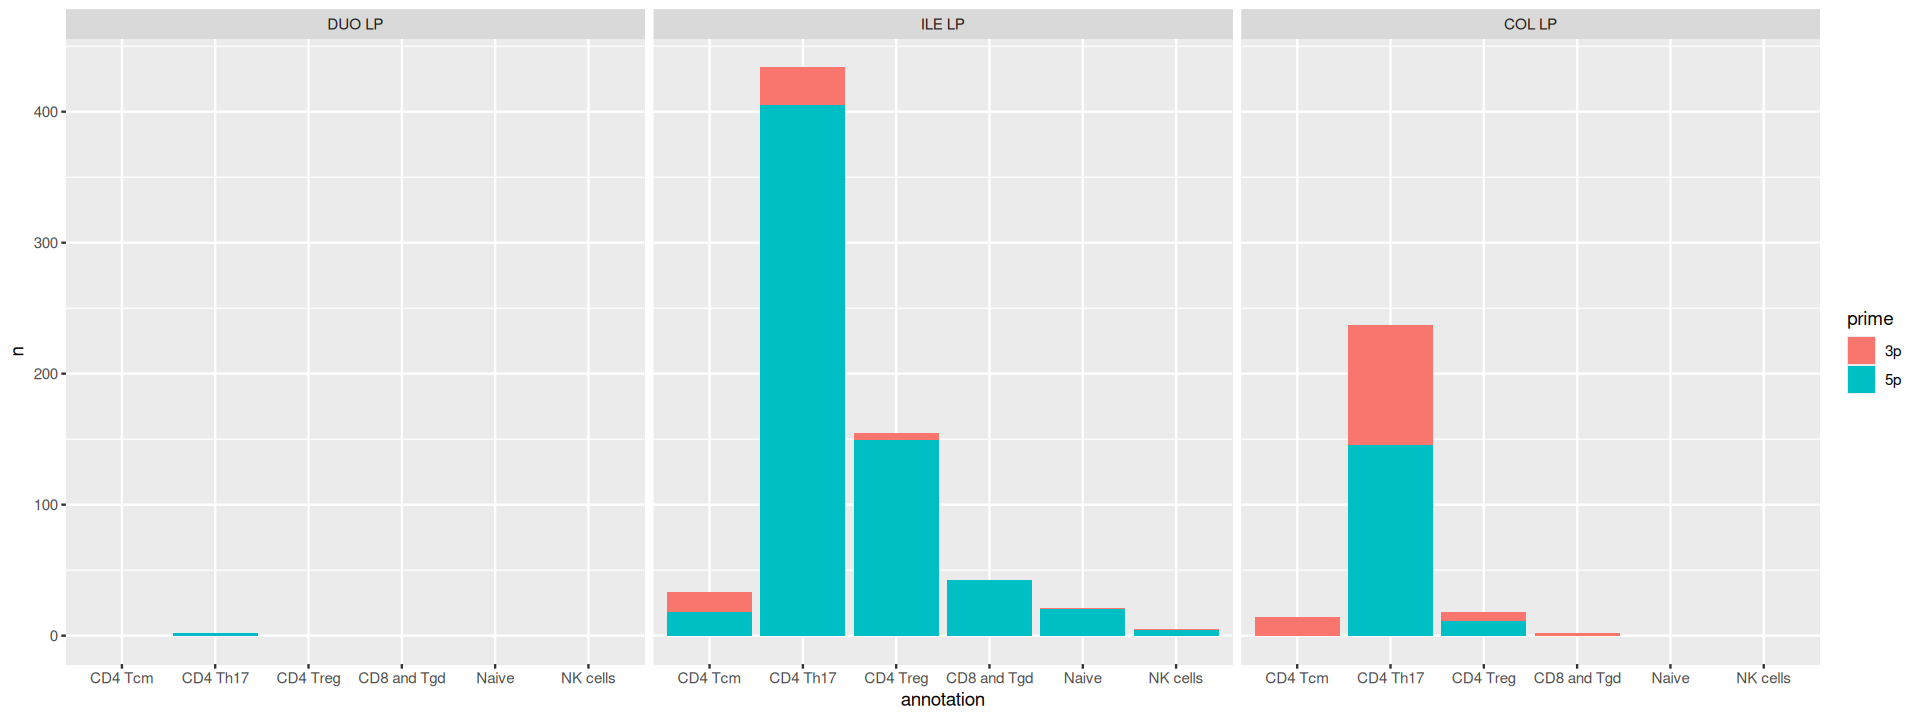

In [334]:
all_limma  %>% dplyr::filter(adj.P.Val < 0.05)  %>% 
dplyr::filter(tissue != "EPI")  %>% 
group_by(prime, annotation, test, tissue)  %>% 
tally()   %>% 
ggplot(aes(x=annotation, y=n, fill = prime)) + 
  geom_bar(stat = "identity") +
facet_wrap(~factor(tissue, levels = c("DUO LP","ILE LP","COL LP")), ncol = 3)

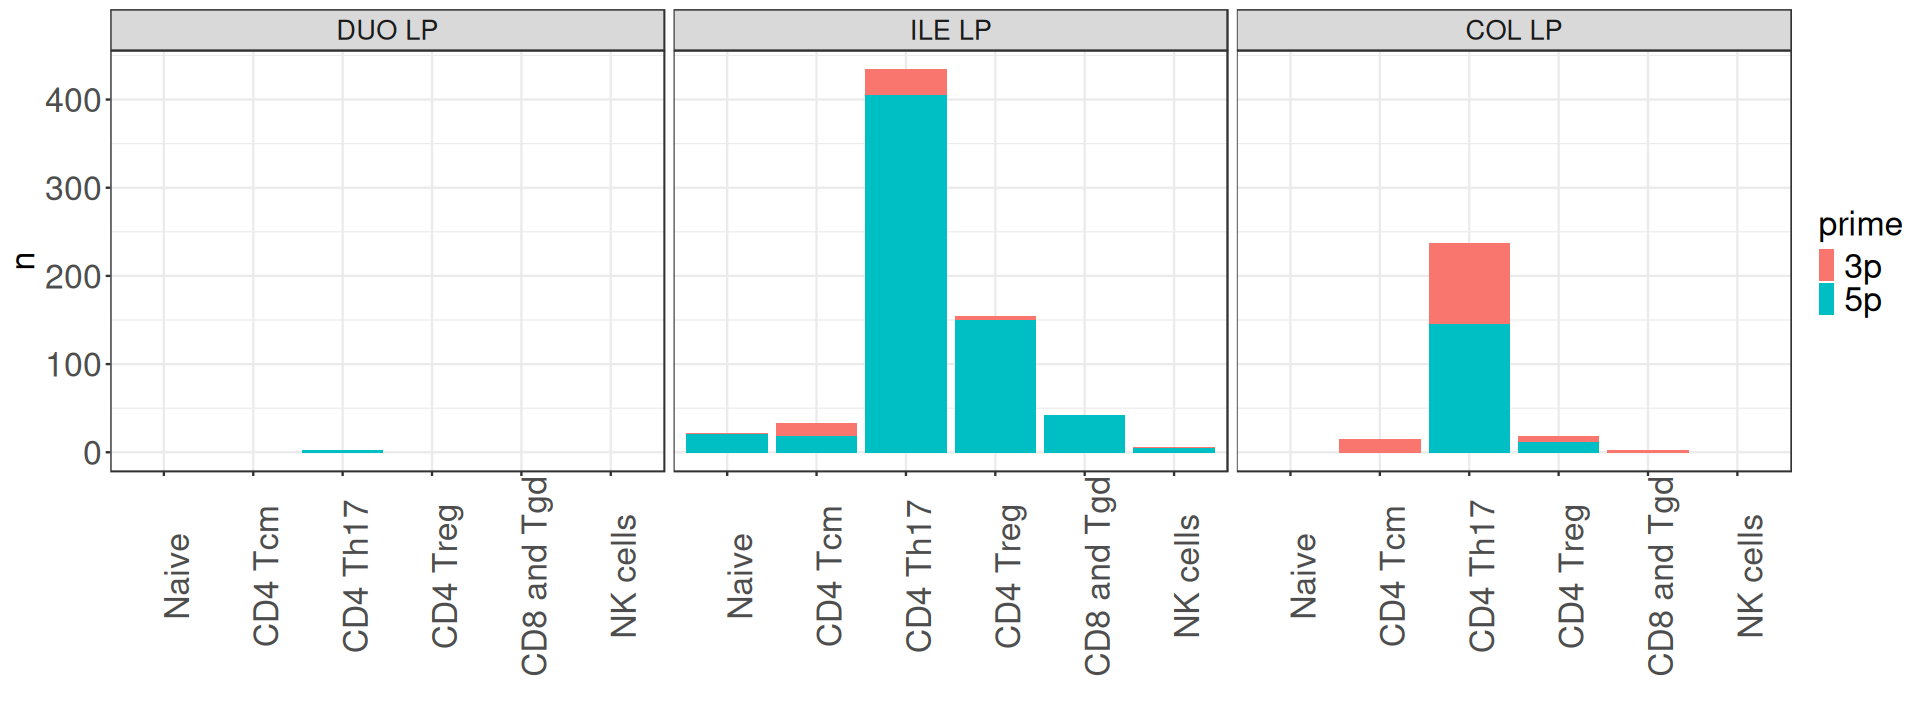

In [335]:
all_limma  %>% dplyr::filter(adj.P.Val < 0.05)  %>% 
dplyr::filter(tissue != "EPI")  %>% 
group_by(prime, annotation, test, tissue)  %>% 
tally() %>% 
ggplot(aes(x=factor(annotation, levels = c("Naive","CD4 Tcm", "CD4 Th17",
                                           "CD4 Treg","CD8 and Tgd","NK cells")), 
                    y=n, fill = prime)) + 
facet_wrap(~factor(tissue, levels = c("DUO LP","ILE LP","COL LP")), ncol = 3)  +
  geom_bar(stat = "identity") +

theme_bw() +
theme(axis.text.x = element_text(angle = 90)) +
ggtheme() + xlab("")

ggsave("figures/atlas/deg_count_limma_response.svg", width = 12, height = 6)

# Cell-level 5p

Prepare genes that we will be testing. We will filter out unannotated genes, mitochondrial and ribosomal genes and long non-coding RNAs.

In [355]:
genes  <- rownames(gut_allt_5p@assays$RNA)

genes_filt_5p  <- genes[!(grepl(genes, pattern = "^MT")|
                            grepl(genes, pattern = "\\.")|
                            grepl(genes, pattern = "LINC")|
                            grepl(genes, pattern = "^MIR")|
                            grepl(genes, pattern = "^MT")|
                            grepl(genes, pattern = "HNRNP")|
                            grepl(genes, pattern = "^RP[LS]")|
                            grepl(genes, pattern = "\\-")|
                            grepl(genes, pattern = "TTTY")|
                            grepl(genes, pattern = "ORF")|
                            grepl(genes, pattern = "orf"))
                            ]


In [356]:
gut_allt_5p$timepoint  %>% table

.
     R     R2     T0 
 66727   2311 519025 

We will only use T0 samples.

In [141]:
gut_allt_5p_t0  <- subset(gut_allt_5p, timepoint == "T0")

In [426]:
rm(gut_allt_5p)
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,17193753,918.3,45592352,2434.9,111309448,5944.6
Vcells,12299132150,93835.0,20925788241,159651.1,15947973658,121673.4


Create a category for IBD or nonIBD.

In [142]:
gut_allt_5p_t0$diagnosis2  <- ifelse(gut_allt_5p_t0$diagnosis %in% c("UC","CD"),"IBD","NonIBD")

In [143]:
gut_allt_5p_t0$diagnosis2  %>% table

.
   IBD NonIBD 
305070 213955 

In [144]:
gut_allt_5p_t0$annotations_coarse  %>% table

.
   CD4 Th17     CD4 Tcm CD8 and Tgd       Naive    CD4 Treg    NK cells 
     142985       71050      171208       63106       47352       23324 

In [145]:
gut_allt_5p_t0$layer  %>% table

.
   EPI     LP 
 65184 453841 

As there are very few epithelial samples, sll epithelial fractions will be tested together.

In [146]:
gut_allt_5p_t0$tissue_layer  <- ifelse(gut_allt_5p_t0$layer == "EPI", "EPI", paste(gut_allt_5p_t0$tissue, "LP"))

In [147]:
gut_allt_5p_t0$tissue_layer  %>% table

.
COL LP DUO LP    EPI ILE LP 
155002  87958  65184 210881 

Prepare the parallel jobs to be tested.

In [148]:
Idents(gut_allt_5p_t0) <- gut_allt_5p_t0$diagnosis2

annots <- levels(factor(gut_allt_5p_t0$annotations_coarse))
tissues <- c("COL LP", "ILE LP", "DUO LP", "EPI")

jobs <- expand.grid(
  annot = annots,
  tissue = tissues,
  stringsAsFactors = FALSE
)

In [149]:
out_dir <- "tables/deg_cell_level_5p_t0_tissue"

Create output folders.

In [150]:
for (tissue in tissues) {
  dir.create(
    file.path(out_dir, tissue),
    recursive = TRUE,
    showWarnings = FALSE
  )
}

plan(sequential)
options(future.globals.maxSize = 64 * 1024^3)
plan(multisession, workers = 3)

Run parallel jobs.

In [ ]:
future_walk(
  seq_len(nrow(jobs)),
  function(j) {
    future::plan(future::sequential)

    annot_use <- jobs$annot[j]
    tissue_use <- jobs$tissue[j]

    cells_use <- rownames(gut_allt_5p_t0[[]])[
      which(
        gut_allt_5p_t0$annotations_coarse == annot_use &
        gut_allt_5p_t0$tissue_layer == tissue_use
      )
    ]

    # Skip combinations without cells
    if (length(cells_use) == 0L) {
      message("Skipping ", annot_use, " / ", tissue_use, ": no cells")
      return(invisible(NULL))
    }

    sub <- subset(gut_allt_5p_t0, cells = cells_use)

    # FindMarkers requires at least 3 cells in each group by default
    group_counts <- table(Idents(sub))
    if (any(group_counts[c("IBD", "NonIBD")] < 3, na.rm = TRUE) ||
        !all(c("IBD", "NonIBD") %in% names(group_counts))) {
      message("Skipping ", annot_use, " / ", tissue_use,
              ": fewer than 3 cells in one diagnosis group")
      return(invisible(NULL))
    }

    genes_use <- intersect(
      genes_filt_5p,
      rownames(GetAssayData(sub, assay = "RNA", slot = "data"))
    )

    if (length(genes_use) == 0L) {
      stop("No requested genes found for ", annot_use, " / ", tissue_use)
    }

    mrk <- Seurat::FindMarkers(
      sub,
      assay = "RNA",
      slot = "data",
      ident.1 = "IBD",
      ident.2 = "NonIBD",
      features = genes_use
    )
      
      mrk$gene  <- rownames(mrk)

    write.csv(
      mrk,
      file = file.path(out_dir, tissue_use, paste0(annot_use, ".csv"))
    )
  },
  .options = furrr_options(
    packages = "Seurat",
    seed = 123
  )
)

plan(sequential)

In [ ]:
out_dir

Load the results.

In [ ]:

out_dir <- "tables_deg/deg_cell_level_5p_t0_tissue/"
tissue_layers <- c("COL LP", "ILE LP", "DUO LP", "EPI")

files <- unlist(lapply(tissue_layers, function(x) {
  list.files(
    file.path(out_dir, x),
    pattern = "\\.csv$",
    full.names = TRUE
  )
}), use.names = FALSE)

if (length(files) == 0L) {
  stop("No marker CSV files found.")
}

markers_all <- map_dfr(files, function(file) {
  mrk <- read.csv(
    file,
    row.names = 1,
    check.names = FALSE,
    stringsAsFactors = FALSE
  )

  tissue_layer <- basename(dirname(file))
  parts <- strsplit(tissue_layer, " ", fixed = TRUE)[[1]]

  if (!"gene" %in% names(mrk)) {
    mrk$gene <- rownames(mrk)
  }

  if (!"tissue" %in% names(mrk)) {
    # EPI folder does not specify an anatomical tissue
    mrk$tissue <- if (length(parts) > 1L) parts[1] else NA_character_
  }

  if (!"layer" %in% names(mrk)) {
    mrk$layer <- tail(parts, 1)
  }

  if (!"annotation" %in% names(mrk)) {
    mrk$annotation <- tools::file_path_sans_ext(basename(file))
  }

  rownames(mrk) <- NULL
  mrk
})

In [ ]:
markers_all

# Simulation 5p count of participants

In [359]:
aggexp_5p  <- readRDS("data/261004_aggexp_5p.rds")

In [360]:
aggexp_5p_ile_lp  <- subset(aggexp_5p, layer == "LP" &  tissue == "ILE")

In [361]:
aggexp_5p_ile_lp@meta.data  %>% group_by(participant_id, diagnosis2)  %>% tally()  %>% 
ungroup  %>% 
group_by(diagnosis2)  %>% 
tally()

diagnosis2,n
<chr>,<int>
IBD,43
NonIBD,27


In [362]:
ibd  <- aggexp_5p_ile_lp@meta.data  %>% dplyr::filter(diagnosis2 == "IBD")  %>% 
pull(participant_id)  %>% unique
nonibd  <- aggexp_5p_ile_lp@meta.data  %>% dplyr::filter(diagnosis2 != "IBD")  %>% 
pull(participant_id)  %>% unique

In [363]:
counts_ibd  <- c()
counts_nonibd  <- c()

for(i in 1:10){
    counts_ibd[i]  <- round(43/10*i)
    counts_nonibd[i]  <- round(27/10*i)
 print(sum(counts_ibd[i], counts_nonibd[i]))
}

[1] 7
[1] 14
[1] 21
[1] 28
[1] 36
[1] 42
[1] 49
[1] 56
[1] 63
[1] 70


In [364]:
# ---- Configuration ----
n_sim <- 10L
n_sizes <- length(counts_ibd)
workers <- 6L

In [365]:
# A separate directory for this run
out_dir <- file.path(
  "tables",
  paste0("deg_simulation_", format(Sys.time(), "%Y%m%d_%H%M%S"))
)
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

stopifnot(
  n_sizes == length(counts_nonibd),
  n_sizes > 0L
)

In [366]:
# ---- Prepare participant pools ----
ibd <- unique(as.character(ibd))
nonibd <- unique(as.character(nonibd))

stopifnot(
  !anyNA(ibd),
  !anyNA(nonibd),
  length(intersect(ibd, nonibd)) == 0L,
  all(counts_ibd >= 0),
  all(counts_nonibd >= 0),
  all(counts_ibd == floor(counts_ibd)),
  all(counts_nonibd == floor(counts_nonibd)),
  all(counts_ibd <= length(ibd)),
  all(counts_nonibd <= length(nonibd))
)

In [367]:
# ---- Extract counts and metadata once ----
# Assumes one joined RNA counts layer, as in your original code.
counts <- round(
  SeuratObject::LayerData(
    aggexp_5p_ile_lp,
    assay = "RNA",
    layer = "counts"
  )
)

meta <- aggexp_5p_ile_lp[[]]
meta <- meta[colnames(counts), , drop = FALSE]

stopifnot(
  identical(rownames(meta), colnames(counts)),
  all(c(ibd, nonibd) %in% as.character(meta$participant_id))
)

genes_use <- intersect(genes, rownames(counts))


In [368]:
# ---- Generate ALL selections before running any DE ----
selections <- vector("list", n_sim * n_sizes)
selected_ids <- vector("list", n_sim * n_sizes)
z <- 0L

for (m in seq_len(n_sim)) {
  set.seed(m)

  for (i in seq_len(n_sizes)) {
    z <- z + 1L

    ids <- sort(c(
      sample(ibd, size = counts_ibd[i], replace = FALSE),
      sample(nonibd, size = counts_nonibd[i], replace = FALSE)
    ))

    selected_ids[[z]] <- ids

    selections[[z]] <- data.frame(
      simulation = m,
      subset_id = i,
      pt_count = length(ids),
      participant_ids = paste(ids, collapse = ";")
    )
  }
}

selections <- bind_rows(selections)

# Identical participant sets share one DE job.
selections$job_id <- match(
  selections$participant_ids,
  unique(selections$participant_ids)
)

jobs <- selected_ids[!duplicated(selections$participant_ids)]

write.csv(
  selections,
  file.path(out_dir, "participant_selections.csv"),
  row.names = FALSE
)

selection_check <- selections %>%
  group_by(subset_id, pt_count) %>%
  summarise(
    distinct_participant_sets = n_distinct(participant_ids),
    .groups = "drop"
  )

print(selection_check)

message(
  nrow(selections), " requested subsets; ",
  length(jobs), " unique DE jobs."
)

# A tibble: 10 × 3
   subset_id pt_count distinct_participant_sets
       <int>    <int>                     <int>
 1         1        7                        10
 2         2       14                        10
 3         3       21                        10
 4         4       28                        10
 5         5       36                        10
 6         6       42                        10
 7         7       49                        10
 8         8       56                        10
 9         9       63                        10
10        10       70                         1


100 requested subsets; 91 unique DE jobs.



In [370]:
deg_ile_lp  <- read_csv("tables/261004_aggexp_5p_deseq_deg_all_tissue.csv")

New names:
• `` -> `...1`
Rows: 993773 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): ...1, test, gene, annotation, tissue
dbl (5): p_val, avg_log2FC, pct.1, pct.2, p_val_adj

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [371]:
deg_ile_lp

...1,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,test,gene,annotation,tissue
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
PARP14,3.026721e-07,0.9612972,1.000,1.000,0.003900535,UC_vs_FGID,PARP14,NK cells,ILE LP
MICU3,4.553543e-06,1.2757261,0.933,0.545,0.058681514,UC_vs_FGID,MICU3,NK cells,ILE LP
TOX2,8.454165e-06,-1.3003990,0.867,1.000,0.108948821,UC_vs_FGID,TOX2,NK cells,ILE LP
SUZ12,1.528274e-05,1.0667596,1.000,1.000,0.196948686,UC_vs_FGID,SUZ12,NK cells,ILE LP
KPNA4,4.380270e-05,0.6681299,1.000,1.000,0.564485430,UC_vs_FGID,KPNA4,NK cells,ILE LP
SET,5.266105e-05,0.4917125,1.000,1.000,0.678642912,UC_vs_FGID,SET,NK cells,ILE LP
VPS13C,6.705279e-05,0.5756202,1.000,1.000,0.864109248,UC_vs_FGID,VPS13C,NK cells,ILE LP
ST8SIA6,1.037320e-04,0.9975282,1.000,0.818,1.000000000,UC_vs_FGID,ST8SIA6,NK cells,ILE LP
SETX,1.313158e-04,0.7650653,1.000,1.000,1.000000000,UC_vs_FGID,SETX,NK cells,ILE LP


In [372]:
deg_ile_lp$`...1`  <- NULL
deg_ile_lp  <- deg_ile_lp  %>% dplyr::filter(tissue == "ILE LP" & test == "IBD_vs_NonIBD")

In [373]:
# ---- Analyze one participant set ----
run_job <- function(job_id) {

  ids <- jobs[[job_id]]

  selected <- as.character(meta$participant_id) %in% ids
  job_meta <- meta[selected, , drop = FALSE]

  annotations <- sort(unique(
    as.character(job_meta$annotations_coarse)
  ))
  annotations <- annotations[!is.na(annotations)]

  results <- list()

  for (k in annotations) {

    use <- !is.na(job_meta$annotations_coarse) &
      as.character(job_meta$annotations_coarse) == k

    md <- job_meta[use, , drop = FALSE]

    n_ibd <- sum(as.character(md$diagnosis2) == "IBD", na.rm = TRUE)
    n_nonibd <- sum(
      as.character(md$diagnosis2) == "NonIBD",
      na.rm = TRUE
    )

    if (n_ibd < 3L || n_nonibd < 3L) {
      next
    }

    # Explicit column selection avoids ambiguity in subset evaluation.
    x <- counts[, rownames(md), drop = FALSE]

    obj <- CreateSeuratObject(
      counts = x,
      meta.data = md,
      min.cells = 5
    )

    features_use <- intersect(genes_use, rownames(obj))

    if (length(features_use) == 0L) {
      next
    }

    # Retained to preserve the fold-change calculation in your workflow.
    obj <- NormalizeData(obj, verbose = FALSE)
    Idents(obj) <- obj$diagnosis2

    deg <- FindMarkers(
      obj,
      assay = "RNA",
      ident.1 = "IBD",
      ident.2 = "NonIBD",
      features = features_use,
      slot = "counts",
      test.use = "DESeq2",
      min.pct = 0.2,
      min.cells.feature = 3,
      verbose = FALSE
    )

    if (nrow(deg) == 0L) {
      next
    }

    deg$gene <- rownames(deg)
    deg$test <- "IBD_vs_NonIBD"
    deg$annotation <- k
    deg$pt_count <- length(ids)

    results[[length(results) + 1L]] <- deg
  }

  result <- bind_rows(results)

  # Checkpoint every completed job.
  saveRDS(
    result,
    file.path(out_dir, sprintf("job_%03d.rds", job_id))
  )

  result
}

# ---- Run in parallel ----
# Increase only if future reports that exported objects exceed its limit.
options(future.globals.maxSize = 4 * 1024^3)

plan(multisession, workers = workers)

# Seurat's own future calls, if any, run sequentially inside these workers.
job_results <- tryCatch(
  future_map(
    seq_along(jobs),
    run_job,
    .options = furrr_options(
      seed = 123,
      scheduling = 1
    )
  ),
  finally = plan(sequential)
)

if (all(vapply(job_results, nrow, integer(1)) == 0L)) {
  stop(
    "No DE results were generated. Check group sizes and gene filters. ",
    "Participant selections and job checkpoints are in: ", out_dir
  )
}

# ---- Assemble one CSV per simulation ----
baseline <- deg_ile_lp %>%
  filter(test == "IBD_vs_NonIBD")

baseline$tissue <- NULL
baseline$pt_count <- length(unique(
  na.omit(as.character(meta$participant_id))
))
baseline$subset_id <- 0L

for (m in seq_len(n_sim)) {

  sel <- selections[selections$simulation == m, , drop = FALSE]

  pieces <- lapply(seq_len(nrow(sel)), function(j) {
    deg <- job_results[[sel$job_id[j]]]

    if (nrow(deg) == 0L) {
      return(NULL)
    }

    deg$simulation <- m
    deg$subset_id <- sel$subset_id[j]
    deg
  })

  baseline_m <- baseline
  baseline_m$simulation <- rep(m, nrow(baseline_m))

  output <- bind_rows(
    c(list(baseline_m), pieces)
  )

  write.csv(
    output,
    file.path(out_dir, paste0("deg_simulation_", m, ".csv")),
    row.names = FALSE
  )
}

message("Finished. Results saved in: ", out_dir)

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship



mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates



gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode



converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship



mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates



gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode



converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



In [374]:
out_dir

[1] "tables/deg_simulation_20261019_231232"

In [375]:
files <- list.files(path = "tables/deg_simulation_20261019_231232/",
  pattern = "^deg_simulation_[0-9]+\\.csv$",
  full.names = TRUE
)

In [376]:
files

[1] "tables/deg_simulation_20261019_231232//deg_simulation_1.csv" 
 [2] "tables/deg_simulation_20261019_231232//deg_simulation_10.csv"
 [3] "tables/deg_simulation_20261019_231232//deg_simulation_2.csv" 
 [4] "tables/deg_simulation_20261019_231232//deg_simulation_3.csv" 
 [5] "tables/deg_simulation_20261019_231232//deg_simulation_4.csv" 
 [6] "tables/deg_simulation_20261019_231232//deg_simulation_5.csv" 
 [7] "tables/deg_simulation_20261019_231232//deg_simulation_6.csv" 
 [8] "tables/deg_simulation_20261019_231232//deg_simulation_7.csv" 
 [9] "tables/deg_simulation_20261019_231232//deg_simulation_8.csv" 
[10] "tables/deg_simulation_20261019_231232//deg_simulation_9.csv"

In [377]:
for(i in 1:10){
    deg  <- read_csv(files[i])
    
    if(i == 1){
        deg_all_all  <- deg 
    } else {
        deg_all_all  <- rbind(deg_all_all, deg)
    }
}

Rows: 801484 Columns: 11
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): test, gene, annotation
dbl (8): p_val, avg_log2FC, pct.1, pct.2, p_val_adj, pt_count, subset_id, si...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 810597 Columns: 11
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): test, gene, annotation
dbl (8): p_val, avg_log2FC, pct.1, pct.2, p_val_adj, pt_count, subset_id, si...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 809977 Columns: 11
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): test, gene, annotation
dbl (8): p_val, avg_log2FC, pct.1, pct.2, p_val_adj, pt_count, subset_i

In [378]:
deg_all_all

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,test,gene,annotation,pt_count,subset_id,simulation
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1.061397e-12,2.1319546,0.732,0.148,1.516524e-08,IBD_vs_NonIBD,LCN2,CD4 Tcm,70,0,1
3.724314e-10,1.8900822,0.902,0.852,5.321300e-06,IBD_vs_NonIBD,PIGR,CD4 Tcm,70,0,1
1.328512e-07,0.3277693,1.000,1.000,1.898177e-03,IBD_vs_NonIBD,MBD4,CD4 Tcm,70,0,1
3.089433e-07,1.1483086,0.707,0.481,4.414181e-03,IBD_vs_NonIBD,RARRES1,CD4 Tcm,70,0,1
3.989993e-07,0.7964147,0.976,0.889,5.700902e-03,IBD_vs_NonIBD,GLUL,CD4 Tcm,70,0,1
4.756444e-07,1.5867874,0.707,0.370,6.796007e-03,IBD_vs_NonIBD,ITLN1,CD4 Tcm,70,0,1
7.212937e-07,1.1821951,1.000,0.889,1.030584e-02,IBD_vs_NonIBD,PDE7B,CD4 Tcm,70,0,1
8.809641e-07,0.8400142,1.000,1.000,1.258722e-02,IBD_vs_NonIBD,PDE3B,CD4 Tcm,70,0,1
1.054507e-06,1.0452794,0.683,0.370,1.506680e-02,IBD_vs_NonIBD,ASS1,CD4 Tcm,70,0,1


`geom_smooth()` using formula = 'y ~ x'


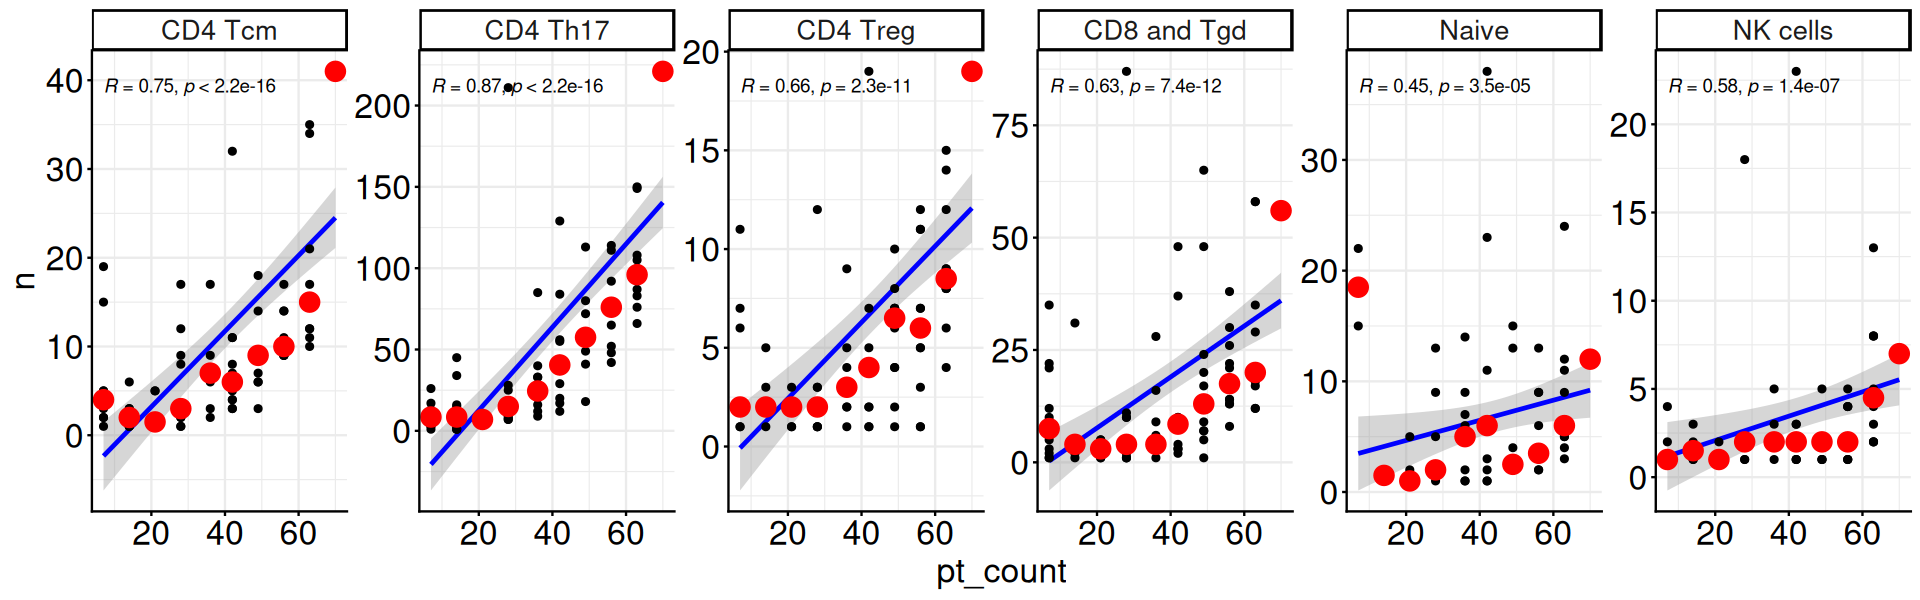

In [395]:
deg_all_all  %>%  
dplyr::filter(p_val_adj < 0.05) %>% 
group_by(annotation, pt_count, simulation)  %>% tally()  %>% 
ggplot(aes(x = pt_count, y = n)) +
ggpubr::stat_cor(method = "spearman") +
  geom_smooth(
    method = "lm",
    color = "blue",
    linewidth = 1) +
geom_point() +
stat_summary(geom = "point", size = 5, fun = median, color = "red") +
facet_wrap(~annotation, scales = "free", ncol = 6) +
theme_classic() +
  theme(
    panel.grid.major = element_line(color = "grey92", linewidth = 0.5),
    panel.grid.minor = element_line(color = "grey92", linewidth = 0.25)
  ) +
ggtheme() 
  



In [396]:
ggsave("figures/deg_simulation_signif.svg", width = 38, height = 10, units = "cm")

`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


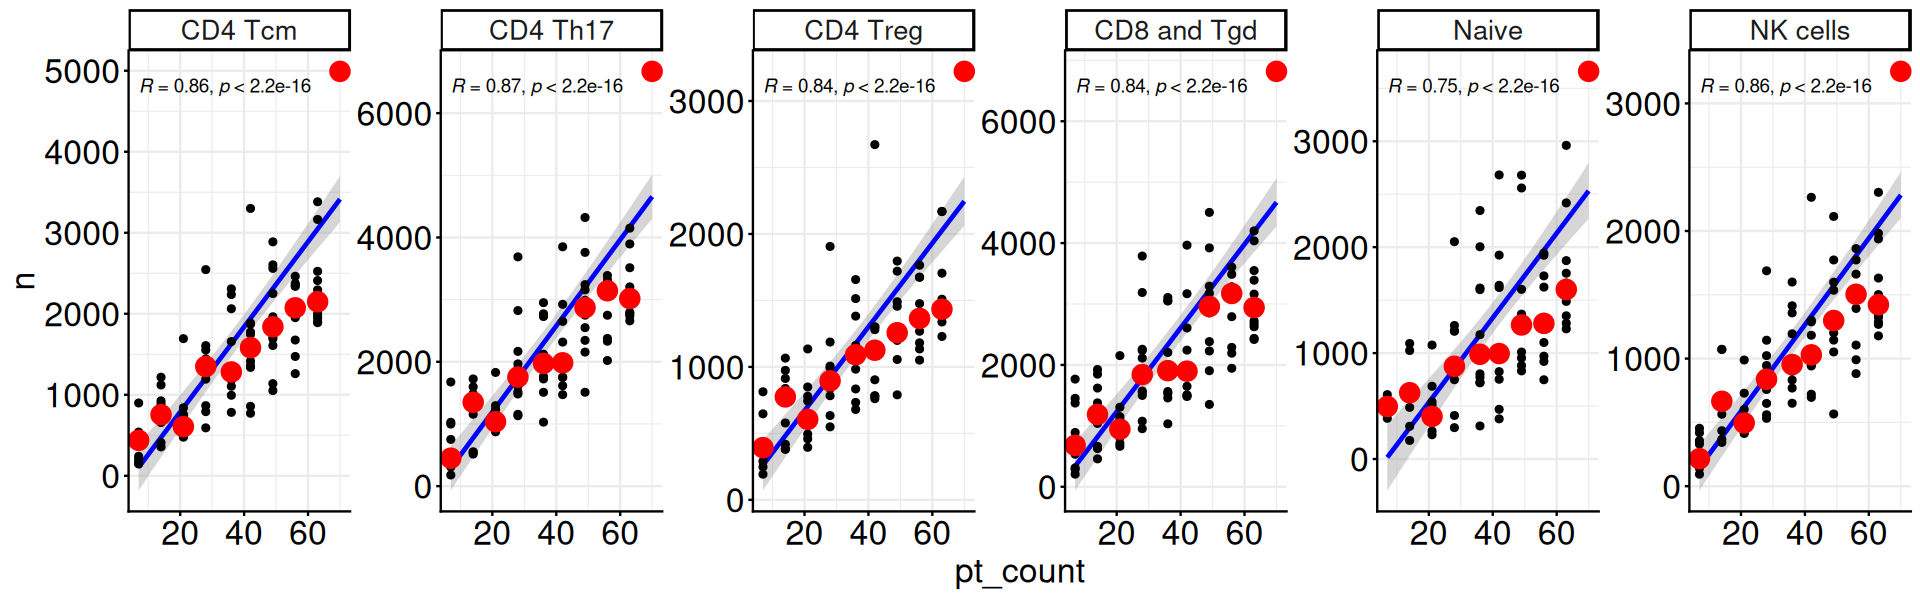

In [397]:
deg_all_all  %>%  
dplyr::filter(p_val < 0.05) %>% 
group_by(annotation, pt_count, simulation)  %>% tally()  %>% 
ggplot(aes(x = pt_count, y = n)) +
ggpubr::stat_cor(method = "spearman") +
  geom_smooth(
    method = "lm",
    color = "blue",
    linewidth = 1) +
geom_point() +
stat_summary(geom = "point", size = 5, fun = median, color = "red") +
facet_wrap(~annotation, scales = "free", ncol = 6) +
theme_classic() +
  theme(
    panel.grid.major = element_line(color = "grey92", linewidth = 0.5),
    panel.grid.minor = element_line(color = "grey92", linewidth = 0.25)
  ) +
ggtheme() 
  

In [399]:
ggsave("figures/deg_simulation_all.svg",  width = 39, height = 10, units = "cm")

`geom_smooth()` using formula = 'y ~ x'


In [400]:
ls()

[1] "aggexp_3p"             "aggexp_5p"             "aggexp_5p_ile_lp"     
 [4] "annots"                "baseline"              "baseline_m"           
 [7] "colour_max"            "comparisons"           "counts"               
[10] "counts_all"            "counts_ibd"            "counts_nonibd"        
[13] "deg"                   "deg_all_all"           "deg_all_tissues_deseq"
[16] "deg_counts"            "deg_ile_lp"            "ds_sub"               
[19] "files"                 "genes"                 "genes_filt_3p"        
[22] "genes_filt_5p"         "genes_use"             "ggtheme"              
[25] "gut_allt_3p"           "gut_allt_5p"           "i"                    
[28] "ibd"                   "ids"                   "job_results"          
[31] "jobs"                  "keep_samples"          "loaded"               
[34] "m"                     "md"                    "md_to_join"           
[37] "meta"                  "metadata_all"          "n_sim"                
[40] "n_sizes"               "nonibd"                "out_dir"              
[43] "output"                "p"                     "pieces"               
[46] "plot_3p"               "plot_df"               "plot_df2"             
[49] "pt_3p"                 "result_dirs"           "run_job"              
[52] "sample_counts"         "sample_counts_total"   "sample_counts_wide"   
[55] "sel"                   "selected_ids"          "selection_check"      
[58] "selections"            "test_name"             "test_status"          
[61] "test_status_wide"      "tissue_layers"         "tl"                   
[64] "workers"               "z"

# GSEA DEG

In [69]:
deg_3p  <- read_csv("../241201_VN_PREDICT2/tables/250519_aggexp_3p_deseq_deg_all_tissue4_T0.csv")
deg_5p  <- read_csv("../241201_VN_PREDICT2/tables/250519_aggexp_5p_deseq_deg_all_tissue4_T0.csv")

New names:
• `` -> `...1`
Rows: 604391 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): ...1, test, gene, annotation, tissue
dbl (5): p_val, avg_log2FC, pct.1, pct.2, p_val_adj

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
New names:
• `` -> `...1`
Rows: 1418255 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): ...1, test, gene, annotation, tissue
dbl (5): p_val, avg_log2FC, pct.1, pct.2, p_val_adj

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [70]:
deg_3p$`...1`  <- NULL
deg_5p$`...1`  <- NULL

In [71]:
deg_3p$tissue  %>% table
deg_5p$tissue  %>% table

deg_3p$annotation  %>% table
deg_5p$annotation  %>% table

deg_3p$test  %>% table
deg_5p$test  %>% table

.
COL LP DUO LP    EPI ILE LP 
153403 126438 165759 158791 

.
COL EPI  COL LP DUO EPI  DUO LP     EPI  ILE LP 
 126182  299948  175521  265004  245483  306117 

.
CD4 CD8 Naive       CD4 Tcm      CD4 Th17      CD4 Treg    CD8 Memory 
        71068         89656        108718         96596        110217 
     NK cells 
       128136 

.
   CD4 Tcm   CD4 Th17   CD4 Treg CD8 Memory      Naive   NK cells 
    225322     239839     218097     262721     204570     267706 

.
   CD_vs_FGID IBD_vs_NonIBD    UC_vs_FGID 
       263500        300644         40247 

.
   CD_vs_FGID     CD_vs_HEA IBD_vs_NonIBD    UC_vs_FGID     UC_vs_HEA 
       379906        268905        434139         59927        275378 

In [72]:
deg_3p  <- deg_3p  %>% mutate(annotation = gsub(annotation, pattern = "CD4 CD8 Naive", replacement = "Naive"))
deg_5p  <- deg_5p  %>% dplyr::filter(tissue %in% c("COL LP", "DUO LP", "EPI", "ILE LP"))

In [73]:
deg_3p$tissue  %>% table
deg_5p$tissue  %>% table

deg_3p$annotation  %>% table
deg_5p$annotation  %>% table

deg_3p$test  %>% table
deg_5p$test  %>% table

.
COL LP DUO LP    EPI ILE LP 
153403 126438 165759 158791 

.
COL LP DUO LP    EPI ILE LP 
299948 265004 245483 306117 

.
   CD4 Tcm   CD4 Th17   CD4 Treg CD8 Memory      Naive   NK cells 
     89656     108718      96596     110217      71068     128136 

.
   CD4 Tcm   CD4 Th17   CD4 Treg CD8 Memory      Naive   NK cells 
    176903     192592     173910     203214     163065     206868 

.
   CD_vs_FGID IBD_vs_NonIBD    UC_vs_FGID 
       263500        300644         40247 

.
   CD_vs_FGID     CD_vs_HEA IBD_vs_NonIBD    UC_vs_FGID     UC_vs_HEA 
       265292        268905        265446         41531        275378 

In [74]:
# Install once if needed:
# install.packages(c("BiocManager", "msigdbr", "dplyr", "ggplot2"))
# BiocManager::install("fgsea")

library(dplyr)
library(ggplot2)
library(msigdbr)
library(fgsea)

# 1. Select the requested comparison
select_degs <- function(df) {
  out <- df %>%
    filter(
      test == "IBD_vs_NonIBD",
      annotation == "CD4 Th17",
      tissue == "ILE LP"
    ) %>%
    transmute(
      gene = as.character(gene),
      avg_log2FC = avg_log2FC
    ) %>%
    filter(
      !is.na(gene),
      nzchar(gene),
      is.finite(avg_log2FC)
    )

  if (nrow(out) == 0L)
    stop("No usable genes found for the selected comparison.")

  if (anyDuplicated(out$gene))
    stop("Duplicate gene names in this subset; resolve them before GSEA.")

  out
}

de_3p <- select_degs(deg_3p)
de_5p <- select_degs(deg_5p)

# 2. Restrict both rankings to the same genes
common_genes <- intersect(de_3p$gene, de_5p$gene)

message(
  "Genes: 3p = ", nrow(de_3p),
  "; 5p = ", nrow(de_5p),
  "; shared = ", length(common_genes)
)

if (length(common_genes) < 15L)
  stop("Too few shared genes. Check the subsets and gene identifiers.")

make_ranks <- function(df) {
  df <- df %>%
    filter(gene %in% common_genes) %>%
    arrange(desc(avg_log2FC), gene)

  setNames(df$avg_log2FC, df$gene)
}

ranks_3p <- make_ranks(de_3p)
ranks_5p <- make_ranks(de_5p)

Genes: 3p = 12802; 5p = 12399; shared = 11882



In [75]:
# 3. Human Hallmark gene sets
hallmark <- msigdbr(
  species = "Homo sapiens",
  category = "H"
)

pathways <- split(hallmark$gene_symbol, hallmark$gs_name)
pathways <- lapply(pathways, unique)

if (length(intersect(common_genes, unlist(pathways))) < 15L)
  stop("Too few genes match Hallmark sets. Check species/gene identifiers.")

In [76]:
# 4. Run GSEA separately for each dataset
run_gsea <- function(ranks, seed) {
  set.seed(seed)

  fgseaMultilevel(
    pathways = pathways,
    stats = ranks,
    minSize = 15,
    maxSize = 500,
    eps = 0,
    nproc = 1
  ) %>%
    as.data.frame() %>%
    arrange(padj)
}

gsea_3p <- run_gsea(ranks_3p, seed = 123)
gsea_5p <- run_gsea(ranks_5p, seed = 456)

# 5. Compare pathway enrichment
gsea_compare <- inner_join(
  gsea_3p %>%
    select(pathway, NES_3p = NES, FDR_3p = padj),
  gsea_5p %>%
    select(pathway, NES_5p = NES, FDR_5p = padj),
  by = "pathway"
) %>%
  filter(is.finite(NES_3p), is.finite(NES_5p)) %>%
  mutate(
    same_direction = sign(NES_3p) == sign(NES_5p),
    significance = case_when(
      FDR_3p < 0.05 & FDR_5p < 0.05 ~ "Both",
      FDR_3p < 0.05                ~ "3p only",
      FDR_5p < 0.05                ~ "5p only",
      TRUE                        ~ "Neither"
    )
  ) %>%
  arrange(desc(same_direction), pmax(FDR_3p, FDR_5p))

  |======================================================================| 100%

  |======================================================================| 100%



In [77]:
library(dplyr)
library(fgsea)

# 1. Select the same comparison in both datasets
de_5p <- deg_5p %>%
  filter(
    test == "IBD_vs_NonIBD",
    annotation == "CD4 Th17",
    tissue == "ILE LP"
  )

de_3p <- deg_3p %>%
  filter(
    test == "IBD_vs_NonIBD",
    annotation == "CD4 Th17",
    tissue == "ILE LP"
  )

# 2. Custom gene set: significantly upregulated genes in 5p
genes_up_5p <- de_5p %>%
  filter(
    p_val_adj < 0.05,
    avg_log2FC > 0,
    !is.na(gene),
    gene != ""
  ) %>%
  pull(gene) %>%
  as.character() %>%
  unique()

# 3. Rank ALL available 3p genes by logFC
# Do not filter this dataset by significance!
de_3p_rank <- de_3p %>%
  transmute(
    gene = as.character(gene),
    avg_log2FC = avg_log2FC
  ) %>%
  filter(
    !is.na(gene),
    gene != "",
    is.finite(avg_log2FC)
  ) %>%
  arrange(desc(avg_log2FC), gene)

if (anyDuplicated(de_3p_rank$gene)) {
  stop("Duplicate gene names in the 3p subset; resolve before GSEA.")
}

ranks_3p <- setNames(de_3p_rank$avg_log2FC, de_3p_rank$gene)

# Check how many 5p upregulated genes are present in 3p
genes_up_5p_in_3p <- intersect(genes_up_5p, names(ranks_3p))

message(
  "Upregulated genes in 5p: ", length(genes_up_5p),
  "; present in 3p ranking: ", length(genes_up_5p_in_3p)
)

if (length(genes_up_5p_in_3p) < 15L) {
  stop("Fewer than 15 matching genes: too few for the chosen minSize.")
}

# 4. Test enrichment of the 5p signature in the 3p ranking
pathways <- list(Upregulated_in_5p = genes_up_5p_in_3p)

set.seed(123)

gsea_result <- fgseaMultilevel(
  pathways = pathways,
  stats = ranks_3p,
  minSize = 15,
  maxSize = length(ranks_3p),
  eps = 0,
  scoreType = "std",
  nproc = 1
)

Upregulated genes in 5p: 95; present in 3p ranking: 95



  |======================================================================| 100%



In [78]:
gsea_result %>%
  as.data.frame() %>%
  select(pathway, size, ES, NES, pval, padj, leadingEdge)

pathway,size,ES,NES,pval,padj,leadingEdge
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<list>
Upregulated_in_5p,95,0.8650204,3.700872,5.32227e-43,5.32227e-43,"SPINK4, ...."


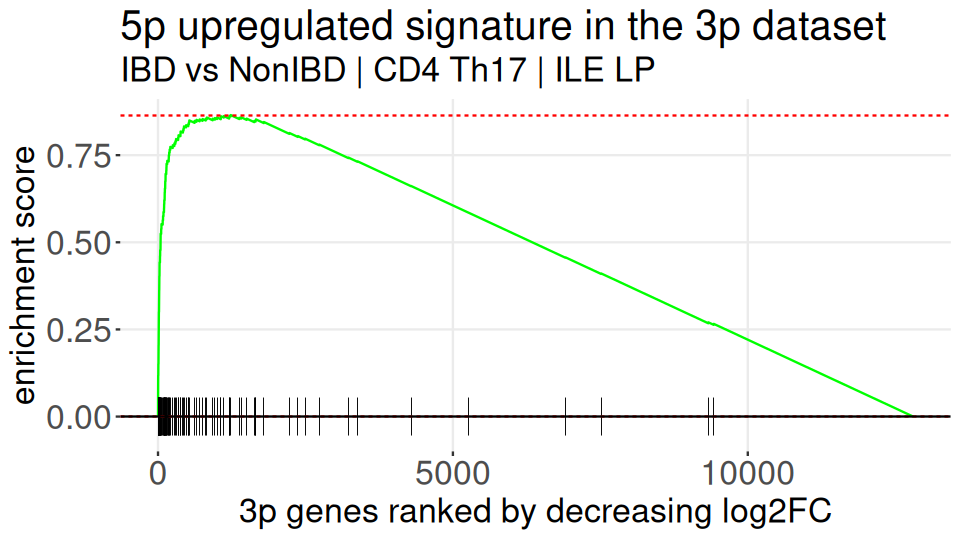

In [79]:
options(repr.plot.width = 8, repr.plot.height = 4.5)
# 5. Plot the enrichment curve
plotEnrichment(
  pathway = genes_up_5p_in_3p,
  stats = ranks_3p
) +
  ggplot2::labs(
    title = "5p upregulated signature in the 3p dataset",
    subtitle = "IBD vs NonIBD | CD4 Th17 | ILE LP",
    x = "3p genes ranked by decreasing log2FC"
  ) +
ggtheme()

In [90]:
p_deg  <- plotEnrichment(
  pathway = genes_up_5p_in_3p,
  stats = ranks_3p
) +
  ggplot2::labs(
    title = "5p upregulated signature in the 3p dataset",
    subtitle = "IBD vs NonIBD | CD4 Th17 | ILE LP",
    x = "3p genes ranked by decreasing log2FC"
  ) +
theme_classic() +
  theme(
    panel.grid.major = element_line(color = "grey92", linewidth = 0.5),
    panel.grid.minor = element_line(color = "grey92", linewidth = 0.25)
  ) +
ggtheme()

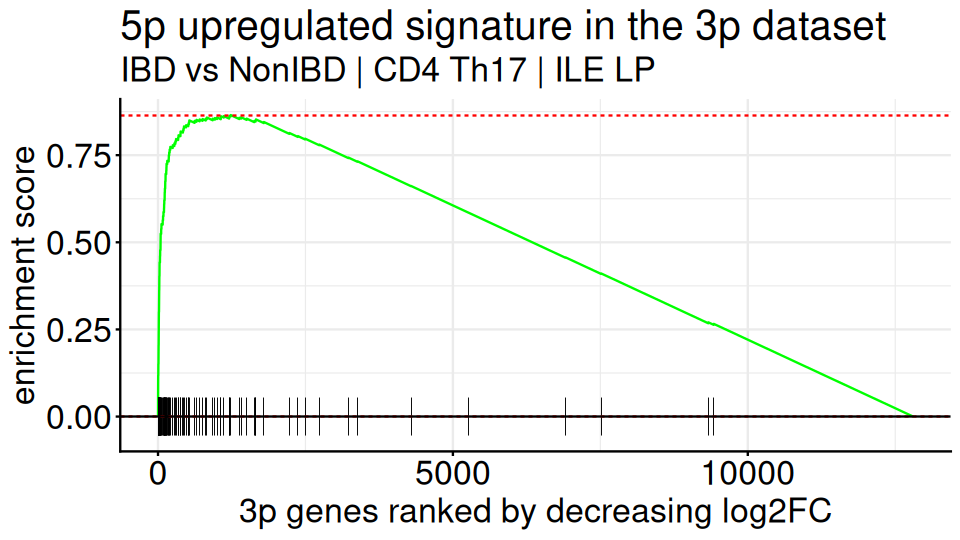

In [91]:
p_deg

In [92]:
ggsave("figures/gsea_5p_3p_th17.svg", width = 12, height = 10, units = "cm")

## Correlation sample count vs DEG count

In [59]:
deg_5p  <- read_csv("../241201_VN_PREDICT2/tables/250519_aggexp_5p_deseq_deg_all_tissue4_T0.csv")

deg_5p$`...1`  <- NULL

deg_5p  <- deg_5p  %>% dplyr::filter(tissue %in% c("COL LP", "DUO LP", "EPI", "ILE LP"))

New names:
• `` -> `...1`
Rows: 1418255 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): ...1, test, gene, annotation, tissue
dbl (5): p_val, avg_log2FC, pct.1, pct.2, p_val_adj

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [60]:
aggexp_5p  <-  readRDS("data/261004_aggexp_5p.rds")

In [61]:
aggexp_5p

An object of class Seurat 
19133 features across 1281 samples within 1 assay 
Active assay: RNA (19133 features, 0 variable features)
 2 layers present: counts, data

In [62]:
deg_5p

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,test,gene,annotation,tissue
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
8.346840e-07,1.1516031,0.947,0.846,0.0107741,UC_vs_FGID,PARP14,NK cells,ILE LP
8.917439e-06,1.3909261,0.842,0.462,0.1151063,UC_vs_FGID,MICU3,NK cells,ILE LP
1.344902e-05,0.5534357,1.000,1.000,0.1735999,UC_vs_FGID,SET,NK cells,ILE LP
1.430673e-05,1.0080427,1.000,0.923,0.1846712,UC_vs_FGID,SETX,NK cells,ILE LP
2.985634e-05,0.8993697,0.947,0.923,0.3853856,UC_vs_FGID,SUZ12,NK cells,ILE LP
4.251992e-05,0.5733536,1.000,0.923,0.5488472,UC_vs_FGID,KPNA4,NK cells,ILE LP
4.775372e-05,0.7403558,1.000,0.923,0.6164050,UC_vs_FGID,GOLGA4,NK cells,ILE LP
5.220883e-05,0.9153886,1.000,0.846,0.6739116,UC_vs_FGID,MON2,NK cells,ILE LP
9.202505e-05,1.2409154,0.842,0.692,1.0000000,UC_vs_FGID,CD79A,NK cells,ILE LP


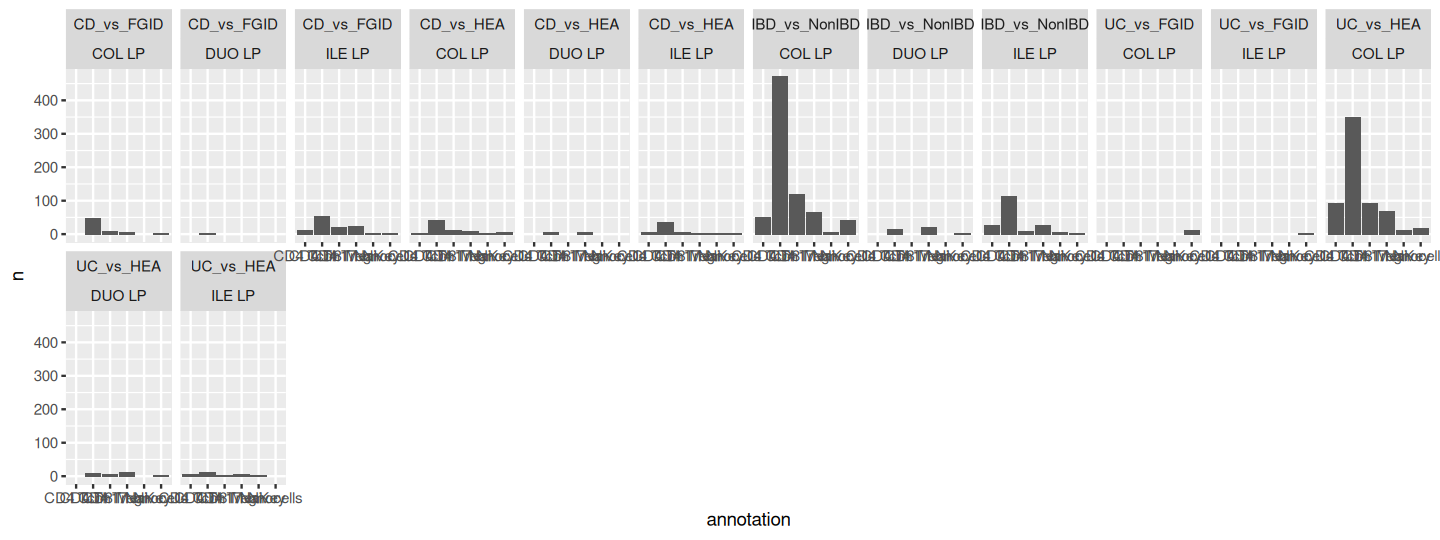

In [66]:
options(repr.plot.width = 12, repr.plot.height = 4.5)

deg_5p  %>% 
dplyr::filter(tissue != "EPI")  %>% 
dplyr::filter(p_val_adj < 0.05)  %>% 
group_by(test, annotation, tissue)  %>% 
tally()  %>% 
ggplot(aes(x=annotation, y=n)) + 
  geom_bar(stat = "identity") +facet_wrap(~test+tissue, ncol = 12)

In [67]:
deg_5p  %>% 
dplyr::filter(tissue != "EPI")  %>% 
dplyr::filter(p_val_adj < 0.05)  %>% 
group_by(test, annotation, tissue)  %>% 
tally() 

test,annotation,tissue,n
<chr>,<chr>,<chr>,<int>
CD_vs_FGID,CD4 Tcm,ILE LP,12
CD_vs_FGID,CD4 Th17,COL LP,47
CD_vs_FGID,CD4 Th17,DUO LP,1
CD_vs_FGID,CD4 Th17,ILE LP,53
CD_vs_FGID,CD4 Treg,COL LP,8
CD_vs_FGID,CD4 Treg,ILE LP,19
CD_vs_FGID,CD8 Memory,COL LP,6
CD_vs_FGID,CD8 Memory,ILE LP,23
CD_vs_FGID,NK cells,COL LP,2


In [87]:
deg_5p_count  <- deg_5p  %>% 
dplyr::filter(p_val_adj < 0.05)  %>% 
group_by(test, annotation, tissue)  %>% 
tally() 

In [75]:
deg_5p$test  %>% table

.
   CD_vs_FGID     CD_vs_HEA IBD_vs_NonIBD    UC_vs_FGID     UC_vs_HEA 
       265292        268905        265446         41531        275378 

In [69]:
aggexp_5p@meta.data  %>% colnames


[1] "orig.ident"         "cluster_sample"     "annotations_coarse"
 [4] "data_folder"        "participant_id"     "diagnosis"         
 [7] "tissue"             "layer"              "antitnf_response"  
[10] "timepoint"          "diagnosis2"

In [76]:
aggexp_5p@meta.data  %>% 
mutate(tissue = ifelse(layer == "EPI", "EPI", tissue))  %>% 
group_by(diagnosis, annotations_coarse, tissue, layer)  %>% 
tally()  %>% 
pivot_wider(names_from = diagnosis, values_from = n, values_fill = 0)  %>% 
mutate(CD_vs_FGID = CD+FGID,
       CD_vs_HEA = CD+HEA,
       IBD_vs_NonIBD = CD+FGID+HEA+UC,
       UC_vs_FGID = UC+FGID,
       UC_vs_HEA = UC+HEA)   

annotations_coarse,tissue,layer,CD,FGID,HEA,OTH,UC,Unknown,CD_vs_FGID,CD_vs_HEA,IBD_vs_NonIBD,UC_vs_FGID,UC_vs_HEA
<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
CD4 Tcm,COL,LP,25,11,9,3,16,1,36,34,61,27,25
CD4 Tcm,DUO,LP,8,3,2,0,0,1,11,10,13,3,2
CD4 Tcm,EPI,EPI,14,9,3,2,13,0,23,17,39,22,16
CD4 Tcm,ILE,LP,24,12,9,4,17,2,36,33,62,29,26
CD4 Th17,COL,LP,26,13,9,3,17,1,39,35,65,30,26
CD4 Th17,DUO,LP,24,11,9,2,5,1,35,33,49,16,14
CD4 Th17,EPI,EPI,18,5,9,3,15,3,23,27,47,20,24
CD4 Th17,ILE,LP,24,13,9,4,18,2,37,33,64,31,27
CD4 Treg,COL,LP,26,10,9,3,16,0,36,35,61,26,25


In [79]:
join_me_now  <- aggexp_5p@meta.data  %>% 
mutate(tissue = ifelse(layer == "EPI", "EPI", tissue))  %>% 
group_by(diagnosis, annotations_coarse, tissue, layer)  %>% 
tally()  %>% 
pivot_wider(names_from = diagnosis, values_from = n, values_fill = 0)  %>% 
mutate(CD_vs_FGID = CD+FGID,
       CD_vs_HEA = CD+HEA,
       IBD_vs_NonIBD = CD+FGID+HEA+UC,
       UC_vs_FGID = UC+FGID,
       UC_vs_HEA = UC+HEA)    %>% 
mutate(tissue = ifelse(layer == "EPI", "EPI", paste(tissue, layer)))  %>% 
dplyr::select(annotation = annotations_coarse, tissue, 10:14)  %>% 
pivot_longer(cols = c(3:7), names_to = "test", values_to = "n_samples")

In [80]:
join_me_now

annotation,tissue,test,n_samples
<chr>,<chr>,<chr>,<int>
CD4 Tcm,COL LP,CD_vs_FGID,36
CD4 Tcm,COL LP,CD_vs_HEA,34
CD4 Tcm,COL LP,IBD_vs_NonIBD,61
CD4 Tcm,COL LP,UC_vs_FGID,27
CD4 Tcm,COL LP,UC_vs_HEA,25
CD4 Tcm,DUO LP,CD_vs_FGID,11
CD4 Tcm,DUO LP,CD_vs_HEA,10
CD4 Tcm,DUO LP,IBD_vs_NonIBD,13
CD4 Tcm,DUO LP,UC_vs_FGID,3


In [88]:
deg_5p_count2  <- deg_5p_count  %>% 
mutate(annotation = gsub(annotation, pattern = "CD8 Memory", replacement = "CD8 and Tgd"))  %>% 
       left_join(join_me_now)

Joining with `by = join_by(test, annotation, tissue)`


In [89]:
deg_5p_count2

test,annotation,tissue,n,n_samples
<chr>,<chr>,<chr>,<int>,<int>
CD_vs_FGID,CD4 Tcm,ILE LP,12,36
CD_vs_FGID,CD4 Th17,COL LP,47,39
CD_vs_FGID,CD4 Th17,DUO LP,1,35
CD_vs_FGID,CD4 Th17,EPI,1,23
CD_vs_FGID,CD4 Th17,ILE LP,53,37
CD_vs_FGID,CD4 Treg,COL LP,8,36
CD_vs_FGID,CD4 Treg,ILE LP,19,35
CD_vs_FGID,CD8 and Tgd,COL LP,6,38
CD_vs_FGID,CD8 and Tgd,EPI,19,76


`geom_smooth()` using formula = 'y ~ x'


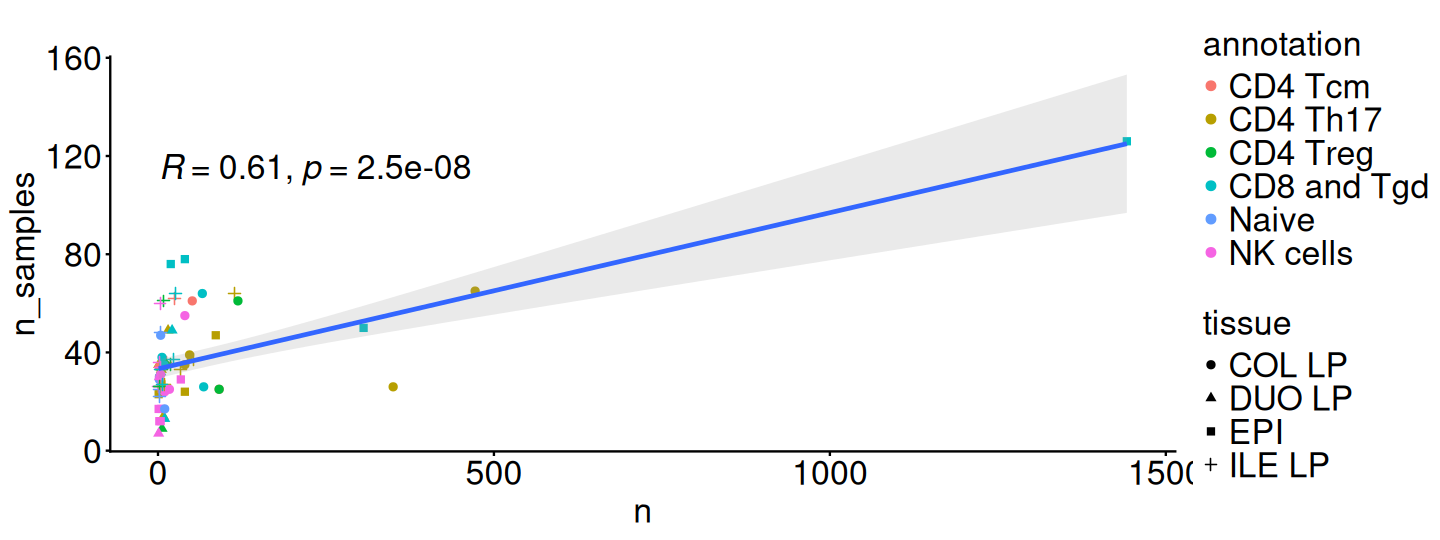

In [96]:
deg_5p_count2  %>% 
ggplot(aes(x = n, y = n_samples)) +
geom_point(size = 2, aes(color = annotation, shape = tissue)) +
  geom_smooth(method=lm, alpha = 0.2) + ggtitle(" ") + 
stat_cor(size = 7) + theme_classic() + ggtheme()

## Limma response

In [42]:
deg_3p_resp  <- read_csv("../251029_VN_PREDICT3/tables/251209_limma_response_3p.csv")
deg_5p_resp  <- read_csv("../251029_VN_PREDICT3/tables/251209_limma_response_5p.csv")

New names:
• `` -> `...1`
Rows: 366555 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (6): ...1, gene, annotation, test, tissue, prime
dbl (6): logFC, AveExpr, t, P.Value, adj.P.Val, B

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
New names:
• `` -> `...1`
Rows: 440059 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (6): ...1, gene, annotation, test, tissue, prime
dbl (6): logFC, AveExpr, t, P.Value, adj.P.Val, B

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [43]:
deg_3p_resp

...1,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene,annotation,test,tissue,prime
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
ANKRD35...1,0.06561711,0.11118598,5.328591,4.930249e-06,0.04110193,1.5817660,ANKRD35,CD4 Tcm,severity_trend,COL LP,3p
SKA3...2,0.09288413,0.10495552,5.267083,5.975041e-06,0.04110193,1.3905732,SKA3,CD4 Tcm,severity_trend,COL LP,3p
KIF4A...3,0.08026531,0.10081068,5.131812,9.111538e-06,0.04110193,0.9713074,KIF4A,CD4 Tcm,severity_trend,COL LP,3p
EFHD2...4,0.22486092,0.48278192,5.121158,9.418947e-06,0.04110193,0.9383652,EFHD2,CD4 Tcm,severity_trend,COL LP,3p
MZB1...5,0.26934967,0.58570827,4.959029,1.559038e-05,0.04610430,0.4386122,MZB1,CD4 Tcm,severity_trend,COL LP,3p
NFATC1...6,-0.21920085,0.68947811,-4.890667,1.926845e-05,0.04610430,0.2288688,NFATC1,CD4 Tcm,severity_trend,COL LP,3p
ZFP36L2...7,-0.33322708,2.46034578,-4.880606,1.987782e-05,0.04610430,0.1980539,ZFP36L2,CD4 Tcm,severity_trend,COL LP,3p
TESC...8,0.13559109,0.26245934,4.772700,2.774062e-05,0.04610430,-0.1315283,TESC,CD4 Tcm,severity_trend,COL LP,3p
NUSAP1...9,0.37815882,0.67422858,4.761699,2.869736e-05,0.04610430,-0.1650293,NUSAP1,CD4 Tcm,severity_trend,COL LP,3p


In [44]:
deg_5p_resp

...1,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene,annotation,test,tissue,prime
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
MPP1...1,-0.045930887,0.148437714,-4.468704,0.0000251629,0.4814418,-0.6008664,MPP1,CD4 Tcm,severity_trend,COL LP,5p
GFM1...2,-0.077198028,0.462739328,-3.911677,0.0001890333,1.0000000,-2.5432490,GFM1,CD4 Tcm,severity_trend,COL LP,5p
CPLANE1...3,0.042321545,0.111542246,3.838382,0.0002436610,1.0000000,-2.7859788,CPLANE1,CD4 Tcm,severity_trend,COL LP,5p
RHOT2...4,-0.106783658,0.689283301,-3.770676,0.0003072763,1.0000000,-3.0073653,RHOT2,CD4 Tcm,severity_trend,COL LP,5p
GPR171...5,0.124529209,0.445789862,3.753842,0.0003253954,1.0000000,-3.0619811,GPR171,CD4 Tcm,severity_trend,COL LP,5p
IGKC...6,0.301737206,1.570053986,3.688926,0.0004052621,1.0000000,-3.2709706,IGKC,CD4 Tcm,severity_trend,COL LP,5p
TFPI2...7,0.012559419,0.006645109,3.686377,0.0004087505,1.0000000,-3.2791235,TFPI2,CD4 Tcm,severity_trend,COL LP,5p
PRR15...8,0.014072474,0.008166816,3.663395,0.0004415206,1.0000000,-3.3524523,PRR15,CD4 Tcm,severity_trend,COL LP,5p
CNPPD1...9,-0.068829256,0.876868478,-3.572191,0.0005978655,1.0000000,-3.6401902,CNPPD1,CD4 Tcm,severity_trend,COL LP,5p


In [45]:
library(dplyr)
library(ggplot2)

# Match genes within the same annotation, tissue, and test
df_3p <- deg_3p_resp %>%
  select(gene, annotation, tissue, test, logFC_3p = logFC)

df_5p <- deg_5p_resp %>%
  select(gene, annotation, tissue, test, logFC_5p = logFC)

# Each gene should occur only once per annotation/tissue/test
keys <- c("gene", "annotation", "tissue", "test")

stopifnot(
  !anyDuplicated(df_3p[keys]),
  !anyDuplicated(df_5p[keys])
)

paired <- inner_join(df_3p, df_5p, by = keys) %>%
  filter(is.finite(logFC_3p), is.finite(logFC_5p))

# This plot assumes one shared test
stopifnot(nrow(paired) > 0, n_distinct(paired$test) == 1)

# Pearson correlation across genes within each annotation × tissue
cor_df <- paired %>%
  group_by(annotation, tissue) %>%
  group_modify(~ {
    n <- nrow(.x)

    if (n < 3 ||
        sd(.x$logFC_3p) == 0 ||
        sd(.x$logFC_5p) == 0) {
      return(tibble(n_genes = n, r = NA_real_, p = NA_real_))
    }

    result <- cor.test(.x$logFC_3p, .x$logFC_5p, method = "pearson")

    tibble(
      n_genes = n,
      r = unname(result$estimate),
      p = result$p.value
    )
  }) %>%
  ungroup() %>%
  mutate(
    stars = case_when(
      p < 0.001 ~ "***",
      p < 0.01  ~ "**",
      p < 0.05  ~ "*",
      TRUE      ~ ""
    ),
    annotation = factor(
      annotation,
      levels = unique(deg_3p_resp$annotation)
    ),
    tissue = factor(
      tissue,
      levels = rev(unique(deg_3p_resp$tissue))
    )
  )

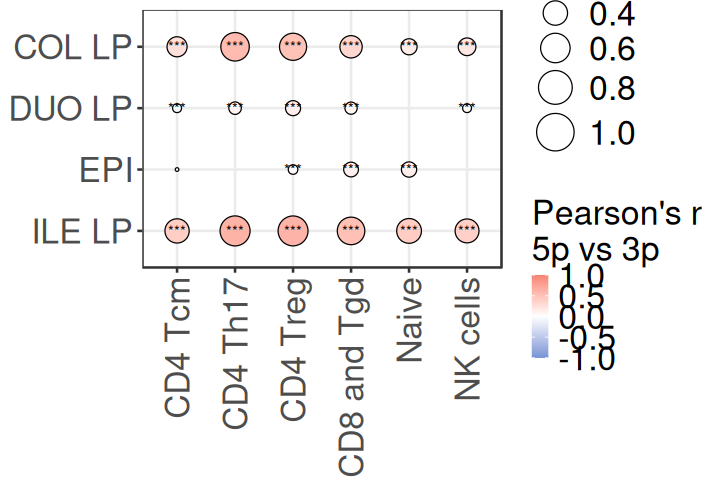

In [46]:
options(repr.plot.width = 6, repr.plot.height = 4)

# Plot
ggplot(cor_df, aes(x = annotation, y = tissue)) +
  geom_point(
    aes(size = abs(r), fill = r),
    shape = 21,
    color = "black",
    stroke = 0.4,
    na.rm = TRUE
  ) +
  geom_text(aes(label = stars), size = 3, na.rm = TRUE) +
  scale_fill_gradient2(
    low = "#7895D5",
    mid = "white",
    high = "#F58475",
    midpoint = 0,
    limits = c(-1, 1),
    name = "Pearson's r\n5p vs 3p"
  ) +
  scale_size_area(
    max_size = 10,
    limits = c(0, 1),
    breaks = c(0.2, 0.4, 0.6, 0.8, 1),
    name = "|r|"
  ) +
  scale_x_discrete(drop = FALSE) +
  scale_y_discrete(drop = FALSE) +
  labs(x = NULL, y = NULL) +
  theme_bw(base_size = 12) +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_line(color = "grey92"),
    legend.position = "right"
  ) +
ggtheme()

In [47]:
ggsave("figures/correlation_response_limma.svg", width = 14, height = 10, units = "cm")

In [54]:
de_5p$tissue  %>% table

.
COL LP DUO LP    EPI ILE LP 
114798  95665 114798 114798 

In [55]:
de_3p$tissue  %>% table

.
COL LP DUO LP    EPI ILE LP 
104730  87275  69820 104730 

In [64]:
library(dplyr)
library(fgsea)
library(ggplot2)

# 1. Select the response comparison
de_5p <- deg_5p_resp
de_3p <- deg_3p_resp

# If needed, filter BOTH tables, for example:
 de_5p <- de_5p %>%
   filter(annotation == "CD4 Th17", tissue == "ILE LP",
          test == "severity_trend")

 de_3p <- de_3p %>%
   filter(annotation == "CD4 Th17", tissue == "ILE LP",
          test == "severity_trend")

# Check that both tables contain the same single comparison
groups_5p <- distinct(de_5p, annotation, test, tissue)
groups_3p <- distinct(de_3p, annotation, test, tissue)

if (
  nrow(groups_5p) != 1L ||
  nrow(groups_3p) != 1L ||
  nrow(inner_join(
    groups_5p, groups_3p,
    by = c("annotation", "test", "tissue")
  )) != 1L
) {
  stop("Filter both tables to the same single annotation, test, and tissue.")
}

# 2. Define the significantly upregulated 5p signature
genes_up_5p <- de_5p %>%
  filter(
    adj.P.Val < 0.05,
    logFC > 0,
    !is.na(gene),
    gene != ""
  ) %>%
  pull(gene) %>%
  as.character() %>%
  unique()

# 3. Rank all available 3p genes by logFC
# No significance filtering here
de_3p_rank <- de_3p %>%
  transmute(
    gene = as.character(gene),
    logFC = logFC
  ) %>%
  filter(
    !is.na(gene),
    gene != "",
    is.finite(logFC)
  ) %>%
  arrange(desc(logFC), gene)

if (anyDuplicated(de_3p_rank$gene)) {
  stop("Duplicate gene names in the 3p subset; resolve before GSEA.")
}

ranks_3p <- setNames(de_3p_rank$logFC, de_3p_rank$gene)

# 4. Retain signature genes present in the 3p ranking
signature_genes <- intersect(genes_up_5p, names(ranks_3p))

message(
  "Upregulated genes in 5p: ", length(genes_up_5p),
  "; present in 3p: ", length(signature_genes)
)

if (length(signature_genes) < 15L) {
  stop("Fewer than 15 matching signature genes for minSize = 15.")
}

if (length(signature_genes) == length(ranks_3p)) {
  stop("The signature includes every ranked gene; enrichment cannot be tested.")
}

# 5. GSEA
set.seed(123)

gsea_resp <- fgseaMultilevel(
  pathways = list(Response_up_in_5p = signature_genes),
  stats = ranks_3p,
  minSize = 15,
  maxSize = length(ranks_3p) - 1L,
  scoreType = "std",
  eps = 0,
  nproc = 1
)

gsea_resp %>%
  as.data.frame() %>%
  select(pathway, size, ES, NES, pval, padj, leadingEdge)

# 6. Enrichment plot
p_resp <- plotEnrichment(
  pathway = signature_genes,
  stats = ranks_3p
) +
  labs(
    title = "5p response signature in the 3p dataset",
    subtitle = paste0(
      groups_3p$annotation, " | ",
      groups_3p$tissue, " | ",
      groups_3p$test,
      "NES = ", round(gsea_resp$NES, 2),
      "; p = ", format.pval(gsea_resp$pval, digits = 2)
    ),
    x = "3p genes ranked by decreasing logFC",
    y = "Enrichment score"
  ) +
  theme_classic()

Upregulated genes in 5p: 258; present in 3p: 248

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (4.81% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”


  |======================================================================| 100%



pathway,size,ES,NES,pval,padj,leadingEdge
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<list>
Response_up_in_5p,248,0.8702769,2.491631,1.869169e-43,1.869169e-43,"IGKC, IG...."


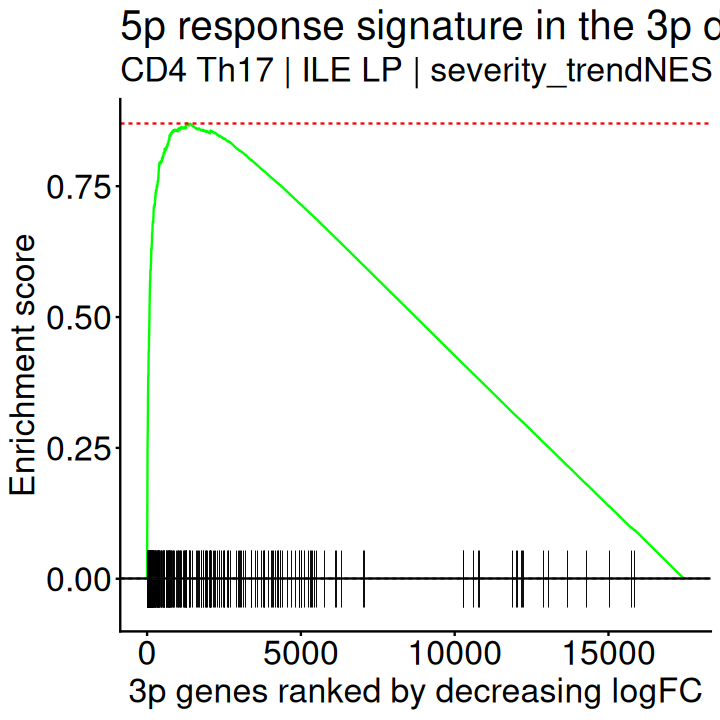

In [65]:
options(repr.plot.width = 6, repr.plot.height = 6)
p_resp +ggtheme()


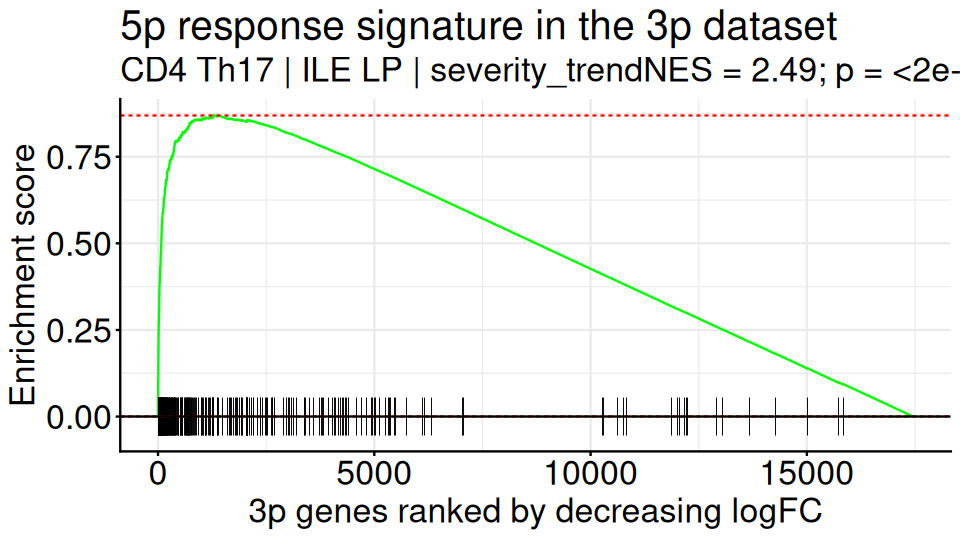

In [93]:
p_resp +
theme_classic() +
  theme(
    panel.grid.major = element_line(color = "grey92", linewidth = 0.5),
    panel.grid.minor = element_line(color = "grey92", linewidth = 0.25)
  ) +
ggtheme()
ggsave("figures/gsea_5p_3p_th17_aTNFlimma.svg", width = 12, height = 10, units = "cm")

# Annotations Rose

In [110]:
ls()

[1] "aggexp_3p"             "aggexp_5p"             "annotations"          
 [4] "annots"                "celltypist"            "colour_max"           
 [7] "comparisons"           "cor_plot_df"           "cor_results"          
[10] "counts_all"            "deg_3p"                "deg_5p"               
[13] "deg_all_tissues_deseq" "deg_counts"            "diagonal"             
[16] "dir_3p"                "dir_5p"                "ds_sub"               
[19] "duplicates"            "files"                 "genes"                
[22] "genes_filt_3p"         "genes_filt_5p"         "ggtheme"              
[25] "gut_allt_3p"           "gut_allt_5p"           "jobs"                 
[28] "keep_labels"           "keep_samples"          "label_freq"           
[31] "label_genes"           "label_keys"            "loaded"               
[34] "matched_genes"         "md"                    "md_5p_celltypist"     
[37] "md_to_join"            "metadata_all"          "mirrored"             
[40] "missing_labels"        "out_dir"               "p"                    
[43] "p_scatter"             "p_th17"                "p_tissues"            
[46] "plot_df"               "pt_3p"                 "read_results"         
[49] "read_significant"      "result_dirs"           "rho_limit"            
[52] "sample_counts"         "sample_counts_wide"    "scatter_df"           
[55] "scatter_long"          "scimilarity"           "shared_sig_genes"     
[58] "sig_genes"             "test_name"             "test_status"          
[61] "test_status_wide"      "tests"                 "th17_plot_df"         
[64] "tissue_cor"            "tissue_data"           "tissue_layers"        
[67] "tissue_pairs"          "tissue_plot_df"        "tissues"              
[70] "tl"

In [60]:
celltypist  <- read_csv("data/celltypist_combined_corrected.csv")

Rows: 4027680 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): Unnamed: 0, index, predicted_labels, bc, tissue
dbl (1): celltypist_score

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [61]:
celltypist

Unnamed: 0,index,predicted_labels,celltypist_score,bc,tissue
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
0,CD3NK3p__Cell1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive helper T cells,0.58769397,CD3NK3p__Cell1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
1,CD3NK3p__Cell2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive cytotoxic T cells,0.07771772,CD3NK3p__Cell2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
2,CD3NK3p__Cell3_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tem/Temra cytotoxic T cells,0.44145688,CD3NK3p__Cell3_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
3,CD3NK3p__Cell4_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive cytotoxic T cells,0.76144294,CD3NK3p__Cell4_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
4,CD3NK3p__Cell5_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive cytotoxic T cells,0.83785015,CD3NK3p__Cell5_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
5,CD3NK3p__Cell6_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Regulatory T cells,0.99772948,CD3NK3p__Cell6_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
6,CD3NK3p__Cell7_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive helper T cells,0.85059173,CD3NK3p__Cell7_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
7,CD3NK3p__Cell8_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Regulatory T cells,0.82817857,CD3NK3p__Cell8_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
8,CD3NK3p__Cell9_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive cytotoxic T cells,0.79371217,CD3NK3p__Cell9_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p


In [62]:
celltypist$tissue  %>% table


.
 blood_3p  blood_5p tissue_3p tissue_5p 
   281048    776303    208415   2643346 

In [63]:
gut_allt_3p

An object of class Seurat 
28494 features across 283277 samples within 2 assays 
Active assay: integrated (1000 features, 1000 variable features)
 2 layers present: data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

In [64]:
gut_allt_5p

An object of class Seurat 
74202 features across 588063 samples within 3 assays 
Active assay: integrated (1000 features, 1000 variable features)
 2 layers present: data, scale.data
 2 other assays present: RNA, RNA3
 2 dimensional reductions calculated: pca, umap

In [65]:
celltypist$tissue  %>% table

.
 blood_3p  blood_5p tissue_3p tissue_5p 
   281048    776303    208415   2643346 

In [66]:
colnames(celltypist)

[1] "Unnamed: 0"       "index"            "predicted_labels" "celltypist_score"
[5] "bc"               "tissue"

In [67]:
scimilarity  <- read_csv("data/scimilarity_combined_corrected.csv.gz")

Rows: 6301646 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (7): index, SC_bc, SC_predictions_unconstrained, SC_celltype_hint, SC_ce...
dbl (3): SC_min_dist, SC_celltype_hint_stat, SC_celltype_hint_weighted_stat

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [68]:
all.equal(celltypist$index, celltypist$bc)

[1] "'is.NA' value mismatch: 0 in current 118568 in target"

In [69]:
table(is.na(celltypist$bc))


  FALSE 
4027680 

In [70]:
table(gut_allt_3p$barcode %in% celltypist$bc)


 FALSE 
283277 

In [71]:
celltypist  <- celltypist  %>% separate(bc, into = c("dataset","bc2"), remove = F, sep = "__")

Warning message:
“Expected 2 pieces. Missing pieces filled with `NA` in 3419649 rows [281049,
281050, 281051, 281052, 281053, 281054, 281055, 281056, 281057, 281058, 281059,
281060, 281061, 281062, 281063, 281064, 281065, 281066, 281067, 281068, ...].”


In [72]:
table(gut_allt_3p$barcode %in% celltypist$bc2)


 FALSE   TRUE 
 74862 208415 

In [73]:
table(colnames(gut_allt_3p) %in% celltypist$bc2)


 FALSE   TRUE 
 74862 208415 

In [74]:
table(colnames(gut_allt_5p) %in% celltypist$bc2)


 FALSE 
588063 

In [75]:
head(colnames(gut_allt_5p))

[1] "AAACCTGAGAGCCTAG-1_1193610_1_1_1_1" "AAACCTGCAGTCACTA-1_1193610_1_1_1_1"
[3] "AAACCTGCATCGGACC-1_1193610_1_1_1_1" "AAACCTGTCGCCAGCA-1_1193610_1_1_1_1"
[5] "AAACCTGTCGCGATCG-1_1193610_1_1_1_1" "AAACCTGTCTTCGGTC-1_1193610_1_1_1_1"

In [76]:
tail(colnames(gut_allt_5p))

[1] "TGGCGCACACACTGCG-1_1542415_1_1_1_2" "TGGGAAGCACTTAACG-1_1542415_1_1_1_2"
[3] "TGTATTCGTCATATGC-1_1542415_1_1_1_2" "TGTGTTTGTGGGTATG-1_1542415_1_1_1_2"
[5] "TTCTCCTAGGCGATAC-1_1542415_1_1_1_2" "TTGCCGTCATTGGGCC-1_1542415_1_1_1_2"

In [77]:
table(substr(colnames(gut_allt_5p),1,nchar(colnames(gut_allt_5p))-2) %in% celltypist$bc)


 FALSE   TRUE 
 10796 577267 

In [78]:
celltypist  %>% dplyr::filter(tissue == "tissue_5p")

Unnamed: 0,index,predicted_labels,celltypist_score,bc,dataset,bc2,tissue
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
1057351,0,Stromal 1 (CCL11+),0.9985714,AAACCTGAGAAGGCCT-1_1193611_1_1_1,AAACCTGAGAAGGCCT-1_1193611_1_1_1,NA,tissue_5p
1057352,1,Activated CD4 T,0.8611341,AAACCTGAGATGTAAC-1_1193611_1_1_1,AAACCTGAGATGTAAC-1_1193611_1_1_1,NA,tissue_5p
1057353,2,Stromal 2 (NPY+),0.9604327,AAACCTGAGCACCGTC-1_1193611_1_1_1,AAACCTGAGCACCGTC-1_1193611_1_1_1,NA,tissue_5p
1057354,3,Naive B,0.7863759,AAACCTGAGCGAGAAA-1_1193611_1_1_1,AAACCTGAGCGAGAAA-1_1193611_1_1_1,NA,tissue_5p
1057355,4,ILC3,0.9999721,AAACCTGAGCGATTCT-1_1193611_1_1_1,AAACCTGAGCGATTCT-1_1193611_1_1_1,NA,tissue_5p
1057356,5,Stromal 1 (CCL11+),0.9983596,AAACCTGAGGGAGTAA-1_1193611_1_1_1,AAACCTGAGGGAGTAA-1_1193611_1_1_1,NA,tissue_5p
1057357,6,Th17,0.9710051,AAACCTGAGTGGCACA-1_1193611_1_1_1,AAACCTGAGTGGCACA-1_1193611_1_1_1,NA,tissue_5p
1057358,7,Memory B,0.9171577,AAACCTGAGTGTCTCA-1_1193611_1_1_1,AAACCTGAGTGTCTCA-1_1193611_1_1_1,NA,tissue_5p
1057359,9,Treg,0.9814352,AAACCTGCAAGTACCT-1_1193611_1_1_1,AAACCTGCAAGTACCT-1_1193611_1_1_1,NA,tissue_5p


In [79]:
head(colnames(gut_allt_5p))

[1] "AAACCTGAGAGCCTAG-1_1193610_1_1_1_1" "AAACCTGCAGTCACTA-1_1193610_1_1_1_1"
[3] "AAACCTGCATCGGACC-1_1193610_1_1_1_1" "AAACCTGTCGCCAGCA-1_1193610_1_1_1_1"
[5] "AAACCTGTCGCGATCG-1_1193610_1_1_1_1" "AAACCTGTCTTCGGTC-1_1193610_1_1_1_1"

In [80]:
celltypist   %>% group_by(dataset)  %>% tally()

dataset,n
<chr>,<int>
AAACCCAAGCCTGTCG-1_1740285_1_1_1,1
AAACCCAGTATGGTAA-1_1740285_1_1_1,1
AAACCCAGTCTCGACG-1_1740285_1_1_1,1
AAACCCAGTCTCGGAC-1_1740285_1_1_1,1
AAACCCATCGGCATAT-1_1740285_1_1_1,1
AAACCTGAGAAACCAT-1_003-043_T0_BLD_PBMC_5p_GEX,1
AAACCTGAGAAACCAT-1_1193582_1_1_1,1
AAACCTGAGAAACCAT-1_1405453_1_1_1,1
AAACCTGAGAAACCAT-1_1737906_1_1_1,1


In [81]:
celltypist

Unnamed: 0,index,predicted_labels,celltypist_score,bc,dataset,bc2,tissue
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
0,CD3NK3p__Cell1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive helper T cells,0.58769397,CD3NK3p__Cell1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,CD3NK3p,Cell1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
1,CD3NK3p__Cell2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive cytotoxic T cells,0.07771772,CD3NK3p__Cell2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,CD3NK3p,Cell2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
2,CD3NK3p__Cell3_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tem/Temra cytotoxic T cells,0.44145688,CD3NK3p__Cell3_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,CD3NK3p,Cell3_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
3,CD3NK3p__Cell4_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive cytotoxic T cells,0.76144294,CD3NK3p__Cell4_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,CD3NK3p,Cell4_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
4,CD3NK3p__Cell5_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive cytotoxic T cells,0.83785015,CD3NK3p__Cell5_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,CD3NK3p,Cell5_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
5,CD3NK3p__Cell6_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Regulatory T cells,0.99772948,CD3NK3p__Cell6_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,CD3NK3p,Cell6_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
6,CD3NK3p__Cell7_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Tcm/Naive helper T cells,0.85059173,CD3NK3p__Cell7_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,CD3NK3p,Cell7_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,blood_3p
7,CD3NK3p__Cell8_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,Regulatory T cells,0.82817857,CD3NK3p__Cell8_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,

In [82]:
md_5p_celltypist  <- gut_allt_5p@meta.data  %>% 
mutate(bc2 = substr(colnames(gut_allt_5p),1,nchar(colnames(gut_allt_5p))-2))  %>% 
left_join(celltypist  %>% dplyr::select(predicted_labels, celltypist_score, bc2 = bc))

Joining with `by = join_by(predicted_labels, celltypist_score, bc2)`


In [84]:
gut_allt_5p@meta.data

,orig.ident,nCount_RNA,nFeature_RNA,bc,data_folder,data_folder2,sample,diagnosis,subgroup_primary,subgroup_secondary,⋯,clone_aa,annotations,orig_cluster,RNA_snn_res.0.4,integrated_snn_res.0.3,integrated_snn_res.0.9,integrated_snn_res.0.2,annotations_coarse,cluster_sample,keep_pseudobulk
,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<fct>,<fct>,<fct>,<fct>,<chr>,<lgl>
AAACCTGAGAGCCTAG-1_1193610_1_1_1_1,SeuratProject,1984.128,1356,AAACCTGAGAGCCTAG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,CDR3b CASSQGTGGRLGEQYF CDR3a NA,Naive_1,1,NA,3,2,3,Naive,Naive__1193610_1_1_1,TRUE
AAACCTGCAGTCACTA-1_1193610_1_1_1_1,SeuratProject,2306.014,1404,AAACCTGCAGTCACTA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,CDR3b CSARRTPAGGSNEQFF CDR3a NA,Tfh,4,NA,1,8,1,CD4 Tcm,CD4 Tcm__1193610_1_1_1,TRUE
AAACCTGCATCGGACC-1_1193610_1_1_1_1,SeuratProject,1887.165,836,AAACCTGCATCGGACC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,CDR3b CASSLQGLSSSYEQYF CDR3a CATDLDGANSKLTF,Tfh,4,NA,1,4,1,CD4 Tcm,CD4 Tcm__1193610_1_1_1,TRUE
AAACCTGTCGCCAGCA-1_1193610_1_1_1_1,SeuratProject,2134.483,1068,AAACCTGTCGCCAGCA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,CDR3b CATSPTSGQGALYNEQFF CDR3a CALVGSSNTGKLIF,Tcm,3,NA,1,4,1,CD4 Tcm,CD4 Tcm__1193610_1_1_1,TRUE
AAACCTGTCGCGATCG-1_1193610_1_1_1_1,SeuratProject,2163.869,1177,AAACCTGTCGCGATCG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,CDR3b CASSLWGVSGNTIYF CDR3a CAENRETSYDKVIF,Naive_1,1,NA,3,2,3,Naive,Naive__1193610_1_1_1,TRUE
AAACCTGTCTTCGGTC-1_1193610_1_1_1_1,SeuratProject,1958.522,969,AAACCTGTCTTCGGTC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,CDR3b CASSTGQENQPQHF CDR3a CALIPMDSSYKLIF,Naive_1,1,NA,3,2,3,Naive,Naive__1193610_1_1_1,TRUE
AAACGGGAGCGTTTAC-1_1193610_1_1_1_1,SeuratProject,1681.969,699,AAACGGGAGCGTTTAC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,CDR3b CASKGDNQETQYF CDR3a NA,Tcm,3,NA,1,4,1,CD4 Tcm,CD4 Tcm__1193610_1_1_1,TRUE
AAACGGGCACAGACTT-1_1193610_1_1_1_1,SeuratProject,2296.136,1268,AAACGGGCACAGACTT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,CDR3b CASSLRQGRDTGELFF CDR3a CAALSGSARQLTF,Th17_1,7,NA,11,6,0,CD4 Th17,CD4 Th17__1193610_1_1_1,TRUE
AAACGGGCAGGTGCCT-1_1193610_1_1_1_1,SeuratProject,2114.526,988,AAACGGGCAGGTGCCT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,CDR3b CASSEGTGFANEKLFF CDR3a CASPTGGGTALIF,Tcm,3,NA,1,4,1,CD4 Tcm,CD4 Tcm__1193610_1_1_1,TRUE


In [83]:
md_5p_celltypist

orig.ident,nCount_RNA,nFeature_RNA,bc,data_folder,data_folder2,sample,diagnosis,subgroup_primary,subgroup_secondary,⋯,annotations,orig_cluster,RNA_snn_res.0.4,integrated_snn_res.0.3,integrated_snn_res.0.9,integrated_snn_res.0.2,annotations_coarse,cluster_sample,keep_pseudobulk,bc2
<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<fct>,<fct>,<fct>,<fct>,<chr>,<lgl>,<chr>
SeuratProject,1984.128,1356,AAACCTGAGAGCCTAG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,Naive_1,1,NA,3,2,3,Naive,Naive__1193610_1_1_1,TRUE,AAACCTGAGAGCCTAG-1_1193610_1_1_1
SeuratProject,2306.014,1404,AAACCTGCAGTCACTA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,Tfh,4,NA,1,8,1,CD4 Tcm,CD4 Tcm__1193610_1_1_1,TRUE,AAACCTGCAGTCACTA-1_1193610_1_1_1
SeuratProject,1887.165,836,AAACCTGCATCGGACC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,Tfh,4,NA,1,4,1,CD4 Tcm,CD4 Tcm__1193610_1_1_1,TRUE,AAACCTGCATCGGACC-1_1193610_1_1_1
SeuratProject,2134.483,1068,AAACCTGTCGCCAGCA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,Tcm,3,NA,1,4,1,CD4 Tcm,CD4 Tcm__1193610_1_1_1,TRUE,AAACCTGTCGCCAGCA-1_1193610_1_1_1
SeuratProject,2163.869,1177,AAACCTGTCGCGATCG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,Naive_1,1,NA,3,2,3,Naive,Naive__1193610_1_1_1,TRUE,AAACCTGTCGCGATCG-1_1193610_1_1_1
SeuratProject,1958.522,969,AAACCTGTCTTCGGTC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,Naive_1,1,NA,3,2,3,Naive,Naive__1193610_1_1_1,TRUE,AAACCTGTCTTCGGTC-1_1193610_1_1_1
SeuratProject,1681.969,699,AAACGGGAGCGTTTAC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,Tcm,3,NA,1,4,1,CD4 Tcm,CD4 Tcm__1193610_1_1_1,TRUE,AAACGGGAGCGTTTAC-1_1193610_1_1_1
SeuratProject,2296.136,1268,AAACGGGCACAGACTT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,Th17_1,7,NA,11,6,0,CD4 Th17,CD4 Th17__1193610_1_1_1,TRUE,AAACGGGCACAGACTT-1_1193610_1_1_1
SeuratProject,2114.526,988,AAACGGGCAGGTGCCT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,Tcm,3,NA,1,4,1,CD4 Tcm,CD4 Tcm__1193610_1_1_1,TRUE,AAACGGGCAGGTGCCT-1_1193610_1_1_1


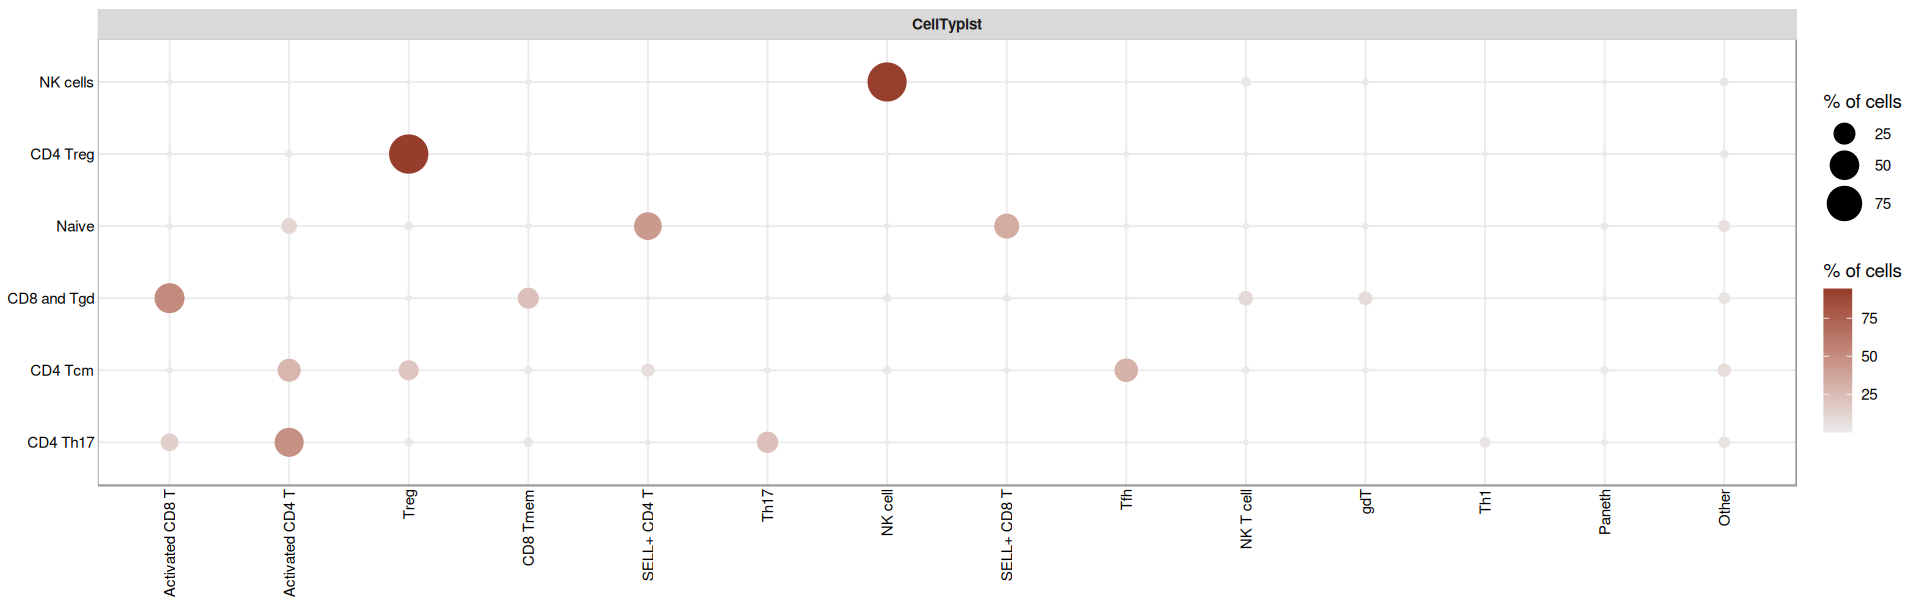

In [85]:

# 1. Identify CellTypist labels covering >=95% of predictions
label_freq <- md_5p_celltypist %>%
  filter(!is.na(predicted_labels)) %>%
  count(predicted_labels, name = "n") %>%
  arrange(desc(n)) %>%
  mutate(cumulative = cumsum(n) / sum(n))

keep_labels <- label_freq %>%
  filter(lag(cumulative, default = 0) < 0.95) %>%
  pull(predicted_labels)

# 2. Group remaining labels as Other
plot_df <- md_5p_celltypist %>%
  filter(!is.na(annotations_coarse),
         !is.na(predicted_labels)) %>%
  mutate(
    celltypist = ifelse(
      predicted_labels %in% keep_labels,
      predicted_labels,
      "Other"
    )
  ) %>%
  count(annotations_coarse, celltypist, name = "n") %>%
  group_by(annotations_coarse) %>%
  mutate(pct = 100 * n / sum(n)) %>%
  ungroup() %>%
  complete(
    annotations_coarse,
    celltypist = c(keep_labels, "Other"),
    fill = list(n = 0, pct = 0)
  ) %>%
  mutate(
    celltypist = factor(
      celltypist,
      levels = c(keep_labels, "Other")
    )
  )

# 3. Dot plot
ggplot(plot_df,
       aes(x = celltypist,
           y = annotations_coarse,
           size = pct,
           color = pct)) +
  geom_point() +
  scale_size_area(max_size = 10) +
  scale_color_gradient(
    low = "grey92",
    high = "#963D2C"
  ) +
  facet_grid(~ "CellTypist") +
  labs(
    x = NULL,
    y = NULL,
    size = "% of cells",
    color = "% of cells"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(
      angle = 90, hjust = 1, vjust = 0.5
    ),
    strip.background = element_rect(
      fill = "grey85", color = "grey85"
    ),
    strip.text = element_text(face = "bold"),
    panel.border = element_rect(
      color = "grey60", fill = NA
    ),
    panel.grid.major = element_line(
      color = "grey92", linewidth = 0.4
    ),
    axis.line = element_blank(),
    axis.ticks = element_blank()
  )

# LogFC patient level 3p

In [87]:
library(dplyr)
library(tidyr)
library(purrr)
library(ggplot2)

dir_3p <- "tables/deg_patient_level_3p_20261019_090412"
dir_5p <- "tables/deg_patient_level_5p_20261022_095445"

tissues <- c("DUO LP", "ILE LP", "COL LP", "EPI")

tests <- c(
  "CD_vs_FGID",
  "CD_vs_HEA",
  "IBD_vs_NonIBD",
  "UC_vs_FGID",
  "UC_vs_HEA"
)

annotations <- c(
  "CD4 Tcm",
  "CD4 Th17",
  "CD4 Treg",
  "CD8 and Tgd",
  "Naive",
  "NK cells"
)

tables/deg_patient_level_3p_20261019_090412: found 80 of 120 expected files

tables/deg_patient_level_5p_20261022_095445: found 108 of 120 expected files



tissue_layer,test,annotation,n_genes,rho,p_value
<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>
COL LP,CD_vs_FGID,CD4 Tcm,734,0.27520269,3.193010e-14
COL LP,CD_vs_FGID,CD4 Th17,757,0.52254498,2.886788e-54
COL LP,CD_vs_FGID,CD4 Treg,747,0.41060530,9.535468e-32
COL LP,CD_vs_FGID,CD8 and Tgd,763,0.28738304,5.650850e-16
COL LP,CD_vs_FGID,NK cells,701,0.19132863,3.327645e-07
COL LP,CD_vs_FGID,Naive,692,0.17041208,6.551879e-06
COL LP,CD_vs_HEA,CD4 Treg,750,0.25576552,1.149077e-12
COL LP,CD_vs_HEA,CD8 and Tgd,766,0.27645228,6.641155e-15
COL LP,CD_vs_HEA,NK cells,709,0.14127709,1.605862e-04


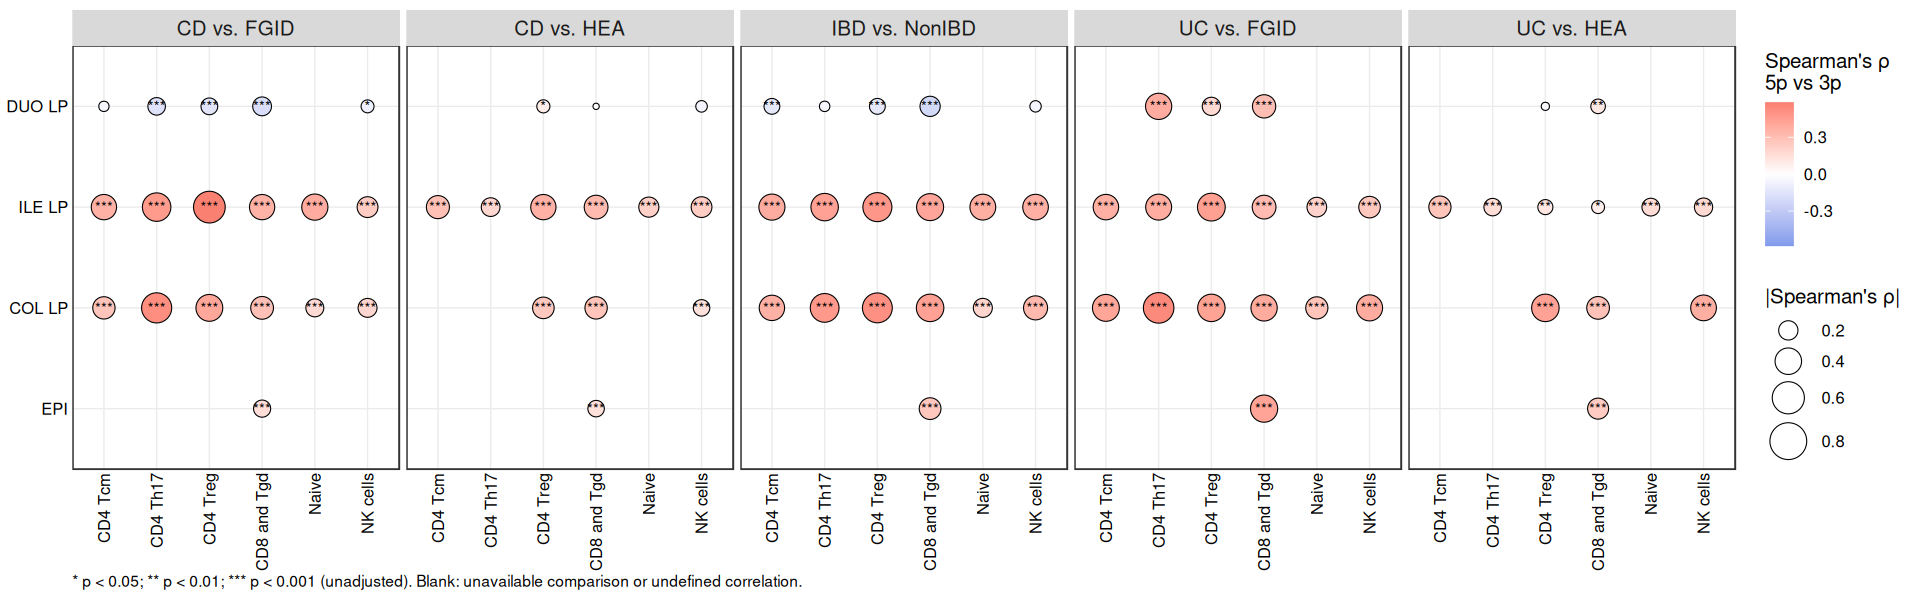

In [88]:
# ---- Read results ----
read_results <- function(root_dir) {

  expected <- expand_grid(
    tissue_layer = tissues,
    test = tests,
    annotation = annotations
  ) %>%
    mutate(
      file = file.path(
        root_dir, tissue_layer, test,
        paste0(annotation, ".csv")
      )
    )

  present <- expected %>%
    filter(file.exists(file))

  if (nrow(present) == 0L) {
    stop("No result files found in: ", root_dir)
  }

  message(
    root_dir, ": found ", nrow(present),
    " of ", nrow(expected), " expected files"
  )

  pmap_dfr(
    present,
    function(tissue_layer, test, annotation, file) {

      dat <- read.csv(
        file,
        check.names = FALSE,
        stringsAsFactors = FALSE
      )

      if (!all(c("gene", "avg_log2FC") %in% names(dat))) {
        stop("Missing gene or avg_log2FC column in: ", file)
      }

      dat <- dat %>%
        filter(
          !is.na(gene),
          nzchar(gene),
          is.finite(avg_log2FC)
        )

      if (anyDuplicated(dat$gene)) {
        stop("Duplicate gene names in: ", file)
      }

      tibble(
        tissue_layer = rep(tissue_layer, nrow(dat)),
        test = rep(test, nrow(dat)),
        annotation = rep(annotation, nrow(dat)),
        gene = as.character(dat$gene),
        logFC = dat$avg_log2FC
      )
    }
  )
}

deg_3p <- read_results(dir_3p)
deg_5p <- read_results(dir_5p)

# ---- Match all shared genes ----
matched_genes <- inner_join(
  rename(deg_3p, logFC_3p = logFC),
  rename(deg_5p, logFC_5p = logFC),
  by = c("tissue_layer", "test", "annotation", "gene")
)

# ---- Spearman correlation per comparison ----
cor_results <- matched_genes %>%
  group_by(tissue_layer, test, annotation) %>%
  group_modify(~ {
    dat <- .x
    n_genes <- nrow(dat)

    if (
      n_genes < 3L ||
      sd(dat$logFC_3p) == 0 ||
      sd(dat$logFC_5p) == 0
    ) {
      return(tibble(
        n_genes = n_genes,
        rho = NA_real_,
        p_value = NA_real_
      ))
    }

    ct <- cor.test(
      dat$logFC_3p,
      dat$logFC_5p,
      method = "spearman",
      exact = FALSE
    )

    tibble(
      n_genes = n_genes,
      rho = unname(ct$estimate),
      p_value = ct$p.value
    )
  }) %>%
  ungroup()

# ---- Complete plotting grid ----
cor_plot_df <- expand_grid(
  tissue_layer = tissues,
  test = tests,
  annotation = annotations
) %>%
  left_join(
    cor_results,
    by = c("tissue_layer", "test", "annotation")
  ) %>%
  mutate(
    abs_rho = abs(rho),
    stars = case_when(
      is.na(p_value) ~ "",
      p_value < 0.001 ~ "***",
      p_value < 0.01  ~ "**",
      p_value < 0.05  ~ "*",
      TRUE ~ ""
    ),
    annotation = factor(annotation, levels = annotations),
    tissue_layer = factor(
      tissue_layer,
      levels = rev(tissues)
    ),
    test = factor(test, levels = tests)
  )

if (!any(is.finite(cor_plot_df$rho))) {
  stop("No valid correlations: check shared genes and logFC variation.")
}

rho_limit <- max(0.1, abs(cor_plot_df$rho), na.rm = TRUE)



In [89]:
# BH correction across all tissue × test × annotation correlations

cor_results <- cor_results %>%
  mutate(p_fdr = p.adjust(p_value, method = "BH"))

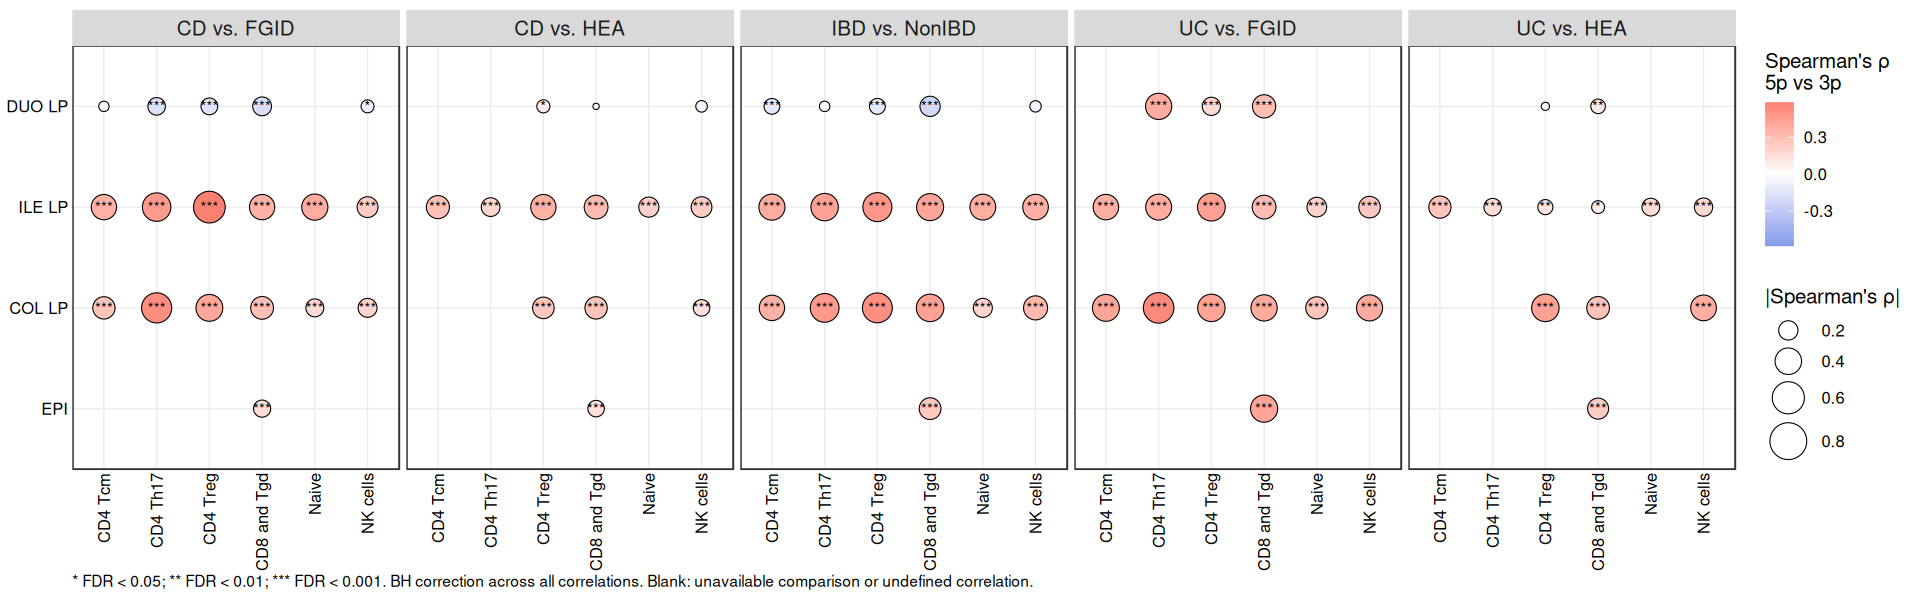

In [90]:
# Rebuild plotting data
cor_plot_df <- expand_grid(
  tissue_layer = tissues,
  test = tests,
  annotation = annotations
) %>%
  left_join(
    cor_results,
    by = c("tissue_layer", "test", "annotation")
  ) %>%
  mutate(
    abs_rho = abs(rho),
    stars = case_when(
      is.na(p_fdr) ~ "",
      p_fdr < 0.001 ~ "***",
      p_fdr < 0.01  ~ "**",
      p_fdr < 0.05  ~ "*",
      TRUE ~ ""
    ),
    annotation = factor(annotation, levels = annotations),
    tissue_layer = factor(tissue_layer, levels = rev(tissues)),
    test = factor(test, levels = tests)
  )

# Update the existing plot and its two data-specific layers
p$data <- cor_plot_df

p$layers[[1]]$data <- filter(cor_plot_df, is.finite(rho))
p$layers[[2]]$data <- filter(cor_plot_df, is.finite(rho))

p <- p +
  labs(
    caption = paste(
      "* FDR < 0.05; ** FDR < 0.01; *** FDR < 0.001.",
      "BH correction across all correlations.",
      "Blank: unavailable comparison or undefined correlation."
    )
  )

p

# Correlation between tissues

prime,annotation,tissue1,tissue2,n_genes,rho,p_value,p_fdr
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
3p,CD4 Tcm,DUO LP,ILE LP,10308,0.09975220,3.253961e-24,3.845590e-24
3p,CD4 Tcm,DUO LP,COL LP,10263,0.11420846,3.813089e-31,4.957015e-31
3p,CD4 Tcm,DUO LP,EPI,0,NA,NA,NA
3p,CD4 Tcm,ILE LP,COL LP,12305,0.33649194,1.976263e-323,2.569141e-322
3p,CD4 Tcm,ILE LP,EPI,0,NA,NA,NA
3p,CD4 Tcm,COL LP,EPI,0,NA,NA,NA
3p,CD4 Th17,DUO LP,ILE LP,12511,0.22016826,3.481162e-137,2.262755e-136
3p,CD4 Th17,DUO LP,COL LP,12402,0.25746508,5.800544e-187,5.027138e-186
3p,CD4 Th17,DUO LP,EPI,0,NA,NA,NA


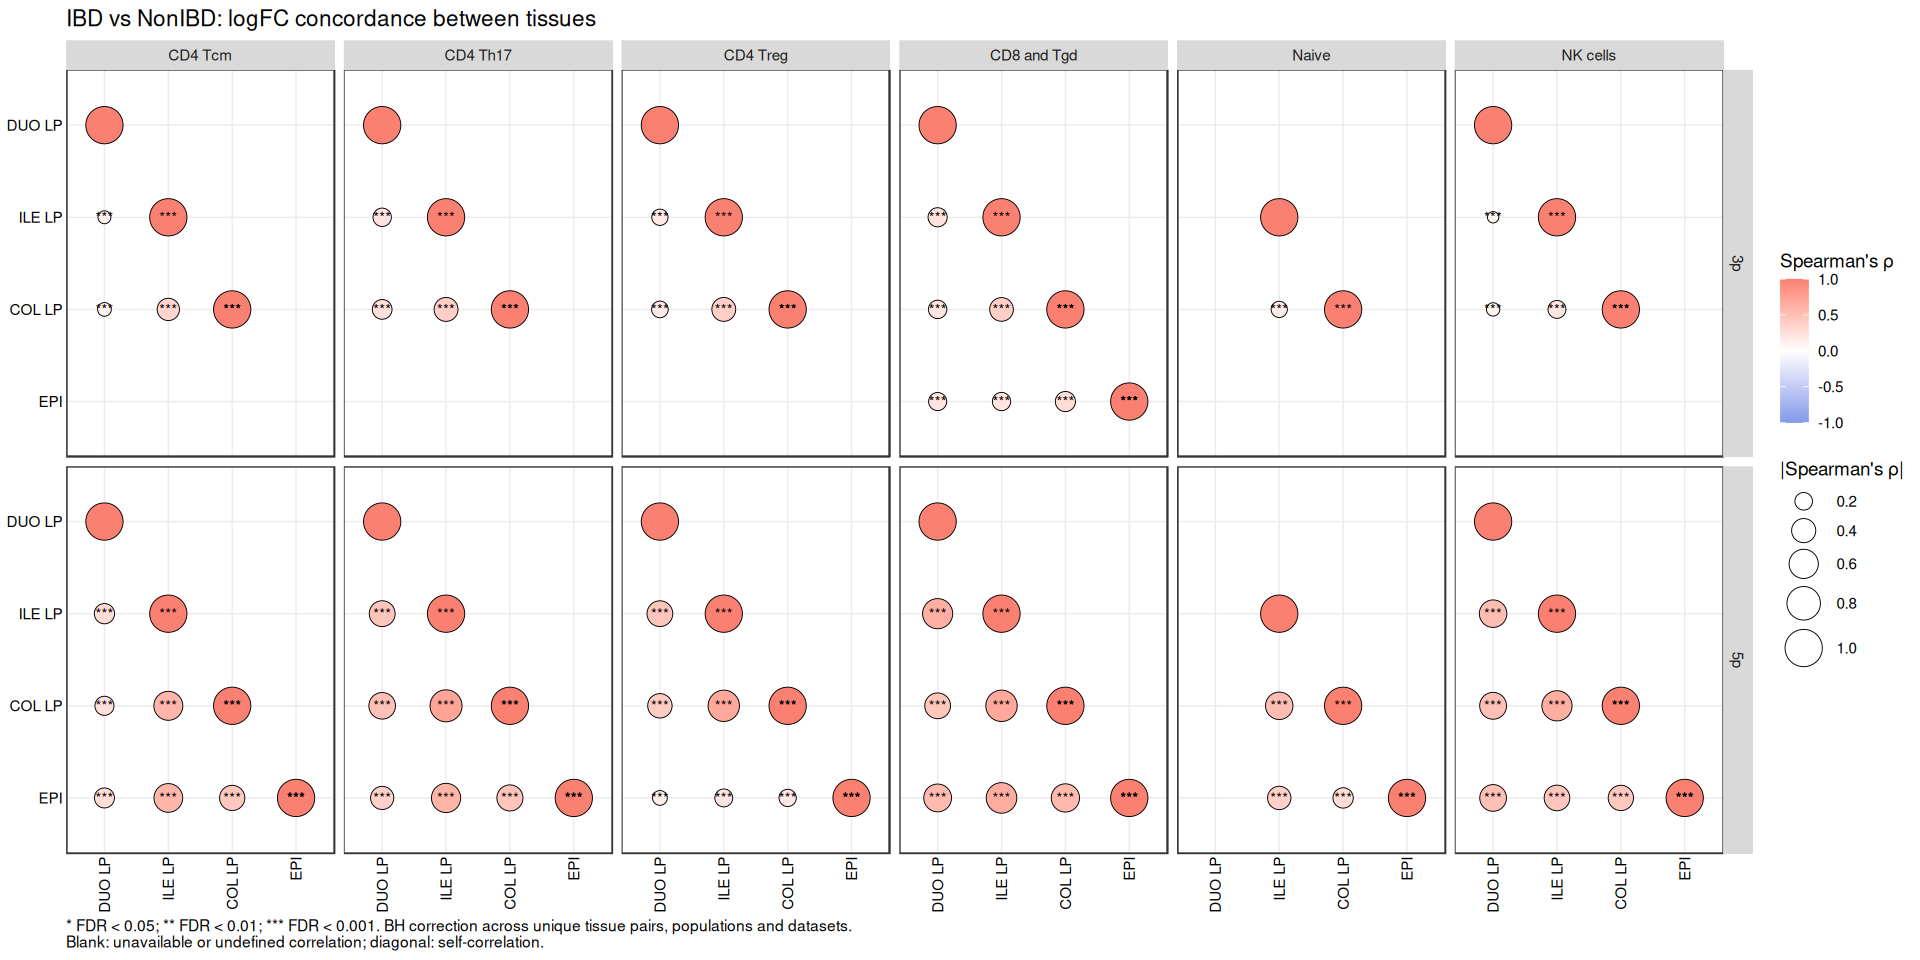

In [91]:
library(dplyr)
library(tidyr)
library(purrr)
library(ggplot2)

tissues <- c("DUO LP", "ILE LP", "COL LP", "EPI")

annotations <- c(
  "CD4 Tcm",
  "CD4 Th17",
  "CD4 Treg",
  "CD8 and Tgd",
  "Naive",
  "NK cells"
)

# Keep datasets separate; include all genes regardless of significance
tissue_data <- bind_rows(
  mutate(deg_3p, prime = "3p"),
  mutate(deg_5p, prime = "5p")
) %>%
  filter(
    test == "IBD_vs_NonIBD",
    tissue_layer %in% tissues,
    is.finite(logFC)
  )

# Each tissue pair is tested once
tissue_pairs <- as.data.frame(
  t(combn(tissues, 2)),
  stringsAsFactors = FALSE
)
names(tissue_pairs) <- c("tissue1", "tissue2")

# ---- Correlations ----
tissue_cor <- tissue_data %>%
  group_by(prime, annotation) %>%
  group_modify(~ {
    dat <- .x

    pmap_dfr(tissue_pairs, function(tissue1, tissue2) {

      paired <- inner_join(
        dat %>%
          filter(tissue_layer == tissue1) %>%
          select(gene, fc1 = logFC),
        dat %>%
          filter(tissue_layer == tissue2) %>%
          select(gene, fc2 = logFC),
        by = "gene",
        relationship = "one-to-one"
      )

      n_genes <- nrow(paired)
      rho <- p_value <- NA_real_

      if (
        n_genes >= 3L &&
        sd(paired$fc1) > 0 &&
        sd(paired$fc2) > 0
      ) {
        ct <- cor.test(
          paired$fc1,
          paired$fc2,
          method = "spearman",
          exact = FALSE
        )

        rho <- unname(ct$estimate)
        p_value <- ct$p.value
      }

      tibble(
        tissue1 = tissue1,
        tissue2 = tissue2,
        n_genes = n_genes,
        rho = rho,
        p_value = p_value
      )
    })
  }) %>%
  ungroup() %>%
  mutate(
    # Adjust unique comparisons only, before mirroring
    p_fdr = p.adjust(p_value, method = "BH")
  )

# Mirror correlations to create a symmetric matrix
mirrored <- tissue_cor %>%
  transmute(
    prime,
    annotation,
    tissue1 = tissue2,
    tissue2 = tissue1,
    n_genes,
    rho,
    p_value,
    p_fdr
  )

# Self-correlations: rho = 1, without significance testing
diagonal <- tissue_data %>%
  group_by(prime, annotation, tissue_layer) %>%
  summarise(
    n_genes = n(),
    variable = n_distinct(logFC) > 1L,
    .groups = "drop"
  ) %>%
  transmute(
    prime,
    annotation,
    tissue1 = tissue_layer,
    tissue2 = tissue_layer,
    n_genes,
    rho = if_else(n_genes >= 3L & variable, 1, NA_real_),
    p_value = NA_real_,
    p_fdr = NA_real_
  )

# Complete grid preserves missing tissue combinations
tissue_plot_df <- expand_grid(
  prime = c("3p", "5p"),
  annotation = annotations,
  tissue1 = tissues,
  tissue2 = tissues
) %>%
  left_join(
    bind_rows(tissue_cor, mirrored, diagonal),
    by = c("prime", "annotation", "tissue1", "tissue2")
  ) %>%
  mutate(
    abs_rho = abs(rho),
    stars = case_when(
      is.na(p_fdr) ~ "",
      p_fdr < 0.001 ~ "***",
      p_fdr < 0.01 ~ "**",
      p_fdr < 0.05 ~ "*",
      TRUE ~ ""
    ),
    tissue1 = factor(tissue1, levels = tissues),
    tissue2 = factor(tissue2, levels = rev(tissues)),
    annotation = factor(annotation, levels = annotations),
    prime = factor(prime, levels = c("3p", "5p"))
  )

# ---- Plot ----
p_tissues <- ggplot(
  tissue_plot_df,
  aes(x = tissue1, y = tissue2)
) +
  geom_point(
    data = filter(tissue_plot_df, is.finite(rho)),
    aes(size = abs_rho, fill = rho),
    shape = 21,
    colour = "black",
    stroke = 0.3
  ) +
  geom_text(
    aes(label = stars),
    size = 3,
    colour = "black"
  ) +
  facet_grid(prime ~ annotation, drop = FALSE) +
  scale_fill_gradient2(
    name = "Spearman's \u03c1",
    low = "#819BEB",
    mid = "white",
    high = "#FA8072",
    midpoint = 0,
    limits = c(-1, 1)
  ) +
  scale_size_area(
    name = "|Spearman's \u03c1|",
    max_size = 10,
    limits = c(0, 1),
    breaks = c(0.2, 0.4, 0.6, 0.8, 1)
  ) +
  scale_x_discrete(drop = FALSE) +
  scale_y_discrete(drop = FALSE) +
  guides(
    fill = guide_colourbar(order = 1),
    size = guide_legend(
      order = 2,
      override.aes = list(fill = "white", colour = "black")
    )
  ) +
  labs(
    x = NULL,
    y = NULL,
    title = "IBD vs NonIBD: logFC concordance between tissues",
    caption = paste(
      "* FDR < 0.05; ** FDR < 0.01; *** FDR < 0.001.",
      "BH correction across unique tissue pairs, populations and datasets.",
      "\nBlank: unavailable or undefined correlation; diagonal: self-correlation."
    )
  ) +
  theme_bw(base_size = 11) +
  theme(
    axis.text.x = element_text(
      angle = 90, hjust = 1, vjust = 0.5,
      colour = "black"
    ),
    axis.text.y = element_text(colour = "black"),
    axis.ticks = element_blank(),
    panel.grid.major = element_line(
      colour = "grey92", linewidth = 0.3
    ),
    panel.grid.minor = element_blank(),
    strip.background = element_rect(
      fill = "grey85", colour = NA
    ),
    panel.spacing = grid::unit(0.2, "cm"),
    plot.caption = element_text(hjust = 0, size = 9)
  )

options(repr.plot.width = 16, repr.plot.height = 8)

p_tissues

# Numeric results for unique tissue pairs
tissue_cor

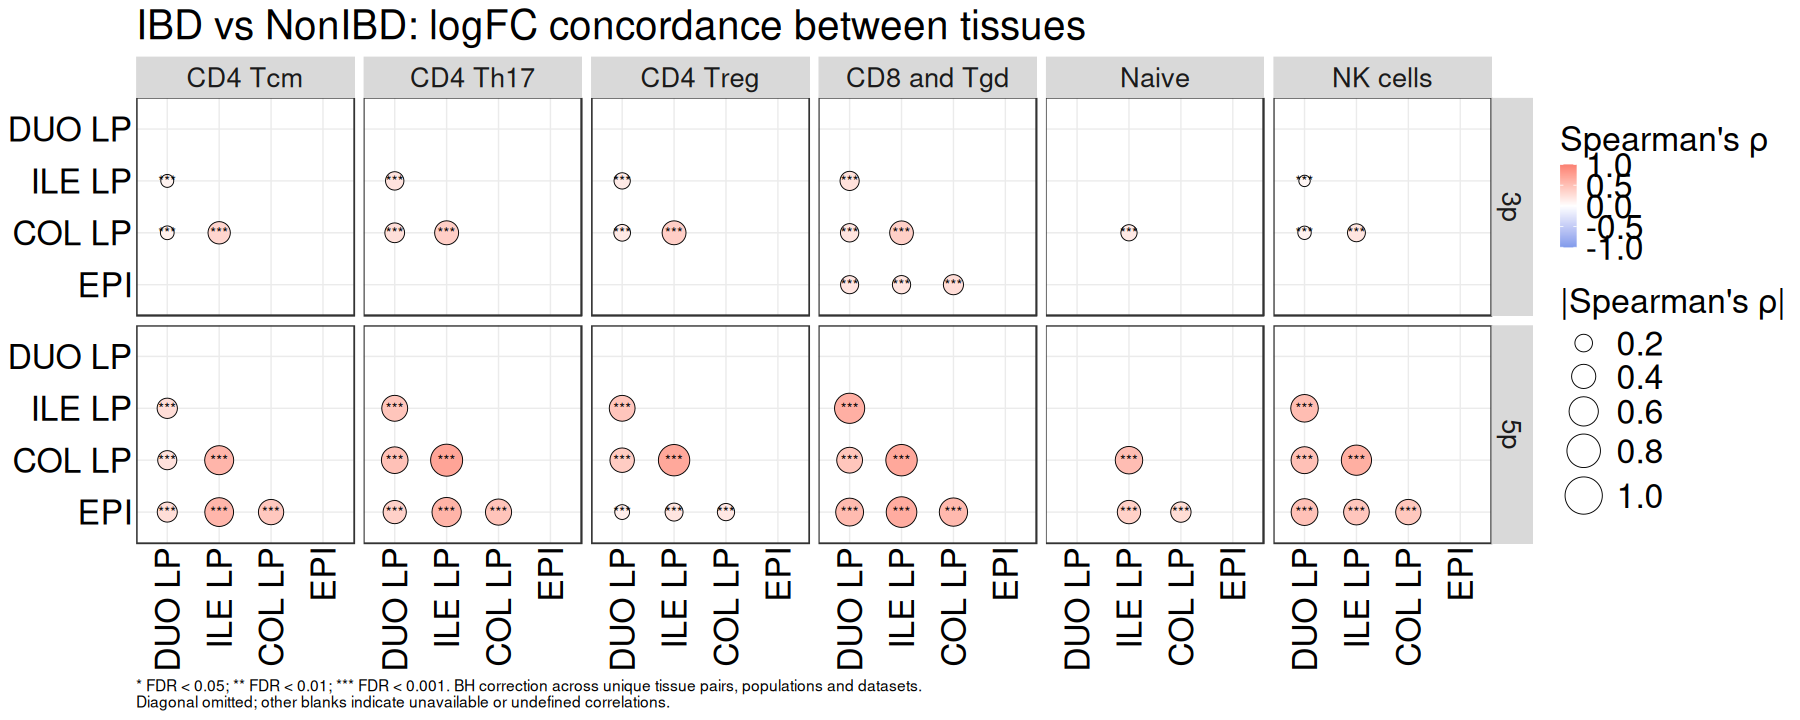

In [95]:
options(repr.plot.width = 15, repr.plot.height = 6)
## Without diagonal

tissue_plot_df <- tissue_plot_df %>%
  filter(as.character(tissue1) != as.character(tissue2))

# Update the existing plot and its point layer
p_tissues$data <- tissue_plot_df
p_tissues$layers[[1]]$data <- filter(tissue_plot_df, is.finite(rho))

p_tissues <- p_tissues +
  labs(
    caption = paste(
      "* FDR < 0.05; ** FDR < 0.01; *** FDR < 0.001.",
      "BH correction across unique tissue pairs, populations and datasets.",
      "\nDiagonal omitted; other blanks indicate unavailable or undefined correlations."
    )
  )

p_tissues + ggtheme()

In [96]:
library(dplyr)
library(tidyr)
library(purrr)

# ---- Read significant genes from the original files ----
read_significant <- function(root_dir, dataset) {

  expected <- expand_grid(
    tissue_layer = tissues,
    annotation = annotations
  ) %>%
    mutate(
      file = file.path(
        root_dir,
        tissue_layer,
        "IBD_vs_NonIBD",
        paste0(annotation, ".csv")
      )
    ) %>%
    filter(file.exists(file))

  pmap_dfr(
    expected,
    function(tissue_layer, annotation, file) {

      dat <- read.csv(
        file,
        check.names = FALSE,
        stringsAsFactors = FALSE
      )

      stopifnot(
        all(c("gene", "avg_log2FC", "p_val_adj") %in% names(dat))
      )

      dat <- dat %>%
        filter(
          !is.na(gene),
          nzchar(gene),
          !is.na(p_val_adj),
          p_val_adj < 0.05
        )

      if (anyDuplicated(dat$gene)) {
        stop("Duplicate genes in: ", file)
      }

      tibble(
        prime = rep(dataset, nrow(dat)),
        annotation = rep(annotation, nrow(dat)),
        tissue = rep(tissue_layer, nrow(dat)),
        gene = as.character(dat$gene),
        logFC = dat$avg_log2FC,
        p_adj = dat$p_val_adj
      )
    }
  )
}

sig_genes <- bind_rows(
  read_significant(dir_3p, "3p"),
  read_significant(dir_5p, "5p")
)

# ---- Find genes significant in both tissues ----
shared_sig_genes <- inner_join(
  sig_genes %>%
    rename(
      tissue1 = tissue,
      logFC_tissue1 = logFC,
      p_adj_tissue1 = p_adj
    ),
  sig_genes %>%
    rename(
      tissue2 = tissue,
      logFC_tissue2 = logFC,
      p_adj_tissue2 = p_adj
    ),
  by = c("prime", "annotation", "gene"),
  relationship = "many-to-many"
) %>%
  # Remove self-comparisons and mirrored duplicates
  filter(match(tissue1, tissues) < match(tissue2, tissues)) %>%
  mutate(
    test = "IBD_vs_NonIBD",
    direction = case_when(
      logFC_tissue1 > 0 & logFC_tissue2 > 0 ~ "Up in both",
      logFC_tissue1 < 0 & logFC_tissue2 < 0 ~ "Down in both",
      logFC_tissue1 * logFC_tissue2 < 0 ~ "Opposite directions",
      TRUE ~ "Zero or missing logFC"
    )
  ) %>%
  select(
    prime, annotation, test, tissue1, tissue2, gene,
    logFC_tissue1, logFC_tissue2,
    p_adj_tissue1, p_adj_tissue2, direction
  ) %>%
  arrange(prime, annotation, tissue1, tissue2, gene)

shared_sig_genes

write.csv(
  shared_sig_genes,
  "shared_significant_genes_between_tissues.csv",
  row.names = FALSE
)

prime,annotation,test,tissue1,tissue2,gene,logFC_tissue1,logFC_tissue2,p_adj_tissue1,p_adj_tissue2,direction
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
3p,CD4 Tcm,IBD_vs_NonIBD,ILE LP,COL LP,ENTPD1,2.2028836,1.6449523,7.879223e-04,3.818206e-02,Up in both
3p,CD4 Th17,IBD_vs_NonIBD,ILE LP,COL LP,CHN1,2.2958939,2.5947457,1.509788e-07,2.603723e-07,Up in both
3p,CD4 Th17,IBD_vs_NonIBD,ILE LP,COL LP,DAPK2,0.9869308,1.1442852,1.132495e-02,1.528981e-02,Up in both
3p,CD4 Th17,IBD_vs_NonIBD,ILE LP,COL LP,ENTPD1,1.9657712,2.0875265,2.296187e-04,1.818178e-04,Up in both
3p,CD4 Th17,IBD_vs_NonIBD,ILE LP,COL LP,GBP5,0.9767696,1.0856927,4.657868e-04,7.872542e-04,Up in both
3p,CD4 Th17,IBD_vs_NonIBD,ILE LP,COL LP,STAT1,1.0740410,1.1202390,2.834069e-02,3.037753e-02,Up in both
3p,CD4 Treg,IBD_vs_NonIBD,ILE LP,COL LP,IL1R2,0.9024617,1.3722867,1.565747e-02,4.536609e-07,Up in both
3p,CD4 Treg,IBD_vs_NonIBD,ILE LP,COL LP,IL2RA,0.8211552,0.8709624,8.772124e-03,1.219248e-02,Up in both
3p,CD4 Treg,IBD_vs_NonIBD,ILE LP,COL LP,PLEC,-1.0627564,-1.1118492,2.488736e-03,1.233365e-02,Down in both


In [102]:
shared_sig_genes  %>% dplyr::filter(tissue1 %in% c("ILE LP","COL LP") &
                                    tissue2 %in% c("ILE LP","COL LP") & 
                                   prime == "3p")  %>% 
mutate(gene_annot = paste(gene, annotation))  %>% 
pull(gene_annot)

[1] "ENTPD1 CD4 Tcm"    "CHN1 CD4 Th17"     "DAPK2 CD4 Th17"   
 [4] "ENTPD1 CD4 Th17"   "GBP5 CD4 Th17"     "STAT1 CD4 Th17"   
 [7] "IL1R2 CD4 Treg"    "IL2RA CD4 Treg"    "PLEC CD4 Treg"    
[10] "IGHG3 CD8 and Tgd"

In [108]:
shared_sig_genes  %>% dplyr::filter(tissue1 %in% c("ILE LP","COL LP") &
                                    tissue2 %in% c("ILE LP","COL LP") & 
                                   prime == "5p" )  %>% 
mutate(gene_annot = paste(gene, annotation))  %>% 
pull(gene_annot) 


[1] "AGR2 CD4 Tcm"        "GPX2 CD4 Tcm"        "IGHA1 CD4 Tcm"      
  [4] "IGHG1 CD4 Tcm"       "IGHG2 CD4 Tcm"       "IGKC CD4 Tcm"       
  [7] "LCN2 CD4 Tcm"        "NEAT1 CD4 Tcm"       "OLFM4 CD4 Tcm"      
 [10] "PTPN13 CD4 Tcm"      "SPINK4 CD4 Tcm"      "TFF3 CD4 Tcm"       
 [13] "ADTRP CD4 Th17"      "ANXA1 CD4 Th17"      "ARID5B CD4 Th17"    
 [16] "BATF CD4 Th17"       "BHLHE40 CD4 Th17"    "BIRC3 CD4 Th17"     
 [19] "CCR4 CD4 Th17"       "CD38 CD4 Th17"       "CHN1 CD4 Th17"      
 [22] "CTLA4 CD4 Th17"      "DUSP4 CD4 Th17"      "ENTPD1 CD4 Th17"    
 [25] "F5 CD4 Th17"         "FABP5 CD4 Th17"      "GBP2 CD4 Th17"      
 [28] "GBP5 CD4 Th17"       "GNLY CD4 Th17"       "GZMH CD4 Th17"      
 [31] "HIST1H1B CD4 Th17"   "IGFBP4 CD4 Th17"     "IGHA1 CD4 Th17"     
 [34] "IGHG1 CD4 Th17"      "IGHG2 CD4 Th17"      "IGKC CD4 Th17"      
 [37] "IGLC3 CD4 Th17"      "IL6ST CD4 Th17"      "LCN2 CD4 Th17"      
 [40] "LYST CD4 Th17"       "MATK CD4 Th17"       "MSC CD4 Th17"       
 [43] "NEAT1 CD4 Th17"      "OASL CD4 Th17"       "PTPN13 CD4 Th17"    
 [46] "RNF19A CD4 Th17"     "RNF213 CD4 Th17"     "S100A10 CD4 Th17"   
 [49] "SESN3 CD4 Th17"      "SH2D1A CD4 Th17"     "SPINK4 CD4 Th17"    
 [52] "STAT1 CD4 Th17"      "TFF3 CD4 Th17"       "TOX2 CD4 Th17"      
 [55] "TSHZ2 CD4 Th17"      "ZEB2 CD4 Th17"       "ARID5B CD4 Treg"    
 [58] "CYTOR CD4 Treg"      "FRMD4B CD4 Treg"     "IGHG1 CD4 Treg"     
 [61] "IGHG2 CD4 Treg"      "IGLC3 CD4 Treg"      "IL1R1 CD4 Treg"     
 [64] "IL1R2 CD4 Treg"      "LCN2 CD4 Treg"       "NEAT1 CD4 Treg"     
 [67] "PLA2G2A CD4 Treg"    "RNF213 CD4 Treg"     "RTKN2 CD4 Treg"     
 [70] "SAT1 CD4 Treg"       "SOX4 CD4 Treg"       "SPINK4 CD4 Treg"    
 [73] "TFF3 CD4 Treg"       "ZEB2 CD4 Treg"       "GBP2 CD8 and Tgd"   
 [76] "IGHA1 CD8 and Tgd"   "IGHG1 CD8 and Tgd"   "IGHG2 CD8 and Tgd"  
 [79] "IGKC CD8 and Tgd"    "IGLC3 CD8 and Tgd"   "ITLN1 CD8 and Tgd"  
 [82] "LCN2 CD8 and Tgd"    "NEAT1 CD8 and Tgd"   "OLFM4 CD8 and Tgd"  
 [85] "PIGR CD8 and Tgd"    "PIK3R1 CD8 and Tgd"  "PLA2G2A CD8 and Tgd"
 [88] "RNF213 CD8 and Tgd"  "SPINK1 CD8 and Tgd"  "SPINK4 CD8 and Tgd" 
 [91] "STAT1 CD8 and Tgd"   "TFF3 CD8 and Tgd"    "GBP2 NK cells"      
 [94] "IGHA1 NK cells"      "IGLC2 NK cells"      "LYST NK cells"      
 [97] "PDE4D NK cells"      "SPINK4 NK cells"     "GPX2 Naive"         
[100] "IGHA1 Naive"         "IGHG1 Naive"         "IGHG2 Naive"        
[103] "MUC2 Naive"          "NEAT1 Naive"         "OLFM4 Naive"        
[106] "REG1A Naive"         "SPINK4 Naive"

In [109]:
ls()

[1] "aggexp_3p"             "aggexp_5p"             "annotations"          
 [4] "annots"                "celltypist"            "colour_max"           
 [7] "comparisons"           "cor_plot_df"           "cor_results"          
[10] "counts_all"            "deg_3p"                "deg_5p"               
[13] "deg_all_tissues_deseq" "deg_counts"            "diagonal"             
[16] "dir_3p"                "dir_5p"                "ds_sub"               
[19] "duplicates"            "files"                 "genes"                
[22] "genes_filt_3p"         "genes_filt_5p"         "ggtheme"              
[25] "gut_allt_3p"           "gut_allt_5p"           "jobs"                 
[28] "keep_labels"           "keep_samples"          "label_freq"           
[31] "label_genes"           "label_keys"            "loaded"               
[34] "matched_genes"         "md"                    "md_5p_celltypist"     
[37] "md_to_join"            "metadata_all"          "mirrored"             
[40] "missing_labels"        "out_dir"               "p"                    
[43] "p_scatter"             "p_th17"                "p_tissues"            
[46] "plot_df"               "pt_3p"                 "read_results"         
[49] "read_significant"      "result_dirs"           "rho_limit"            
[52] "sample_counts"         "sample_counts_wide"    "scatter_df"           
[55] "scatter_long"          "scimilarity"           "shared_sig_genes"     
[58] "sig_genes"             "test_name"             "test_status"          
[61] "test_status_wide"      "tests"                 "th17_plot_df"         
[64] "tissue_cor"            "tissue_data"           "tissue_layers"        
[67] "tissue_pairs"          "tissue_plot_df"        "tissues"              
[70] "tl"

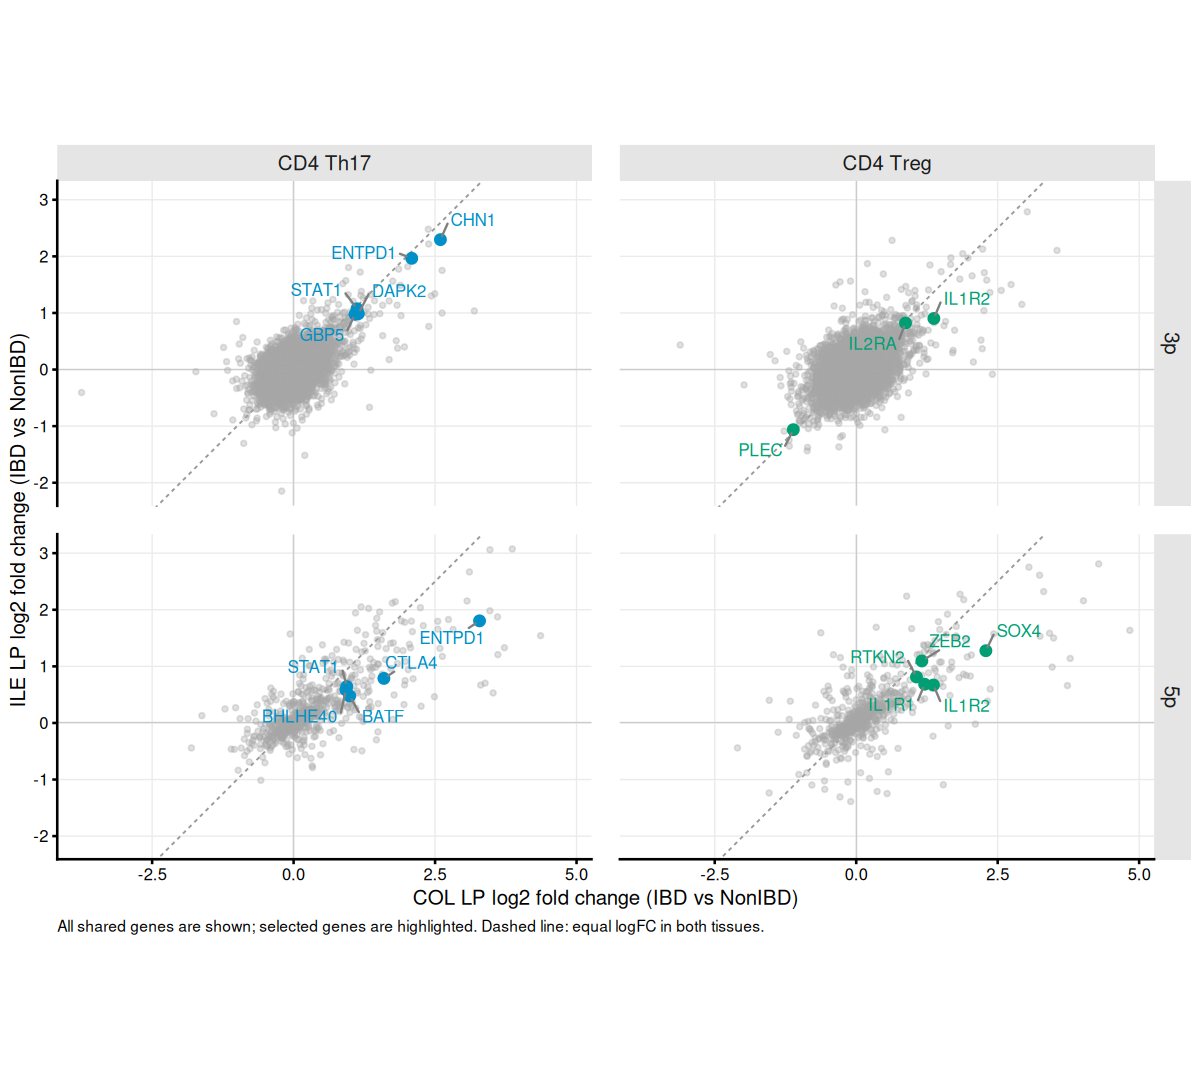

In [106]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(ggrepel)

# ---- Genes to label ----
label_genes <- bind_rows(
  tibble(
    prime = "3p",
    annotation = "CD4 Th17",
    gene = c("CHN1", "DAPK2", "ENTPD1", "GBP5", "STAT1")
  ),
  tibble(
    prime = "3p",
    annotation = "CD4 Treg",
    gene = c("IL1R2", "IL2RA", "PLEC")
  ),
  tibble(
    prime = "5p",
    annotation = "CD4 Th17",
    gene = c("BATF", "BHLHE40", "ENTPD1", "CTLA4", "STAT1")
  ),
  tibble(
    prime = "5p",
    annotation = "CD4 Treg",
    gene = c("IL1R1", "IL1R2", "RTKN2", "SOX4", "ZEB2")
  )
)

# ---- Select data ----
scatter_long <- bind_rows(
  mutate(deg_3p, prime = "3p"),
  mutate(deg_5p, prime = "5p")
) %>%
  filter(
    test == "IBD_vs_NonIBD",
    annotation %in% c("CD4 Th17", "CD4 Treg"),
    tissue_layer %in% c("COL LP", "ILE LP"),
    is.finite(logFC)
  ) %>%
  select(prime, annotation, gene, tissue_layer, logFC)

# Prevent duplicate genes from creating ambiguous matches
duplicates <- scatter_long %>%
  count(prime, annotation, gene, tissue_layer) %>%
  filter(n > 1L)

if (nrow(duplicates) > 0L) {
  stop("Duplicate gene entries found within a dataset/population/tissue.")
}

# ---- Pair COL and ILE logFCs ----
scatter_df <- scatter_long %>%
  pivot_wider(
    names_from = tissue_layer,
    values_from = logFC
  ) %>%
  filter(
    is.finite(`COL LP`),
    is.finite(`ILE LP`)
  ) %>%
  left_join(
    mutate(label_genes, selected = TRUE),
    by = c("prime", "annotation", "gene")
  ) %>%
  mutate(
    selected = coalesce(selected, FALSE),
    prime = factor(prime, levels = c("3p", "5p")),
    annotation = factor(
      annotation,
      levels = c("CD4 Th17", "CD4 Treg")
    )
  )

# Report requested labels missing from the paired data
missing_labels <- anti_join(
  label_genes,
  scatter_df,
  by = c("prime", "annotation", "gene")
)

if (nrow(missing_labels) > 0L) {
  message("These requested genes lack paired finite logFCs:")
  print(missing_labels)
}

# ---- Plot ----
p_scatter <- ggplot(
  scatter_df,
  aes(x = `COL LP`, y = `ILE LP`)
) +
  geom_hline(
    yintercept = 0,
    colour = "grey80",
    linewidth = 0.3
  ) +
  geom_vline(
    xintercept = 0,
    colour = "grey80",
    linewidth = 0.3
  ) +
  geom_abline(
    slope = 1,
    intercept = 0,
    linetype = "dashed",
    colour = "grey60",
    linewidth = 0.4
  ) +
  geom_point(
    colour = "grey65",
    alpha = 0.35,
    size = 1
  ) +
  geom_point(
    data = filter(scatter_df, selected),
    aes(colour = annotation),
    size = 2.5
  ) +
  geom_text_repel(
    data = filter(scatter_df, selected),
    aes(label = gene, colour = annotation),
    seed = 123,
    size = 3.5,
    max.overlaps = Inf,
    box.padding = 0.5,
    point.padding = 0.3,
    min.segment.length = 0,
    segment.colour = "grey50",
    show.legend = FALSE
  ) +
  facet_grid(prime ~ annotation) +
  scale_colour_manual(
    values = c(
      "CD4 Th17" = "#008FC7",
      "CD4 Treg" = "#009E73"
    ),
    guide = "none"
  ) +
  coord_equal() +
  labs(
    x = "COL LP log2 fold change (IBD vs NonIBD)",
    y = "ILE LP log2 fold change (IBD vs NonIBD)",
    caption = paste(
      "All shared genes are shown; selected genes are highlighted.",
      "Dashed line: equal logFC in both tissues."
    )
  ) +
  theme_classic(base_size = 12) +
  theme(
    panel.grid.major = element_line(
      colour = "grey92",
      linewidth = 0.3
    ),
    strip.background = element_rect(
      fill = "grey90",
      colour = NA
    ),
    strip.text = element_text(size = 12),
    panel.spacing = grid::unit(0.6, "cm"),
    plot.caption = element_text(hjust = 0, size = 9)
  )

options(repr.plot.width = 10, repr.plot.height = 9)

p_scatter

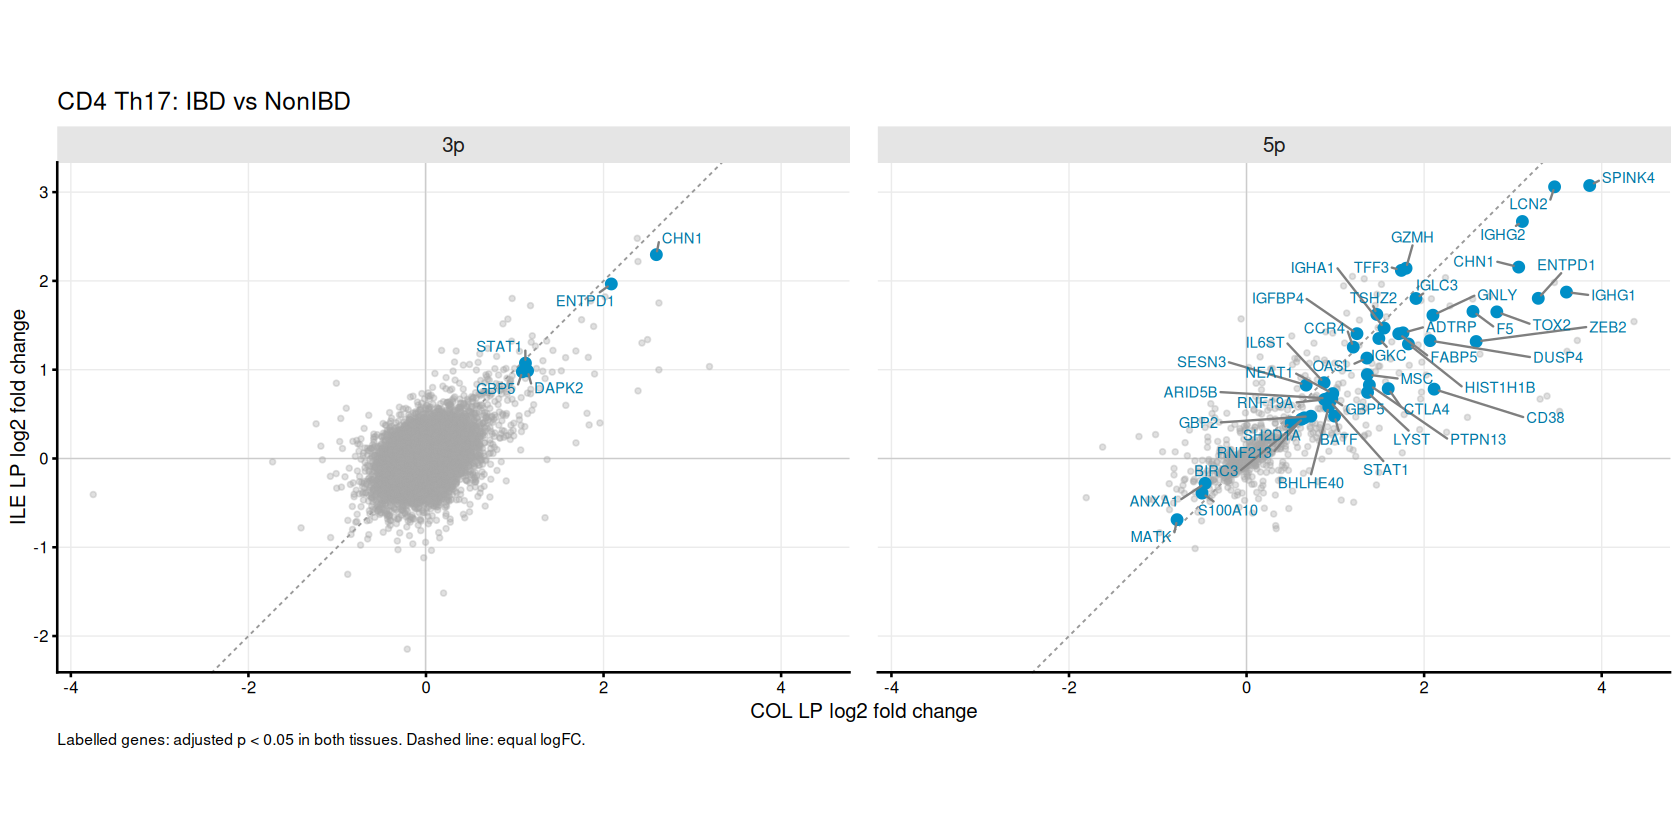

In [107]:
library(dplyr)
library(ggplot2)
library(ggrepel)

# Genes significant in both COL LP and ILE LP
label_keys <- shared_sig_genes %>%
  filter(
    annotation == "CD4 Th17",
    test == "IBD_vs_NonIBD",
    (tissue1 == "COL LP" & tissue2 == "ILE LP") |
      (tissue1 == "ILE LP" & tissue2 == "COL LP")
  ) %>%
  transmute(
    prime = as.character(prime),
    gene,
    significant_both = TRUE
  ) %>%
  distinct()

# Keep all shared Th17 genes as the background
th17_plot_df <- scatter_df %>%
  filter(annotation == "CD4 Th17") %>%
  select(prime, gene, `COL LP`, `ILE LP`) %>%
  mutate(prime = as.character(prime)) %>%
  left_join(label_keys, by = c("prime", "gene")) %>%
  mutate(
    significant_both = coalesce(significant_both, FALSE),
    prime = factor(prime, levels = c("3p", "5p"))
  )

p_th17 <- ggplot(
  th17_plot_df,
  aes(x = `COL LP`, y = `ILE LP`)
) +
  geom_hline(
    yintercept = 0,
    colour = "grey80",
    linewidth = 0.3
  ) +
  geom_vline(
    xintercept = 0,
    colour = "grey80",
    linewidth = 0.3
  ) +
  geom_abline(
    slope = 1,
    intercept = 0,
    linetype = "dashed",
    colour = "grey60",
    linewidth = 0.4
  ) +
  geom_point(
    colour = "grey65",
    alpha = 0.35,
    size = 1
  ) +
  geom_point(
    data = filter(th17_plot_df, significant_both),
    colour = "#008FC7",
    size = 2.5
  ) +
  geom_text_repel(
    data = filter(th17_plot_df, significant_both),
    aes(label = gene),
    colour = "#0076A3",
    seed = 123,
    size = 3,
    max.overlaps = Inf,
    max.time = 3,
    box.padding = 0.4,
    point.padding = 0.25,
    min.segment.length = 0,
    segment.colour = "grey50"
  ) +
  facet_wrap(~ prime, nrow = 1, drop = FALSE) +
  coord_equal() +
  labs(
    title = "CD4 Th17: IBD vs NonIBD",
    x = "COL LP log2 fold change",
    y = "ILE LP log2 fold change",
    caption = paste(
      "Labelled genes: adjusted p < 0.05 in both tissues.",
      "Dashed line: equal logFC."
    )
  ) +
  theme_classic(base_size = 12) +
  theme(
    panel.grid.major = element_line(
      colour = "grey92",
      linewidth = 0.3
    ),
    strip.background = element_rect(
      fill = "grey90",
      colour = NA
    ),
    strip.text = element_text(size = 12),
    panel.spacing = grid::unit(0.6, "cm"),
    plot.caption = element_text(hjust = 0, size = 9)
  )

options(repr.plot.width = 14, repr.plot.height = 7)

p_th17

In [99]:
shared_sig_genes  %>% group_by(annotation, tissue1, tissue2, gene, direction)  %>% tally()  %>% arrange(desc(n))

annotation,tissue1,tissue2,gene,direction,n
<chr>,<chr>,<chr>,<chr>,<chr>,<int>
CD4 Th17,ILE LP,COL LP,CHN1,Up in both,2
CD4 Th17,ILE LP,COL LP,ENTPD1,Up in both,2
CD4 Th17,ILE LP,COL LP,GBP5,Up in both,2
CD4 Th17,ILE LP,COL LP,STAT1,Up in both,2
CD4 Treg,ILE LP,COL LP,IL1R2,Up in both,2
CD4 Tcm,COL LP,EPI,NEAT1,Up in both,1
CD4 Tcm,ILE LP,COL LP,AGR2,Up in both,1
CD4 Tcm,ILE LP,COL LP,ENTPD1,Up in both,1
CD4 Tcm,ILE LP,COL LP,GPX2,Up in both,1


# SessionInfo

In [97]:
sessionInfo()

R version 4.5.2 (2025-10-31)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Europe/Prague
tzcode source: system (glibc)

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] purrr_1.2.0           furrr_0.3.1           future_1.68.0        
 [4] ggrepel_0.9.6         rstatix_0.7.2         ggpubr_0.6.0         
 [7] ggplot2_4.0.

In [98]:
ls()

[1] "aggexp_3p"               "aggexp_5p"              
 [3] "aggexp_5p_filt"          "annotation_labels"      
 [5] "annotations"             "annots"                 
 [7] "colour_max"              "comparisons"            
 [9] "counts_all"              "deg_all_tissues_deseq"  
[11] "deg_counts"              "deg_counts_inflammation"
[13] "ds_sub"                  "file_table"             
[15] "files"                   "genes"                  
[17] "genes_filt_3p"           "genes_filt_5p"          
[19] "ggtheme"                 "gut_allt_3p"            
[21] "inflammation_md"         "input_3p"               
[23] "input_5p"                "j"                      
[25] "job_results"             "jobs"                   
[27] "jobs_inflammation"       "keep_samples"           
[29] "loaded"                  "make_inflammation_plot" 
[31] "md"                      "md_5p_new"              
[33] "md_to_join"              "metadata_all"           
[35] "missing_results"         "out_dir"                
[37] "p"                       "p_col"                  
[39] "p_column"                "p_cutoff"               
[41] "p_ile"                   "plot_data"              
[43] "plot_df"                 "pt_3p"                  
[45] "result_dirs"             "run_inflammation_job"   
[47] "test_name"               "test_status"            
[49] "test_status_wide"        "test_use"               
[51] "tissue_layers"           "tissues"                
[53] "tl"                      "workers"